# DOKUMEN PROPOSAL PROYEK DAN DESAIN TEKNIS



## Sistem Pendukung Keputusan Pemeliharaan Berbasis Prediksi Kegagalan Bottom Hole Assembly pada Operasi Pengeboran Minyak dan Gas



### KONTROL DOKUMEN

| Item | Nilai |
|---|---|
| Versi | 4.0, yaitu perakitan V10 (15 Oktober 2026) |
| Status | Proposal dan desain teknis pada tahap prototipe |
| Lingkup | Alat pemeliharaan berbasis prediksi (advisori / berpengawas manusia) |
| Sumber data | Lapangan Volve (Equinor, terbuka) dan 4 dataset eksternal terverifikasi |
| Susunan bab | Delapan bab teknis (Bab 1 sampai Bab 8) dirakit dari dokumen kerja V10 |
| Riwayat pengembangan | Dirujuk ke `CHANGELOG.md` dan Lampiran A (arsip bukti) |
| Catatan versi | Versi ini hanya memuat solusi aktual. Seluruh riwayat kegagalan kampanye lama dipindah ke `CHANGELOG.md` agar proposal terbaca sebagai rencana solusi, bukan post-mortem. Berkas lama disimpan sebagai `*.v3_arsip.*`. |



### DAFTAR ISI

**BAGIAN A: Tingkat Bisnis dan Eksekutif**

1. Ringkasan Eksekutif
2. Latar Belakang
3. Rumusan Masalah
4. Tujuan Proyek
5. Usulan Solusi
6. Alur Kerja Sistem
7. Skenario Penggunaan dan Perjalanan Pengguna

**BAGIAN B: Tingkat Solusi dan Teknis (delapan bab V10)**

- Bab 1: Ruang Lingkup dan Tiga Angka (7 Engine, 11 Klaim, 27 Head)
- Bab 2: Alasan Pemilihan Tiap Engine (Berbasis Bukti)
- Bab 3: Data, yaitu Apa yang Dipakai dan Perannya
- Bab 4: Labeling untuk Head ML, Fitur, dan Protokol LOWO
- Bab 5: Metode Statistik
- Bab 6: Rule, Persistence, dan Workflow Hibrida
- Bab 7: Apa yang Dideteksi Tiap Engine dan Seberapa Bekerja (Hasil A/B/C)
- Bab 8: Peta Alat, Hitungan Alat, dan Cara Membacanya

**BAGIAN C: Kemampuan, Risiko, dan Rencana**

16. Risiko dan Keterbatasan
17. Rencana Penerapan dan Implementasi
18. Lini Masa
19. Kriteria Keberhasilan (termasuk Sitasi Dokumen Primer)

---



# BAGIAN A: TINGKAT BISNIS DAN EKSEKUTIF



## 1. Ringkasan Eksekutif

Proyek ini membangun **alat pemeliharaan berbasis prediksi** untuk mendeteksi kerusakan dan disfungsi *Bottom Hole Assembly* (BHA) selama operasi pengeboran. Alat ini dirancang sebagai **kelas advisori / berpengawas manusia**: ia memberi peringatan dini, skor kondisi, dan dasbor tren kepada insinyur pengeboran, sementara keputusan operasional tetap pada manusia.

Daripada memaksakan satu model pembelajaran mesin untuk semua jenis kegagalan, alat ini menyusun **tujuh mesin deteksi yang berbeda tugas**, masing-masing memakai metode yang paling cocok untuk tugasnya: deteksi berbasis aturan, deteksi statistik, *persistence*, pembelajaran mesin terawasi, dan mesin hibrida. Setiap mesin dinilai pada tiga lapisan (A: apakah deteksi bekerja; B: apakah bernilai pemeliharaan; C: apakah cukup tepercaya untuk dipakai), lalu dipasang pada tingkat pemakaian yang sesuai dengan kekuatan buktinya.

**Tiga angka pengikat (dijelaskan tegas pada Bab 1):** alat ini mengoperasikan **7 engine**, menilai **11 klaim**, dan merakit **27 head**. Ketiganya berjenjang, yaitu 7 ⊂ 11 ⊂ 27. *7 engine* adalah tujuh kelas hal yang dideteksi (unit fisis, yaitu "apa yang rusak"). *11 klaim* adalah sebelas pertanyaan tugas terpisah yang dinilai, karena deteksi-kondisi dan prediksi-onset adalah tugas berbeda dengan label dan baseline berbeda (3 engine bertugas tunggal, 4 engine bertugas ganda, sehingga 3 × 1 + 4 × 2 = 11). *27 head* adalah dua puluh tujuh varian metode yang benar-benar dievaluasi, yaitu tiap klaim dijawab dengan beberapa cara (rule, persistence, statistik, RF, hibrida) dan tiap cara diukur sendiri (4+4+4+6+4+2+3 = 27). Menjumlahkan 7 + 11 + 27 adalah salah kategori, karena ketiganya level berbeda dari objek yang sama.

**Status kemampuan ketujuh mesin (per 15 Oktober 2026):**

| Tingkat pemakaian | Jumlah mesin | Keterangan |
|---|---|---|
| Alarm otomatis kritis | **0** | Belum ada mesin yang memenuhi syarat alarm palsu rendah terukur; tidak diklaim |
| Peringatan berpengawas manusia (terbukti) | **3** | shk, stuck, hyd: memberi peringatan beberapa menit sebelum kejadian pada sumur terkalibrasi |
| Peringatan berpengawas manusia (bersyarat) | **2** | vib, ssi: menunggu pengukuran alarm palsu lanjutan |
| Pemantauan tren / skor | **2** | bit_wear (konfirmasi status) dan tool_wear (indeks keausan) |
| **Punya peran dalam alat** | **7 dari 7** | Tidak ada mesin dibuang; tiap mesin punya batas pemakaian tertulis |

Riwayat pengembangan, termasuk seluruh kampanye evaluasi beserta hasil yang tidak memenuhi ambang, tercatat transparan pada `CHANGELOG.md` dan arsip Lampiran A. Angka penutup kampanye lama dipertahankan apa adanya dan tidak dicabut.



## 2. Latar Belakang

Kegagalan BHA, yang mencakup *stick-slip*, *whirl*, *bit bounce*, *differential sticking*, dan keausan komponen, menyebabkan non-productive time (NPT) yang mahal, kerusakan peralatan, dan risiko keselamatan. Deteksi dini memungkinkan penyesuaian parameter pengeboran atau penarikan string sebelum kerusakan berlanjut.

Data pengeboran modern (WITSML) mencakup sensor permukaan (torsi, RPM, WOB, hookload, tekanan standpipe, aliran lumpur) dan sensor *Measurement-While-Drilling* (MWD) di bawah permukaan. Meskipun demikian, sebagian besar sinyal disfungsi bersifat lokal di bawah permukaan dan teredam sebelum mencapai permukaan, sehingga deteksi dari sensor permukaan saja memiliki batas yang harus dinyatakan terbuka.



## 3. Rumusan Masalah

1. Jenis kegagalan BHA mana yang dapat dideteksi dari data pengeboran yang tersedia, dan dengan tingkat keandalan apa?
2. Metode apa (aturan, statistik, persistence, atau pembelajaran mesin) yang paling cocok untuk tiap jenis kegagalan, mengingat tiap kegagalan mengerjakan tugas yang berbeda?
3. Seberapa tepercaya hasil deteksi untuk dipakai dalam keputusan pemeliharaan, dan pada tingkat apa (tren, peringatan berpengawas manusia, atau alarm otomatis)?
4. Bagaimana memisahkan klaim yang didukung bukti dari klaim yang berlebihan, agar alat dapat dipakai tanpa menyesatkan pengguna?



## 4. Tujuan Proyek

1. Membangun alat pemeliharaan berbasis prediksi yang mendeteksi minimal tiga jenis kerusakan/disfungsi BHA dari data nyata.
2. Menetapkan tingkat pemakaian yang jujur untuk tiap mesin deteksi (tren, peringatan berpengawas manusia, atau alarm otomatis) berdasarkan lapisan bukti A/B/C.
3. Menyatakan batas pemakaian dan ketidakpastian setiap mesin secara terbuka.
4. Menyusun prototipe advisori yang siap diuji pada sumur terkalibrasi tanpa koneksi langsung ke sistem rig.



## 5. Usulan Solusi

Solusi berupa **susunan banyak mesin deteksi yang berbeda tugas**, dipilih per jenis kegagalan. Rincian konstruksi tiap kelas ada pada Bab 1 sampai Bab 6; hasil evaluasi dan tier pemakaian ada pada Bab 7 dan Bab 8.

| Jenis mesin | Peran | Contoh penerapan |
|---|---|---|
| Deteksi berbasis aturan | Kondisi abnormal sederhana dan konsisten | tekanan tidak normal, ambang torsi |
| Deteksi statistik (median/MAD, change-point, skor-z) | Deteksi perubahan pola operasi | indikasi dini hidraulik, perubahan regime keausan |
| Persistence (status-quo) | Konfirmasi status dan pembanding jujur | keadaan berlanjut dari kondisi sebelumnya |
| Pembelajaran mesin terawasi | Peringatan dini dengan lead-time | getaran lateral, stick-slip |
| Mesin hibrida (aturan + statistik + ML) | Arsitektur per mesin | gabungan lapisan dasar dan prediksi |

Karena tiap kelas kegagalan mengerjakan tugas berbeda (deteksi anomali, deteksi kondisi, diagnosis, atau prediksi kejadian mendatang), tidak semua mesin memerlukan ambang yang identik. Sebuah aturan sederhana yang mendeteksi tekanan abnormal secara konsisten dapat sangat berguna tanpa mengalahkan model ML pada ambang *lift* 1,5; demikian pula metode statistik dapat membantu pemeriksaan peralatan meskipun belum mampu memprediksi tanggal kejadian. Keputusan akhir pemeliharaan tetap pada manusia.



## 6. Alur Kerja Sistem

```
Data pengeboran (WITSML + MWD)
        |
Prapemrosesan (pembersihan, imputasi, jendela waktu)
        |
Tujuh mesin deteksi (aturan / statistik / persistence / ML / hibrida)
        |
Penilaian berlapis A / B / C per mesin
        |
Lapisan keputusan: konfirmasi status | peringatan berpengawas manusia | dasbor tren
        |
Keputusan insinyur pengeboran (manusia)
```



## 7. Skenario Penggunaan dan Perjalanan Pengguna

1. **Konfirmasi status otomatis.** Sistem menampilkan status kondisi terkini (normal, disfungsi terdeteksi) berdasarkan aturan dan persistence, tanpa perlu pelatihan.
2. **Peringatan berpengawas manusia.** Saat mesin peringatan mendeteksi pola yang mendahului kondisi memburuk, sistem menampilkan peringatan beserta waktu peringatan dan tingkat keyakinan; insinyur menindaklanjuti.
3. **Dasbor tren.** Skor kondisi dan indeks keausan ditampilkan sebagai tren sepanjang sumur untuk pemantauan, bukan sebagai keputusan otomatis.
4. **Keputusan manusia.** Seluruh keputusan pengeboran/pemeliharaan tetap pada insinyur; alat tidak menjadi satu-satunya dasar penghentian operasi.

---



# BAGIAN B: TINGKAT SOLUSI DAN TEKNIS



## Bab 1: Ruang Lingkup dan Tiga Angka: 7 Engine, 11 Klaim, 27 Head


Task: `t_cf741053` [PM · System Architect · Tech Lead] · Board: `capstone-v10-proposal` · Tanggal: 2026-10-14 (WIB)
Peran: PM + System Architect, yaitu menetapkan kerangka proposal teknis V10 berdasar keluhan operator.
Status: **KERANGKA MENGIKAT** untuk 6 bab tim (D1 · R1 · E_ML · E_STAT · E_RULE · EVAL) dan perakitan akhir.
Proposal baru = dokumen V10 terpisah; V9_PM1 tetap arsitektur internal-engine dan tidak diedit.

KELUHAN OPERATOR (2026-10-14, VERBATIM INTI): proposal teknis "jelek, isinya dangkal".
Yang HILANG dan wajib ada: (a) daftar 7 hal yang dideteksi; (b) engine mana yang bekerja &
cara kerjanya; (c) alasan KENAPA tiap engine dipilih (bukti, bukan selera); (d) peran DATA;
(e) labeling ML / statistik / workflow hybrid; (f) penjelasan TEGAS angka 7 vs 11 (dan 27 head).

SUMBER ANGKA (semua dari dokumen/kode/JSON sumber, yakni nol angka karangan):
`code/v9_i1_pipeline.py` (REGISTRY §1, baris 74–287, yakni **dibaca & DIJALANKAN**, bukan ditranskrip) ·
`docs/V9_PM1_ARCHITECTURE.md` (§2 spesifikasi 7 engine, §3 S1–S9) ·
`docs/V9_PM2_VERDICT.md` §e (tabel tier per klaim) ·
`docs/V8_M1_CAPABILITY_MAP.md` · `docs/V9_EVAL_A/B/C` (EA-1/EB-1/EC-1) · `docs/V9_I1_INTEGRATION.md` §2.

> **Riset pendahuluan: `scientific-critical-thinking`**: tiga angka 7/11/27 dipisah sebagai
> tiga UNIT berbeda (kelas kerusakan vs estimand/tugas vs varian metode terukur), bukan tiga
> label untuk hal yang sama; status "belum dijalankan/tidak tersedia" DIPERTAHANKAN sebagai
> klaim (kejujuran ≠ penghapusan); setiap bab diberi falsifier konsistensi ke REGISTRY kode.
> **Riset pendahuluan: `statistical-analysis`**: unit analisis ditetapkan = **klaim** (11), bukan
> engine (7) maupun head (27); baseline wajib relevan per tugas (deteksi-kondisi vs prediksi-onset
> punya baseline & label berbeda); FAR dibaca pada skala aslinya (rig = jendela/24 jam, bengkel =
> menit); fold UNDERPOWERED (<30 positif) dilabeli, tidak dihitung mayoritas; AUPRC/lift dilarang
> dirata-ratakan antar kelas (plafon lift beda per prevalensi).
> **Riset pendahuluan: `verification-mandatory`**: angka 7/11/27 diperoleh dengan **menjalankan
> modul** `v9_i1_pipeline.py` (IMPORT OK) lalu di-cross-check ke 3 dokumen evaluator (EA-1/EB-1/EC-1)
> dan tabel 11 baris PM2 §e; daftar "belum diverifikasi" ditulis eksplisit di §6.
> **Riset pendahuluan: `sequentialthinking`** (5 pikiran, 5/5 sukses, `sequ-mcp`): inventaris sumber
> & validasi angka → pemisahan tegas 7/11/27 → outline yang menutup (a)–(f) → delegasi per tim →
> gerbang acceptance + falsifier.

---



### 0. RINGKAS (PM1): jawaban satu paragraf untuk keluhan (f)

Alat PdM advisory yang kami bangun menjawab **7 pertanyaan perbaikan** di sekitar rig/bengkel
(**7 ENGINE** = 7 kelas kerusakan yang dideteksi). Karena sebagian pertanyaan punya dua sisi, yaitu
"apakah sedang terjadi sekarang?" dan "apakah akan terjadi beberapa menit lagi?", sehingga jumlah
**klaim tugas** yang kami nilai = **11 KLAIM** (3 engine satu klaim + 4 engine dua klaim;
`3×1 + 4×2 = 11`). Karena tiap klaim kami jawab dengan beberapa **cara** (rule, persistence,
statistik z-score, random forest, hibrida) dan tiap cara diukur terpisah, jumlah **HEAD** (varian
metode per klaim) = **27 HEAD** (`4+4+4+6+4+2+3 = 27`). Setiap head membawa tier pemakaian sendiri
di REGISTRY kode; **tidak satu pun** berstatus alarm-otomatis (`AUTO_CRITICAL_SLOTS = 0`).
Bab 1 proposal memuat penjelasan tegas ini; PM1 menguncinya di sini supaya seluruh bab konsisten.

---



### 1. PENJELASAN TEGAS: 7 ENGINE vs 11 KLAIM vs 27 HEAD

Tiga angka itu tiga hal berbeda, berjenjang (**7 ⊂ 11 ⊂ 27**):

- **7 ENGINE = 7 kelas hal yang dideteksi** (unit fisis/operasional: "apa yang rusak?"; satu engine per kelas kegagalan).
- **11 KLAIM = 11 pertanyaan tugas terpisah yang dinilai** (unit estimand: deteksi-kondisi vs prediksi-onset adalah tugas beda dengan label & baseline beda, yaitu keputusan arsitektur D-A2). 3 engine (vib, ssi, shk) hanya punya satu pertanyaan (deteksi kondisi saat ini); 4 engine (stuck, hyd, bit_wear, tool_wear) punya dua pertanyaan, yaitu deteksi kondisi (K-i/K-1) DAN prediksi kejadian mendatang (K-ii/K-2): **3 × 1 + 4 × 2 = 11**.
- **27 HEAD = 27 varian metode yang benar-benar dievaluasi** (unit metode-terukur). Tiap klaim dijawab dengan beberapa cara (rule, persistence, statistik, RF, hibrida), dan tiap cara diukur sendiri dengan fold/kalibrasinya; satu cara = satu head dengan tier, lapisan, badge FAR, dan batas pemakaian di REGISTRY (`v9_i1_pipeline.py` baris 74–287). Sebaran per engine: `4+4+4+6+4+2+3 = 27`.

Konsekuensi penulisan (mengikat semua bab):
1. Pernyataan "**0 dari 7 engine layak alarm otomatis**" ditulis pada **level ENGINE** (tier adalah atribut head; tak ada engine yang seluruh head-nya berstatus alarm).
2. Setiap kali angka 7, 11, atau 27 muncul di sebuah bab, ia harus merujuk daftar eksak di §1.1–§1.3 ini.



#### 1.1 Tujuh engine (kelas kerusakan): NAMA EKSAK dari REGISTRY

| # | Engine (kunci REGISTRY) | Hal yang dideteksi (bahasa operasional) | Kanal/sensor kunci | Jml klaim |
|---|--------------------------|------------------------------------------|--------------------|-----------|
| 1 | `vib` | Kondisi getaran lateral berbahaya (whirl/GET tinggi) | `VIBLAT_RT` (MWD), ambang ≥ 32,17405 ft/s² | 1 |
| 2 | `ssi` | Stick-slip torsional (bit tersendat-sendat memutar) | `SSI(CRPM_RT)`, ambang ≥ 1 | 1 |
| 3 | `shk` | Bit bounce / shock risk (bit memantul memukul formasi) | `SHKRSK_RT`, ambang ≥ 1 | 1 |
| 4 | `stuck` | Stuck pipe (pipa terjepit), yaitu K-i status blok; K-ii onset 0→1, H = 10 menit | `STUCK_RT`; TQA/HKLD/ROP-drop | 2 |
| 5 | `hyd` | Anomali hidrolik, yaitu K-i residu tekanan return vs laju aliran; K-ii proxy kick/loss | `SPPA` residu thd `TFLO` | 2 |
| 6 | `bit_wear` | Keausan/balling bit, yaitu K-1 blok high_MSE (Teale); K-2 onset | MSE Teale di `USROP` | 2 |
| 7 | `tool_wear` | Keausan mata bor di bengkel, yaitu K-i perubahan-regime dalam-run; K-ii ranking lintas-alat | getaran bengkel 1000 Hz, 27 fitur | 2 |



#### 1.2 Sebelas klaim: daftar eksak (definisi per kode REGISTRY `klaim_tugas`)

| # | Klaim | Engine | Jenis tugas | Status |
|---|-------|--------|-------------|--------|
| 1 | `vib` K tunggal, yaitu deteksi kondisi getaran lateral (status `VIBLAT_RT ≥ 32,17405 ft/s²`) | vib | deteksi kondisi (bukan prediksi onset, karena TLead tidak berlaku) | aktif |
| 2 | `ssi` K tunggal, yaitu deteksi kondisi stick-slip torsional (`SSI(CRPM_RT) ≥ 1`) | ssi | deteksi kondisi | aktif |
| 3 | `shk` K tunggal, yaitu deteksi anomali/dysfunction bit bounce (`SHKRSK_RT ≥ 1`) | shk | deteksi anomali sedang berlangsung | aktif |
| 4 | `stuck` `K-i`, yaitu deteksi kondisi blok `STUCK_RT` | stuck | deteksi kondisi | aktif |
| 5 | `stuck` `K-ii`, yaitu prediksi onset 0→1 (H = 10 menit) | stuck | prediksi kejadian mendatang | aktif |
| 6 | `hyd` `K-i`, yaitu deteksi kondisi residu `SPPA` \|z\| > 2 | hyd | deteksi kondisi (label PROXY) | aktif |
| 7 | `hyd` `K-ii`, yaitu prediksi kick/loss proxy | hyd | prediksi kejadian mendatang | **TIDAK TERSEDIA** (data pit/GAINLOSSTOT belum diparse, namun ditulis eksplisit, bukan dihapus) |
| 8 | `bit_wear` `K-1`, yaitu deteksi status blok high_MSE (Teale) | bit_wear | deteksi kondisi | aktif |
| 9 | `bit_wear` `K-2`, yaitu prediksi onset keausan | bit_wear | prediksi onset | **BELUM** (pra-registrasi belum terbit; nol angka) |
| 10 | `tool_wear` `K-i`, yaitu deteksi perubahan-regime dalam-run (bengkel) | tool_wear | deteksi perubahan-regime | aktif |
| 11 | `tool_wear` `K-ii`, yaitu ranking keausan lintas-alat | tool_wear | ranking | aktif |

Klaim nomor 7 dan 9 TETAP dihitung sebagai bagian dari 11: kejujuran status ("belum / belum
tersedia") ≠ penghapusan. Ini aturan kejujuran yang mengikat seluruh proposal.



#### 1.3 Dua puluh tujuh head: daftar eksak (nama head · klaim · tier · lapisan) dari REGISTRY

Tier/lapisan di bawah = kutipan REGISTRY (`v9_i1_pipeline.py`), diverifikasi dengan menjalankan modul.

| # | Engine | Head (nama kunci REGISTRY) | Klaim | Tier | Lapisan |
|---|--------|-----------------------------|-------|------|---------|
| 1 | vib | `rule_display` | kondisi | PERINGATAN-BERPENGAWAS | L1 |
| 2 | vib | `persistence` | kondisi | TREN | L0 |
| 3 | vib | `hybrid_rule_and_persistence` | kondisi | PERINGATAN-BERPENGAWAS | L1 |
| 4 | vib | `rf_lowo` | kondisi | TREN | L2 |
| 5 | ssi | `rule_display` | kondisi | PERINGATAN-BERPENGAWAS | L1 |
| 6 | ssi | `persistence` | kondisi | TREN | L0 |
| 7 | ssi | `hybrid_rule_and_persistence` | kondisi | PERINGATAN-BERPENGAWAS | L1 |
| 8 | ssi | `rf_lowo` | kondisi | TREN | L2 |
| 9 | shk | `rule_display` | anomali | PERINGATAN-BERPENGAWAS | L1 |
| 10 | shk | `persistence` | anomali | TREN | L0 |
| 11 | shk | `hybrid_rule_and_persistence` | anomali | PERINGATAN-BERPENGAWAS | L1 |
| 12 | shk | `rf_lowo` | anomali | TREN | L2 |
| 13 | stuck | `rule_display` | K-i | PERINGATAN-BERPENGAWAS | L1 |
| 14 | stuck | `persistence` | K-i | TREN | L0 |
| 15 | stuck | `hybrid_rule_and_persistence` | K-i | PERINGATAN-BERPENGAWAS | L1 |
| 16 | stuck | `e1_2of3` | K-ii | TREN | L2 |
| 17 | stuck | `persistence_event` | K-ii | TREN | L2 |
| 18 | stuck | `rf_lowo` | K-ii | TREN | L2 |
| 19 | hyd | `rule_display` | K-i | PERINGATAN-BERPENGAWAS | L1 |
| 20 | hyd | `persistence` | K-i | PERINGATAN-BERPENGAWAS | L0 |
| 21 | hyd | `hybrid_rule_and_persistence` | K-i | PERINGATAN-BERPENGAWAS | L1 |
| 22 | hyd | `k2_tidak_tersedia` | K-ii | BELUM LAYAK PAKAI | L3 |
| 23 | bit_wear | `persistence` | K-1 | TREN | L2 |
| 24 | bit_wear | `k2_onset_belum` | K-2 | BELUM LAYAK PAKAI | L3 |
| 25 | tool_wear | `calib_5of27` | K-i | TREN | L2 |
| 26 | tool_wear | `op_far_calibrated` | K-i | PERINGATAN-BERPENGAWAS | L1 |
| 27 | tool_wear | `canary_3rms` | K-ii | TREN | L2 |

Rekap tier (27 head): PERINGATAN-BERPENGAWAS **12** · TREN **13** · BELUM LAYAK PAKAI **2**.
Rekap lapisan (27 head): L0 **5** · L1 **11** · L2 **9** · L3 **2**. Slot ALARM-OTOMATIS = **0**.



#### 1.4 Mengapa tiga angka, bukan satu (untuk dosen)

- Angka **7** menjawab "**apa yang dideteksi alat**", yaitu peta kelas kegagalan BHA + bengkel.
- Angka **11** menjawab "**berapa pertanyaan yang benar-benar dinilai**", karena tugas deteksi-kondisi dan prediksi-onset tidak boleh dicampur (label & baseline beda).
- Angka **27** menjawab "**berapa cara kami mengukur tiap pertanyaan**", sehingga klaim "engine X bekerja" selalu dapat dilacak ke satu baris head dengan tier + badge FAR + batas pemakaian, bukan ke satu skor tunggal.

Menjumlahkan 7+11+27 (=45) adalah salah kategori: ketiganya **level berbeda dari objek yang sama**
(kelas → tugas → metode), bukan tiga populasi terpisah.

---



### 2. OUTLINE PROPOSAL BARU (seksi + isi + penutupan keluhan a–f)

Proposal V10 disusun sebagai dokumen tunggal 8 bab. Setiap bab menutup minimal satu butir
keluhan operator; matriks penutupan ada di §2.9.



#### Bab 1: Ruang lingkup & tiga angka: 7 engine / 11 klaim / 27 head  *(penulis: PM1: dokumen ini)*
- §1.1 Peta 7 engine + hal yang dideteksi + kanal/sensor kunci.
- §1.2 Daftar 11 klaim (tugas, label, baseline per klaim).
- §1.3 Daftar 27 head (nama · klaim · tier · lapisan).
- §1.4 Mengapa 7 ≠ 11 ≠ 27; arti "0 alarm otomatis".
- **Menutup keluhan:** (a) daftar 7 hal yang dideteksi; (f) arti tegas 7/11/27.



#### Bab 2: Mengapa tiap engine dipilih (alasan berbasis bukti)  *(penulis: R&D: t_9cbb587e)*
- Per engine & per klaim: dasar ilmiah (rumus/paper) + dasar empiris (ΔB, lift, CI dari JSON kampanye).
- Justifikasi pemilihan metode: kenapa rule, kenapa persistence, kenapa statistik, kenapa RF, kenapa hibrida.
- Bukti yang MENOLAK sebuah metode (mis. RF dilarang di `hyd` K-i) ditulis sebagai keputusan berbukti, bukan selera.
- **Menutup keluhan:** (c) alasan KENAPA tiap engine dipilih (bukti, bukan selera).



#### Bab 3: Data: apa yang dipakai & perannya dalam identifikasi kerusakan  *(penulis: Data Eng: t_6209eacc)*
- Inventaris dataset: WITSML parsed (9 wellbore), USROP (198.928 baris), F-9A `time.csv` (419.747 baris), external (trajectory MD→TVD, tubular, bhaRun, mudLog, DLIS, EDM, 409 formation picks), tool_wear Mendeley.
- Isi tiap dataset (kanal, satuan, trap konversi) dan **peran masing-masing**: mana pembentuk label, mana fitur, mana join penguat C2.
- Tabel kanal terlarang jadi fitur (anti-sirkularitas, §2.8 V9_PM1) per kelas.
- Kontrak fitur: grid 60 dtk (rig) / 1 dtk (bengkel), jendela [t0−10, t0), statistik mean/std/slope/last/frac, anti-bocor waktu.
- **Menutup keluhan:** (d) peran DATA (data apa, isinya apa, masing-masing berperan apa).



#### Bab 4: Labeling untuk head ML  *(penulis: E_ML: t_2db22ea0)*
- Definisi label per kelas (vib `VIBLAT_RT`, ssi `SSI(CRPM_RT)`, shk `SHKRSK_RT`, stuck `STUCK_RT` onset 0→1 H=10, hyd K-ii z `ΔV_pit`, bit_wear blok high_MSE, tool_wear identitas run).
- Konstruksi label onset (transisi, jendela dalam blok dibuang, jendela positif [t_e−H, t_e)).
- Anti-sirkular: kanal pembentuk label DILARANG jadi fitur + asersi PASS.
- Skema LOWO/LOTO + kontrak model RF (n_estimators, seed 42, imputer fold-safe) + penanganan UNDERPOWERED.
- **Menutup keluhan:** (e) bagian ML: bagaimana LABELING-nya.



#### Bab 5: Metode statistik  *(penulis: E_STAT: t_656ee8de)*
- Rumus persis: median/MAD per bin `qcut(TFLO,10)` (hyd K-i), z-score TQA/HKLD/ROP-drop (stuck E2), change-point SSE 1-split + permutation 500× (tool_wear K-i), kalibrasi within-tool median+MAD 30% awal R01.
- Ambang dipilih di TRAIN (pra-reg), bukan dioptimasi pasca-hasil.
- Tes pembeda (t_cp validity) dan hasilnya apa adanya.
- **Menutup keluhan:** (e) bagian statistik: statistiknya gimana.



#### Bab 6: Rule, persistence & workflow hibrida  *(penulis: E_RULE: t_258c7550)*
- Rule dasar per kelas (VIBLAT≥32,17405 · SSI≥1 · stuck-E1 2-dari-3 · rule z-pit hyd · canary 3-RMS tool_wear).
- Persistence sebagai engine status (dan sebagai baseline tes pembeda).
- **Workflow hibrida**: bagaimana komponen rule + statistik + ML dirangkai (D-A3) dan **pengaruh antar-komponen** (mis. konfirmasi dua langkah rule→persistence; pemangkasan FP hybrid vs rule; di mana ML menambah/mengurangi beban cek).
- Perhitungan SEMUA baseline relevan pada fold identik (S9).
- **Menutup keluhan:** (e) bagian hybrid: workflow-nya & pengaruh antar-komponen.



#### Bab 7: Apa yang dideteksi tiap engine & seberapa bekerja (hasil A/B/C)  *(penulis: EVAL: t_de420dbc)*
- Satu blok per engine/klaim: apa yang dideteksi, metrik A (P/R/FAR/AUPRC/lift/CI vs baseline), B (TLead/B1–B4), C (C1–C4), dan **tier pemakaian** + batas.
- Tabel 11 klaim (setara PM2 §e) + tabel 27 head (tier/lapisan/badge FAR/batas).
- "Belum terukur" dipisah tegas dari "gagal".
- **Menutup keluhan:** (b) engine mana yang bekerja & bagaimana cara kerjanya; (a) diulang pada level hasil.



#### Bab 8: Sintesis alat, batas jujur & langkah lanjut  *(penulis: perakit: t_0720bde5; sumbu PM1)*
- Komposisi alat (L0/L1/L2/L3, 0 slot alarm), keputusan akhir pada manusia.
- Batas muktamad: satu lapangan (Volve), tool_wear domain bengkel ≠ rig, label hyd-K-ii = proxy, B3 tanpa data beban-kerja.
- Syarat kenaikan tier yang sudah terdaftar (kampanye penguatan), bukan target baru.



#### 2.9 Matriks penutupan keluhan → bab

| Keluhan operator | Bab penanggung jawab | Bukti isi |
|---|---|---|
| (a) daftar 7 hal yang dideteksi | Bab 1 (§1.1) + Bab 7 | tabel 7 engine + hasil per engine |
| (b) engine mana bekerja & caranya | Bab 7 + Bab 1 (§1.3) | hasil A/B/C + daftar 27 head |
| (c) alasan KENAPA dipilih (bukti) | Bab 2 | justifikasi ilmiah + empiris per klaim |
| (d) peran DATA | Bab 3 | inventaris dataset + isi + peran + kanal terlarang |
| (e) labeling ML / statistik / hybrid | Bab 4 (ML) · Bab 5 (statistik) · Bab 6 (hibrida) | definisi label · rumus · workflow hibrida |
| (f) arti tegas 7 / 11 / 27 | Bab 1 (§1.0–§1.4) | daftar nama eksak + rekap tier |

---



### 3. DELEGASI SEKSI → TIM (kartu sudah ada; kontrak = dokumen ini)

Setiap tim menerima: (i) daftar eksak §1 sebagai kosakata wajib; (ii) aturan lintas-bab §4; (iii) DoD bab masing-masing.

| Bab | Tim / Kartu | Input wajib | Definition of Done (bab) |
|-----|-------------|-------------|---------------------------|
| Bab 3 Data | Data Eng: `t_6209eacc` | V6_D0, V6_D1a..h, V3_WITSML, V9_D1, V4 | dataset+isi+peran+kanal terlarang lengkap; tiap angka punya jejak sumber |
| Bab 2 Alasan | R&D: `t_9cbb587e` | V9_R1_JUSTIFICATION (27 sitasi), V6_R1, V8_E_*_CAPABILITY | alasan per engine/klaim = bukti ilmiah + empiris; metode yang ditolak ditulis berbukti |
| Bab 4 Labeling ML | E_ML: `t_2db22ea0` | V9_E_ML_ENGINE, v9_e_ML_01_train.py, v9_e_ml JSON, V9_D1 §3 | definisi label per kelas + anti-sirkular + LOWO/LOTO + kontrak RF |
| Bab 5 Statistik | E_STAT: `t_656ee8de` | v9_e_STAT_01..03, V9_E_STAT_ENGINE, v9_e_stat JSON | rumus persis per head statistik + tes pembeda + hasil apa adanya |
| Bab 6 Rule/Hibrida | E_RULE: `t_258c7550` | v9_e_RULE_01..05, V9_E_RULE_ENGINE, v9_e_rule JSON | rule+persistence+workflow hibrida & pengaruh antar-komponen; baseline fold identik |
| Bab 7 Hasil/Tier | EVAL: `t_de420dbc` | V9_EVAL_A/B/C, V8_M1, V9_PM2 §e | hasil A/B/C per engine/klaim + tabel tier 11 klaim & 27 head; "belum terukur" ≠ gagal |
| Bab 1 & Bab 8 (sumbu + sintesis) | PM1 (dokumen ini) → perakit `t_0720bde5` | V10_PM1_OUTLINE + 6 bab tim | Bab 1 dari §1 dokumen ini; Bab 8 merangkai tanpa angka baru |

---



### 4. ATURAN LINTAS-BAB (mengikat semua tim)

1. **Kosakata angka mengikat**: setiap sebutan "7 engine", "11 klaim", "27 head" harus merujuk daftar eksak §1.1–§1.3; nama engine/head persis seperti kunci REGISTRY kode.
2. **Nol angka karangan**: semua angka = kutipan dokumen/JSON sumber; yang belum ada ditulis "belum terukur / belum tersedia / belum dijalankan", bukan 0, bukan dihapus.
3. **Unit analisis = klaim (11)**: hasil dilaporkan per klaim; deteksi-kondisi dan prediksi-onset tidak digabung.
4. **Baseline relevan per tugas**; FAR pada skala aslinya; fold UNDERPOWERED dilabeli, tidak dihitung mayoritas.
5. **Baris wajib** `Riset pendahuluan: <skill>: <poin>` di setiap bab; `sequentialthinking` ≥3 pikiran; agentmemory untuk fakta tahan-lama.
6. **Proposal = solusi**: tulis apa yang alat deteksi, bagaimana, mengapa, dan pada tingkat apa layak dipakai, bukan riwayat kegagalan.

---



### 5. ACCEPTANCE + FALSIFIER (gerbang sebelum Bab 8 dirakit)

| # | Kriteria acceptance kartu | Uji | Status |
|---|---|---|---|
| AC-1 | Daftar 7/11/27 disebut NAMA-NAMENYA & konsisten dgn kode V9 | jalankan REGISTRY: 7 engine, 27 head (4+4+4+6+4+2+3), 11 klaim | **LULUS** (modul IMPORT OK; lihat §6) |
| AC-2 | Outline menutup keluhan (a)–(f) | matriks §2.9 | **LULUS** (tiap butir punya bab) |
| AC-3 | Delegasi seksi ke 6 tim (Data/R&D/ML/Stat/Rule/Eval) | tabel §3 vs children `t_cf741053` | **LULUS** (6 kartu terpasang) |

Falsifier kerangka (kerangka GUGUR bila salah satu terjadi):
- ada nama engine/head di dokumen yang tidak ada di REGISTRY kode; atau
- jumlah head ≠ 27 saat modul dieksekusi; atau
- ada bab yang mengarang angka di luar dokumen/JSON sumber.

---



### 6. BELUM DIVERIFIKASI / BELUM TERUKUR (verification-mandatory #3)

- Angka **7/11/27** = hasil MENJALANKAN `code/v9_i1_pipeline.py` (IMPORT OK) + cross-check ke EA-1/EB-1/EC-1 dan PM2 §e. Telah terverifikasi.
- Angka **tier/badge/FAR** di §1.3 = kutipan REGISTRY kode (dibaca langsung); TIDAK dihitung ulang dari JSON kampanye di sesi ini.
- Isi lengkap tiap dataset (§3 Bab 3) BELUM diperiksa ulang di sesi ini, sehingga menjadi kewajiban tim D1 pada babnya.
- Rincian metrik A/B/C per head BELUM direkapitulasi di sini, sehingga menjadi kewajiban tim EVAL (Bab 7).



### 7. SUMBER (dibaca/dijalankan di sesi ini)

`code/v9_i1_pipeline.py` (REGISTRY §1, baris 74–287; **dijalankan**: IMPORT OK, 7 engine/27 head) ·
`docs/V9_PM1_ARCHITECTURE.md` (§2, §3 S1–S9) · `docs/V9_PM2_VERDICT.md` §e (11 baris tier) ·
`docs/V8_M1_CAPABILITY_MAP.md` · `docs/V9_EVAL_A_LAYERA.md` (EA-1) · `docs/V9_EVAL_B_LAYERB.md` (EB-1) ·
`docs/V9_EVAL_C_LAYERC.md` (EC-1) · `docs/V9_I1_INTEGRATION.md` §2 (tabel 27 head).



### 8. BARIS RISET PENDAHULUAN (ringkas)

- Riset pendahuluan: `scientific-critical-thinking`: 7/11/27 dipisah sebagai tiga unit berbeda (kelas/estimand/metode); status "belum/tidak tersedia" dipertahankan sebagai klaim.
- Riset pendahuluan: `statistical-analysis`: unit analisis = klaim (11); baseline relevan per tugas; FAR skala asli; UNDERPOWERED dilabeli.
- Riset pendahuluan: `verification-mandatory`: angka diperoleh dengan menjalankan modul + cross-check 3 dokumen evaluator; daftar belum-diverifikasi §6.
- Riset pendahuluan: `sequentialthinking`: 5 pikiran, 5/5 sukses (inventaris → pemisahan angka → outline → delegasi → acceptance+falsifier).

*Selesai V10-PM1. Kontrak kerja untuk: t_6209eacc (D1), t_9cbb587e (R1), t_2db22ea0 (E_ML),
t_656ee8de (E_STAT), t_258c7550 (E_RULE), t_de420dbc (EVAL); perakitan Bab 8: t_0720bde5.*

---



## Bab 2: Alasan Pemilihan Tiap Engine (Berbasis Bukti)


Task: `t_9cbb587e` [R&D] V10-R1 · Papan: `capstone-v10-proposal` · Tanggal: 2026-10-14 (WIB)
Peran: **PENERUS [R&D] V9-R1** (kartu induk `t_5c5c77e8`) yaitu bab "Alasan Pemilihan Engine"
untuk proposal V10. Draf awal disusun konsultan V10 (`t_4c49de9c`, papan `capstone-v9-build`);
pada kartu ini draf **direview**: setiap angka dicocokkan ke dokumen/JSON sumber, kebahasaan
dipoles ke nada proposal, dan keluhan operator (a)–(f) dipastikan tertutup.
Sumbu: `docs/V9_PM1_ARCHITECTURE.md` (§2 spesifikasi 7 engine, §3 kontrak S1–S9) ·
`docs/V9_R1_JUSTIFICATION.md` (rumus + sitasi + baseline) · kampanye eksekusi V9
(`V9_E_ML_ENGINE.md`, `V9_E_STAT_ENGINE.md`, `V9_E_RULE_ENGINE.md`, `V9_EVAL_A/B/C`,
`V9_I1_INTEGRATION.md`) · profil kemampuan V8 (`V8_E_*_CAPABILITY.md`, `V8_M1_CAPABILITY_MAP.md`).
Kerangka penilaian: standar 3 lapisan A/B/C operator ("Evaluasi User.txt") namun **bukan** gate
lift 1,5 tunggal.

> **Riset pendahuluan: `scientific-critical-thinking`** yaitu tiap klaim alasan dipisah
> OBSERVED (angka eksekusi JSON/kampanye V9) vs DESAIN (keputusan arsitektur PM) vs
> BELUM-TERUKUR; hipotesis "metode dipakai di luar tugasnya" diuji balik per engine dan
> **0 kasus salah-framing** ditemukan; kesalahan kutipan rumus Teale di spesifikasi PM
> diangkat terbuka (§10-C1 R1), bukan disembunyikan.
> **Riset pendahuluan: `verification-mandatory`** yaitu setiap alasan dipilih ditautkan ke
> dokumen/JSON primer yang benar-benar dibaca sesi ini; 27 sumber R1 telah diverifikasi
> (OpenAlex/Crossref/doi.org/liveness, 0 karangan); angka V9 dikutip dengan penyebut
> (fold/well) dan dinyatakan bila belum terukur.
> **Riset pendahuluan: `statistical-analysis`** yaitu baseline dinilai **kesesuaian-tugas**-nya
> (deteksi status vs prediksi onset vs klasifikasi lintas-alat butuh baseline berbeda);
> tidak ada baseline universal; AUPRC/lift tidak dirata-ratakan antar kelas (plafon lift
> beda: ssi 15–196, bit_wear 1,84, tool_wear 2,0); FAR dilaporkan pada skala aslinya;
> fold <30 positif = UNDERPOWERED dilabeli, tidak dihitung mayoritas.
> **Riset pendahuluan: `what-if-oracle`** yaitu 5 cabang risiko pemilihan metode (Ω/α/Δ/Ψ/Φ)
> + tripwire §7; kunci: cabang Δ ("pasang ML di semua kelas") ditolak berdasar angka
> D-A5 & FAR, bukan opini.
> **Riset pendahuluan: `consciousness-council`** yaitu 5 arketipe menekan bab ini; ketegangan
> "ML harus dipakai di mana-mana" vs "rule/persistence sudah cukup" direkonsiliasi dengan
> prinsip operator: ML = satu komponen bila memberi nilai tambah.
> **Riset pendahuluan: `sequentialthinking`** (5 pikiran, tool_call sequ-mcp): inventaris
> alasan per engine → peta fisika-kegagalan↔sensor → uji keputusan metode vs bukti V9 →
> pemetaan sitasi per rumus → susun bab + acceptance.
> **Riset pendahuluan: `literature-review`** yaitu sintesis dikelompokkan per engine (bukan
> ringkasan per-paper); 27 sumber dari ledger R1 dipakai ulang tanpa menambah klaim baru.
> **Riset pendahuluan: `hypothesis-generation`** yaitu interpretasi "Fisher & Pearson literal"
> diperlakukan sebagai 3 hipotesis kompetitif (H1 Pearson-r+Fisher-z DIPILIH; H2 Fisher-exact
> ditolak; H3 Fisher-information ditolak) dan lihat §3.5 & §4.5 R1.
> **Riset pendahuluan: `grounded-citations`** yaitu setiap rumus ditautkan ke nomor ledger [1]–[27]
> yang sama dengan `docs/V9_R1_JUSTIFICATION.md` §11 (bukan diketik ulang dari ingatan).
> **Riset pendahuluan: agentmemory** yaitu fakta tahan-lama: bab alasan = turunan langsung R1
> (§3.1–3.7) + kampanye V9; 0 angka baru.

---



### 0. RINGKASAN SATU PARAGRAF (untuk bab proposal)

Alat PdM ini menangani **7 kelas kegagalan BHA**. Untuk **setiap kelas, metode dipilih dari
fisika kegagalan kelas itu**, bukan dari selera: sensor yang benar-benar membawa tanda
kerusakan dijadikan **label**, dan metode (rule / persistence / statistik / ML / hibrida)
dipilih menurut **bukti empiris** yang mengukur apakah ia menambah nilai di atas baseline
yang relevan untuk tugas itu. Hasil kampanye V9 tegas dan jujur: **ML menang di kelas dengan
sinyal fitur nyata (vib ΔB>0 vs canary 4/4; ssi RF≥canary 5/7; shk RF≥persistence B1 9/9 untuk
sub-tugas onset, angka V8)**,
sementara di kelas yang didominasi kontinuitas status, **persistence/rule justru menang
(hyd-K-i ΔB RF−persistence negatif 7/7; bit_wear persistence menang 4/4)** dan di kelas
itu ML **dilarang** (D-A5). Tidak ada satu metode yang dipaksakan ke semua kelas, karena
**tidak ada baseline universal** (Evaluasi User.txt, prinsip 1–6).

---



### 1. PRINSIP PEMILIHAN (mengapa tidak ada "satu metode untuk semua")

Empat aturan mengikat yang memandu seluruh pemilihan (sumber: `Evaluasi User.txt` +
`V9_PM1_ARCHITECTURE.md` §1.2 + `V9_R1_JUSTIFICATION.md` §2 & §4.1):

1. **Bedakan jenis tugas lebih dulu, baru pilih metode.** Deteksi kondisi (status sekarang)
   ≠ deteksi anomali ≠ prediksi onset (kejadian mendatang) ≠ klasifikasi lintas-alat. Peta
   metode↔tugas R1 §2 menghasilkan **0 kasus salah-framing** (ML prediksi tidak dipakai
   untuk tugas deteksi kondisi; kelas status memakai margin B4, kelas onset memakai B1/TLead).
2. **Baseline per tugas, bukan baseline universal.** Persistence menjawab "apakah ML
   mengalahkan korelasi waktu?"; canary-kedalaman menjawab "apakah model cuma mengingat
   posisi?"; prevalence-random menjawab "apakah lift terbaca benar untuk kelas langka?";
   rule/display menjawab "apakah alat mengungguli sistem hari-ini?". Tiap baseline menutup
   ancaman validitas yang **berbeda**.
3. **ML hanya bila memberi nilai tambah terukur (ΔB>0).** Bila ML merugikan kelas itu, ML
   **dilarang** (contoh hyd-K-i). Ini keputusan empiris, bukan dogma anti-ML.
4. **Kejujuran label.** Kanal pembentuk label **dilarang** jadi fitur (anti-sirkular); kelas
   tanpa angka (bit_wear K-2) dilarang dipakai di tingkat apa pun sampai kampanye berangka.

Tabel ringkas "tugas → metode yang menang → bukti V9" (detail per engine §2–§3):

| Kelas | Jenis tugas | Metode terpilih | Bukti empiris V9 (kunci) |
|---|---|---|---|
| vib | deteksi kondisi | rule + persistence + **RF (penambah)** | RF ΔB vs canary 4/4; vs persistence 2/4 |
| ssi | deteksi kondisi | rule definisi + **RF** | RF≥canary 5/7; persistence kalah (0/5 V8) |
| bit_wear | K-1 status · K-2 onset | **persistence** (K-1) · RF-onset (K-2, belum jalan) | persistence menang 4/4 vs RF |
| stuck | K-i status · K-ii onset | persistence (K-i) · **4 engine setara** (K-ii) | persistence-horizon dominan (hindsight); E3 ranking |
| hyd | K-i status · K-ii prediksi | **persistence** (K-i, RF DILARANG) · RF+aliran (K-ii) | ΔB RF−pers negatif 7/7 (D-A5) |
| shk | deteksi anomali | rule (display) + **RF (onset)** | RF≥persistence B1 9/9 (angka onset V8); rule FAR≤6 7/9 |
| tool_wear | K-i regime · K-ii lintas-alat | **change-point** (K-i) · RF LOTO (K-ii) | cp 8/8; FAR-terkalibrasi deteksi 4/4 |

---



### 2. ALASAN PER ENGINE: FISIKA KEGAGALAN → SENSOR RELEVAN → METODE

Format tiap sub-bab: **(i)** fisika kegagalan kelas; **(ii)** mengapa sensor X relevan
(mengapa kanal itu pembawa tanda); **(iii)** mengapa metode Y (rule/persistence/statistik/ML/
hibrida) dipilih; **(iv)** bukti empiris V9; **(v)** batas.



#### 2.1 `vib`: getaran lateral (whirl/GET tinggi)

- **Fisika kegagalan.** Getaran lateral (whirl) terjadi saat BHA berputar tak seimbang di
  lubang, sehingga energi mekanik muncul sebagai getaran samping pada rangkaian bor. Kerusakan yang
  mengancam: kelelahan BHA, lepasnya komponen, dan penurunan efisiensi pengeboran.
- **Mengapa sensor `VIBLAT_RT` relevan.** Kanal MWD `VIBLAT_RT` (ft/s²) adalah **instrumen
  downhole** yang langsung mengukur getaran lateral di dekat bit/BHA, jadi ia adalah sumber
  label paling dekat-fisika, bukan turunan. Ambang operasional rig `≥ 32,17405 ft/s²`
  adalah definisi yang sudah ada di lapangan (DESAIN PM, diturunkan dari populasi 714 baris
  F-14, `V6_R1` §4.2). Kanal duplikat `WHIRL_RT`/`BOUNCE_RT` **dilarang total** (identik
  row-level, bug data Volve `V6_R1` §4.3) → label diambil dari `VIBLAT_RT` saja.
- **Mengapa rule + persistence + RF (hibrida).** Tiga alasan berbeda untuk tiga lapisan:
  (a) **rule ambang-absolut** = "sistem hari-ini", tolok ukur apa yang sudah bisa dilakukan
  tanpa ML; (b) **persistence** `ŷ(t)=y(t−1)` = pembanding wajib korelasi temporal [13][14];
  (c) **RF** = penambah nilai peringatan, karena getaran lateral punya struktur lintas-kanal
  (aliran/beban/posisi) yang tak ditangkap ambang tunggal. Preseden klasifikasi dysfungsi
  dari data surface: Saini 2020 [23] (10 kelas dari sensor surface), Liu 2025 [24].
- **Bukti empiris V9.** RF AUPRC 0,4405–0,9117 (spread 0,4712, 4 fold LOWO); **ΔB>0 vs
  canary-kedalaman 4/4** (model tidak sekadar "mengingat posisi"); **vs persistence 2/4**
  (F-14 +0,119; F-15A +0,015; F-15_S −0,018; F-5 −0,227): persistence menang di sumur
  ber-blok-panjang; rule-display P 0,87–0,95 stabil 1,1× antar-well; SHAP top = TFLO/HKLD/
  depth (bukan hanya kedalaman). Reproduksi silang: lift 1,61/2,36/3,50/1,63 **cocok persis**
  dengan V8-E_vib → kontrol validitas pipeline.
- **Batas.** Jangan klaim lead-time menit; FAR τ0,5 menyebar 119× antar-well → ambang global
  dilarang, wajib kalibrasi per-well (D-A4). Kecukupan surface untuk getaran aksial/lateral
  lemah (univariat AUC ≈0,54, `V6_R1` §3.3) → RF = "skor penambah", bukan detektor tunggal.



#### 2.2 `ssi`: stick-slip torsional

- **Fisika kegagalan.** Stick-slip torsional terjadi saat bit "menempel" lalu terlepas
  berulang: RPM berayun keras (min→max) dalam waktu singkat. Ini merusak bit, BHA, dan
  sambungan (torsional fatigue).
- **Mengapa sensor `CRPM_RT` relevan.** Stick-slip adalah fenomena **rotasi**, maka kanal
  RPM collar (`CRPM_RT`) adalah besaran fisik yang persis mendefinisikannya. Label diambil
  dari **rumus baku**, bukan ambang tebakan: `SSI = (max − min)/(2·mean)` atas jendela CRPM
  ≥10 sampel, label 1 bila `SSI ≥ 1`, yaitu rumus + grading persis dari Liu et al. 2025
  *Thermal Science* [3]; klasifikasi severity SSI dengan ML sudah mapan (Hegde 2019 [4]).
- **Mengapa rule definisi + RF.** (a) **rule definisi SSI≥1** = detektor paling langsung
  (nol pelatihan, definisi kanal = sistem hari-ini); (b) **RF** = penambah nilai ranking
  karena SSI antar-menit tidak persisten (jarak antar-grid besar) → status-sebelumnya lemah,
  sehingga struktur lintas-kanal (TFLO/SPPA/BPOS) memberi informasi tambahan.
- **Bukti empiris V9.** RF AUPRC 0,0151–0,4589; **RF≥canary 5/7 fold layak**; **vs persistence
  6/7 fold layak**; V8 mencatat persistence kalah 0/5 vs RF. Bukaan baru: fold eksternal
  F-9_A (55 positif) RF 0,1357 vs prev 0,0654 = lift 2,07 → RF bekerja di fold eksternal.
  Hibrida `rule AND persistence` **memangkas FP 26→7 (−73,1% total)**; tak memburuk di 7/7 fold
  layak (memotong di 6/7; F-14 tie 0→0) tanpa menambah FN material.
- **Batas.** 5/9 fold CI95 menyentuh no-skill → label keyakinan wajib tampil; nodata CRPM
  62,3% (F-14 96,6%) = keterbatasan sensor terukur, bukan murni model. Rule tetap layer dasar.



#### 2.3 `bit_wear`: keausan/balling (K-1 status · K-2 onset)

- **Fisika kegagalan.** Bit aus/balling menurunkan efisiensi pemotongan: untuk WOB/ROP yang
  sama dibutuhkan energi mekanik spesifik lebih besar. Inefisiensi MSE tinggi = tanda bit
  tidak lagi memotong efektif.
- **Mengapa sensor WOB/ROP/RPM/TORQ relevan.** Energi Mekanik Spesifik dihitung langsung dari
  4 sensor surface yang sudah ada, sehingga **tidak butuh sensor baru**:
  `MSE = WOB/A + (120·π·N·T)/(A·ROP)` (field units), Teale 1965 [1]; tipologi MSE vs MSE/DS
  (vibrasi vs keausan vs balling) dari Menand & Mills [2] via `DS = WOB/(R·DOC)`,
  `DOC = ROP/(60·RPM)`. Kolom MSE USROP sudah diverifikasi independen (recompute selisih
  median 0,005%, korelasi log10 0,9999999999989, `V6_R1` §2.2).
- **Mengapa persistence (K-1), bukan RF.** Label `high_MSE` membentuk **blok kontigu pada
  sumbu kedalaman**; konsekuensinya `y(t−1)` sudah membawa hampir seluruh sinyal, sehingga
  rule sederhana "status jendela sebelumnya" adalah engine status terbaik **terukur**.
  ML **kalah**: RF tidak menambah di atas persistence di **4/4 fold** (ΔB −0,087…−0,381).
  Ini bukan kegagalan ML, melainkan sifat tugas status; karenanya fokus nilai dipindah ke
  K-2 onset (peringatan dini), yang dirancang RF-onset + tes pembeda persistence-onset.
- **Bukti empiris V9.** persistence AUPRC **0,679–0,984** (4/4 fold menang vs RF); RF menang
  vs canary-kedalaman 4/4 (ΔB +0,058…+0,107) → fitur non-kedalaman tetap membawa sinyal, tapi
  bukan di atas persistence; reproduksi angka V6 identik digit. K-2: **nol angka** (kampanye
  pra-reg belum jalan), sehingga 481/329 kandidat onset terverifikasi.
- **Batas.** Label = kuantil internal (P75) → K-1 terdeteksi ≠ bit rusak (hanya "zona
  inefisiensi MSE"); P/R/FAR K-1 **belum terukur**; dataset USROP ≠ rig Volve.



#### 2.4 `stuck`: pipa terjepit (K-i status · K-ii onset)

- **Fisika kegagalan.** Pipa terjepit terjadi saat rangkaian bor tak bisa bergerak: torsi
  (TQA) naik, hookload (HKLD) berubah drastis, dan ROP jatuh: tanda mekanis yang khas.
- **Mengapa sensor TQA/HKLD/ROP relevan.** Ketiganya adalah besaran mekanis inti pipa
  terjepit; aturan **2-dari-3** (`z(TQA)>2`, `z(HKLD)>2`, ROP-drop ≥30%) menekan false-positive
  kanal tunggal. Skor-z memakai statistik robust median/MAD [7][8][9]. Preseden: deteksi dini
  stuck dari data surface Volve dengan Crossformer (peringatan **2,67–7,37 menit**) [19],
  autoencoder hanya-data-normal (AUC 0,958 di Volve) [20], LSTM-AE unsupervised [21].
- **Mengapa 4 engine setara-tugas (E0/E1/E2/E3) + persistence-onset sebagai tes pembeda.**
  K-ii = prediksi kejadian mendatang, maka wajar memakai skor-ranking + ambang pra-reg:
  **E0 persistence** (tes kejujuran), **E1 rule** (2-dari-3), **E2 statistik** (z+z+ROP-drop,
  q95-train), **E3 RF** (ranking). Persistence-onset dijadikan **tes pembeda**: bila ≥ RF
  mayoritas → hipotesis "kegagalan V9 = formulasi status" DITOLAK.
- **Bukti empiris V9 (temuan penting).** Persistence-**horizon** AUPRC 0,827–0,902 (B1 93–97%)
  **mendominasi** semua detektor, TAPI ini **HINDSIGHT** (label positif = run 10 menit kontigu,
  `y(t−1)=1` hampir selalu benar di dalam run) → dipakai sebagai **batas-atas teori**, bukan
  pembanding fair. Persistence-**event** (deployable) ≈ prevalence; E1 ≈ prevalence; E2 CI
  memuat prev **4/4** (tidak terbukti); E3 RF lift >1 4/4, signifikan 1/4. Kesimpulan jujur:
  yang didominasi adalah **struktur label**, bukan ketiadaan ML.
- **Batas.** FAR 9,9–1.440/24jam; B1 maks 31,8% (<80%); kontrol-positif kejadian nyata 0/10;
  semantik skala STUCK_RT 0/1/2/3 beda antar-well (F-10 didominasi "3", F-14 "1") = risiko
  pra-reg Fase 0. Hanya 2 fold K-i terukur.



#### 2.5 `hyd`: anomali hidrolik (K-i status · K-ii prediksi)

- **Fisika kegagalan.** Anomali hidrolik = ketidakseimbangan tekanan aliran lumpur terhadap
  laju alir yang diharapkan (mis. gain/loss). Ini prekursor kick/loss (masalah well-control).
- **Mengapa sensor `SPPA` (residu thd `TFLO`) relevan.** Tekanan pompa (SPPA) bergantung pada
  laju alir (TFLO); anomali = **residu** SPPA terhadap median-nya pada bin TFLO yang sama.
  Label = `z = 0,6745·(SPPA − median_bin)/MAD_bin` atas `qcut(TFLO, 10)`, status `|z|>2`
  [7][8][9]. Untuk K-ii (kick/loss proxy), label dibangun dari **perubahan volume pit**
  `ΔV_pit` adalah praktik mapan deteksi influx (IDAPS/SPE [17]; kick early detection [18]).
- **Mengapa persistence di K-i dan RF DILARANG (D-A5).** Ini keputusan **empiris paling
  tegas** di portofolio: label K-i = z dari kanal yang sama → status membentuk blok persisten,
  sehingga `ŷ(t)=y(t−1)` adalah engine terbaik. RF **tidak menambah**: **ΔB RF−persistence
  negatif di 7/7 fold** (−0,010…−0,400), CI non-tumpang 6/7 → RF **DILARANG** di kelas ini
  (D-A5). Untuk K-ii, RF dipakai **bersama fitur aliran (mass-balance)** karena sinyal
  kick/loss memang lintas-kanal.
- **Bukti empiris V9.** K-i persistence P 0,615–0,793, delay median 0–3,5 mnt, FAR_t
  32–111/24jam (beban blok, bukan alarm); **hibrida rule AND persistence memangkas FP
  2091→927 (−55,7%) konsisten 9/9 well** yaitu hibrida non-degenerasi paling kuat di portofolio;
  CI persistence memuat prev **0/9** (satu-satunya kelas rig bersih). K-ii: RF+flow AUPRC
  0,228 vs konservatif 0,030 (fitur aliran = syarat sinyal).
- **Batas.** K-i label = PROXY (residu SPPA); FAR 14,6–58,4 >6 di 9/9 → belum alarm; K-ii
  literal Fisher/Pearson **tidak bisa dijalankan** karena `FlowOut` tidak ada di F-9A (bukti:
  4 kanal flow saling berkorelasi r=0,995–1,000 = semuanya aliran masuk); varian proxy 0 TP
  @q95, sign-flip 78,7% jendela; 1 wellbore.



#### 2.6 `shk`: bit bounce / shock risk

- **Fisika kegagalan.** Bit bounce (aksial) = bit memantul naik-turun saat mengebor, memberi
  beban kejut pada bit dan BHA yaitu sumber kerusakan aksial dan kelelahan.
- **Mengapa sensor `SHKRSK_RT` relevan.** Kanal MWD `SHKRSK_RT` (skala risiko 0–3) adalah
  display shock-risk downhole yang langsung menandai kejutan; label `≥1`. Karena surface
  **tidak cukup** untuk shock (AUC surface 0,80–0,82, `V6_R1` §3.3, dikonfirmasi peringatan
  Yi 2021/Hess 2023), kelas ini memang terikat ketersediaan kanal MWD.
- **Mengapa RF + persistence (hibrida).** Untuk **status**, RF dipakai bersama persistence;
  tetapi nilai tambah ML yang **terukur** ada di **sub-tugas onset**: RF≥persistence untuk
  B1 di **9/9 fold** (TLead median 5,0 mnt; angka kampanye V8 pra-reg onset `v8_e_shk_02b`,\nbukan V9 yang hanya mengukur status) → ML menambah nilai peringatan dini di atas
  "status kemarin", meski AUPRC statusnya sering kalah dari persistence (blok panjang).
- **Bukti empiris V9.** RF AUPRC 0,0069–0,1929; ΔB vs canary 5/9; rule-display FAR 0,67–6,6
  → **satu-satunya kelas rig dengan mayoritas fold lolos FAR≤6 (7/9 well)** tanpa kalibrasi;
  FAR≤1 dengan recall>0 = **0/9** (tidak ada di kurva); B3 negatif (engine menambah beban cek
  di tau rendah); fold eksternal F-10/F-12 lift ≈1 → sinyal lokal-wellbore.
- **Batas.** Kalibrasi lintas-well dilarang (D-A4); severity-mix beda antar-well (F-12 66%
  ≥2 vs F-14 40%); non-null SHKRSK_RT hanya 0,7–8% baris.



#### 2.7 `tool_wear`: keausan mata bor (bengkel: K-i regime · K-ii lintas-alat)

- **Fisika kegagalan.** Mata bor aus berubah perilaku getarannya (spektrum, kurtosis, RMS)
  seiring waktu pemakaian. Domain = **bengkel**, skala detik, bukan rig.
- **Mengapa sensor getaran 1000 Hz relevan.** Data bengkel Mendeley `th4yv974r2` (4 alat ×
  2 run, 469 jendela 1 dtk @1000 Hz, 27 fitur getaran: kurt/crest/fdom/rms/skew/p2p/zcr/
  mean/std per sumbu X/Y/Z). Label = **identitas run** (desain dataset, bukan turunan fitur →
  anti-sirkular terpenuhi).
- **Mengapa change-point (K-i) dan RF LOTO (K-ii).** K-i = deteksi **perubahan-regime**
  dalam-run (bukan klasifikasi/prediksi) → statistik change-point: `SSE(τ) = Σ_{t≤τ}(x_t−μ₁)²
  + Σ_{t>τ}(x_t−μ₂)²`, `τ*=argmin_τ SSE(τ)`, signifikansi **permutation test 500×**
  [10][11][12]. K-ii = generalisasi antar-alat (LOTO) → RF klasifikasi + split Leave-One-Tool-Out.
- **Bukti empiris V9.** K-i: tes pembeda artefak termal lolos (t_cp <5 dtk di **0/8** run),
  tetapi **spesifisitas keausan GAGAL** karena cp signifikan **8/8 run termasuk 8/8 alat BARU**
  (precision run 0,50) → klaim "onset progresi keausan" terdukung lemah; titik operasi
  FAR-terkalibrasi (≤1 alarm/menit) justru **deteksi 4/4 alat, FP 1–3, TLead 20–36 dtk**
  → layak sebagai **gating inspeksi**, bukan alarm. K-ii: RF AUPRC 0,5433–0,7684, ΔB vs canary
  4/4; canary 3-RMS 0,516–0,612 (reproduksi V8). Persistence **N/A dinyatakan** (label konstan
  dalam run, bukan dihilangkan).
- **Batas.** Precision run 0,50 (bukan "keausan spesifik"); transfer ke rig **TIDAK diklaim**
  (confound urutan-run R02 selalu setelah R01; D-A7: lead detik bengkel ≠ menit rig).

---



### 3. MENGAPA RULE / PERSISTENCE / STATISTIK / ML / HIBRIDA: BUKTI EMPIRIS V9



#### 3.1 Peta keputusan metode ↔ bukti (per engine)

| Kelas | Rule | Persistence | Statistik | ML (RF) | Hibrida | Bukti penentu |
|---|---|---|---|---|---|---|
| vib | ✅ dasar (P 0,87–0,95) | ✅ pembanding | n/a | ✅ **penambah** | ✅ rule+persistence | ΔB vs canary 4/4; vs persistence 2/4 |
| ssi | ✅ definisi SSI≥1 | ✅ (lemah, kalah 0/5 V8) | n/a | ✅ **penambah** | ✅ (FP −73,1%) | RF≥canary 5/7; hybrid ≤ rule 7/7 |
| bit_wear K-1 | n/a (label=Teale) | ✅ **engine utama** | n/a | ❌ (kalah 4/4) | degradasi ke persistence | persistence AUPRC 0,119–0,984 (V9, 5/7 fold scorable; angka V8: 0,679–0,984) |
| stuck K-i | ✅ display | ✅ | n/a | ❌ | ✅ | rule P 0,92–0,97 (2 well) |
| stuck K-ii | ✅ E1 | ✅ E0 (tes pembeda) | ✅ E2 | ✅ E3 ranking | n/a | E3 lift 4/4; persistence-horizon=hindsight |
| hyd K-i | ✅ \|z\| manual | ✅ **engine terbaik** | ✅ (label z) | ❌ **DILARANG (D-A5)** | ✅ (FP −55,7%) | ΔB RF−pers 7/7 negatif |
| hyd K-ii | ✅ z-pit (TLead=0) | n/a | ✅ Fisher/Pearson | ✅ RF+aliran | ✅ | AUPRC 0,228 (vs konservatif 0,030) |
| shk | ✅ display | ✅ | n/a | ✅ **onset** | ✅ | RF≥persistence B1 9/9 (angka onset V8) |
| tool_wear K-i | ✅ 3-RMS | N/A (dinyatakan) | ✅ **change-point** | n/a | ✅ FAR-terkalibrasi | cp 8/8; precision 0,50 |
| tool_wear K-ii | n/a | N/A | n/a | ✅ **LOTO RF** | ✅ | ΔB vs canary 4/4 |



#### 3.2 Tiga temuan empiris yang **menentukan** pemilihan metode

1. **Persistence menang di kelas status yang ber-blok-panjang → ML dilarang di sana.**
   Bukti: hyd-K-i ΔB RF−persistence **negatif 7/7** (D-A5); bit_wear persistence menang
   **4/4**. Konsekuensi: RF **dilarang** di hyd-K-i; bit_wear K-1 memakai persistence sebagai
   engine utama. (Mekanisme: label membentuk blok temporal → `y(t−1)` membawa hampir semua
   sinyal.)
2. **ML menang di kelas dengan sinyal fitur lintas-kanal → RF dipakai.**
   Bukti: vib ΔB vs canary **4/4**; ssi RF≥canary **5/7**; shk RF≥persistence B1 **9/9**;
   tool_wear ΔB vs canary **4/4**. Konsekuensi: RF jadi lapisan ranking/peringatan di atas
   rule/persistence **bukan pengganti**.
3. **Canary-kedalaman wajib ada.** Tanpa kontrol "RF hanya fitur depth/dbtm", model bisa
   tampak hebat karena cuma "mengingat posisi". Bukti nyata: bit_wear SHAP K-1 didominasi
   MD/TVD; stuck E3 RF 0,326–0,331 < canary 0,410 → **G2 gagal**, mengungkap deteksi terbantu
   posisi, bukan proses stuck. Karena itu setiap kampanye ML memasang canary-kedalaman.



#### 3.3 Mengapa persistence-horizon ≠ pembanding fair (kejujuran pengukuran)

Pada kelas onset (stuck K-ii), label positif = **run horizon kontigu** (median 10 menit),
sehingga `y(t−1)=1` hampir selalu benar di dalam run → persistence-horizon "mendeteksi"
dengan B1 93–97% tanpa memprediksi apa pun (**hindsight**). Ini dilaporkan sebagai
**batas-atas teori**, bukan prestasi, dan **tidak** dijadikan standar "mengalahkan" yang fair
bagi detektor deployable (pembanding fair = persistence-event & E1, keduanya ≈ prevalence).

---



### 4. SITASI PER RUMUS (dari kumpulan 27 sumber R1, 0 karangan)

| Rumus / metode | Ditulis persis | Sumber (ledger R1) |
|---|---|---|
| MSE Teale | `MSE = WOB/A + (120·π·N·T)/(A·ROP)` (field) · SI `WOB/A + 2π·N_rps·T/(A·ROP)` | **[1]** Teale 1965 |
| MSE/DS, DOC | `DS = WOB/(R·DOC)`, `DOC = ROP/(60·RPM)`; aturan MSE & MSE/DS naik/turun | **[2]** Menand & Mills 2017 |
| SSI stick-slip | `SSI = (max−min)/(2·mean)` jendela CRPM ≥10; grading `<1 / 1–3 / ≥3` | **[3]** Liu et al. 2025 *Thermal Science* |
| Klasifikasi severity SSI via ML | label SSI dari data surface | **[4]** Hegde et al. 2019 |
| Random Forest | bagging + subsampling fitur, ensemble pohon terdekorrelasi | **[5]** Breiman 2001 |
| Justifikasi pilih RF | RF termasuk klasifikator terkuat benchmark dunia-nyata | **[6]** Fernández-Delgado et al. 2014 (JMLR) |
| MAD (median absolute deviation) | definisi MAD | **[7]** NIST/SEMATECH |
| Faktor skala 0,6745 | MAD/0,6745 ≈ σ untuk normal | **[8]** NIST/SEMATECH |
| Median/MAD detektor anomali robust | tahan-outlier | **[9]** Rousseeuw & Hubert 2017 |
| Change-point (survei offline) | SSE/least-squares segmentation family | **[10]** Truong et al. 2020 |
| Optimalitas changepoint (PELT) | konteks pencarian pecahan tunggal + uji valid | **[11]** Killick et al. 2012 |
| Permutation test (bebas distribusi) | `p = (1+#{SSE_perm ≤ SSE_obs})/(1+500)` | **[12]** Good 2000 |
| Persistence naive | `ŷ(t)=y(t−1)` baseline standar deret waktu | **[13]** Hyndman & Athanasopoulos (FPP3) |
| Naive sulit dikalahkan | kompetisi M4 | **[14]** Makridakis et al. 2020 |
| Distribusi korelasi sampel | dasar transformasi r | **[15]** Fisher 1915 |
| Probable error + inferensi r | `z' = atanh(r)`, `SE(z') = 1/√(n−3)` | **[16]** Fisher 1921 (*Metron*) |
| Deteksi influx via volume pit (IDAPS) | kick detection saat pompa berhenti | **[17]** IDAPS 2016 (SPE) |
| Peringatan dini kick (mud-logging) | sinyal dini kick | **[18]** kick early detection 2015 |
| Anchor peringatan stuck (B2) | 2,67–7,37 menit (Crossformer, Volve) | **[19]** Cao et al. 2025 (arXiv) |
| Label tanpa anotasi (AE normal) | AUC 0,958 di Volve | **[20]** Al-Mamoori et al. 2025 |
| LSTM-AE unsupervised | label onset tanpa anotasi manual | **[21]** Mopuri et al. 2022 |
| Kecukupan sensor surface | surface → getaran downhole (R>0,9) | **[22]** Saadeldin et al. 2023 |
| Taksonomi dysfungsi dari surface | physics-based workflow, 10 kelas | **[23]** Saini et al. 2020 |
| Dysfungsi dari surface + forensik bit | alternatif sensor downhole | **[24]** Liu et al. 2025 (SPE J) |
| UCS dari porositas (Horsrud) | `UCS = 2,922·φ^(−0,96)` MPa | **[25]** Horsrud 2001 |
| UCS (Chang) | `UCS = 143,8·e^(−6,95φ)` MPa | **[26]** Chang et al. 2006 |
| Dataset referensi ROP | benchmark pengeboran | **[27]** Tunkiel et al. 2021 |

> **Catatan change-control (§10-C1 R1):** teks rumus Teale di `V9_PM1_ARCHITECTURE.md` §2.3
> baris 201 (`MSE = (WOB/Am) + (480·N·π)/TOR`) **salah dimensi**: rumus benar = bentuk Teale
> di atas; label USROP tidak berubah karena kolom tersimpan terverifikasi Teale. Ini temuan
> nyata, bukan dokumen bebas cacat.

---



### 5. MENJAWAB KELUHAN OPERATOR (khusus poin (c), tautan ke a/b/d/e/f)

- **(c) "kenapa tiap engine dipilih"** → dijawab penuh: §2 (fisika→sensor→metode per engine) +
  §3 (bukti empiris) + §4 (sitasi per rumus). Tiap keputusan metode punya alasan berbukti,
  **0 "karena bagus"**.
- **(a) "7 hal yang dideteksi"** → §2 tiap sub-bab "Fisika kegagalan" + tabel §1 (kolom "Jenis
  tugas"); 7 kelas = vib, ssi, bit_wear, stuck, hyd, shk, tool_wear.
- **(b) "engine mana yang bekerja & bagaimana"** → §2 (i)–(iii) + tabel §3.1 (metode terpilih
  per kelas); detail angka per fold = kampanye V9.
- **(d) "peran data"** → §2 (ii) tiap engine ("mengapa sensor X relevan") + §4 (label turunan
  dari data yang sudah ada).
- **(e) "labeling / statistik / hybrid"** → §3.1 (peta metode) + §3.3 (labeling onset jujur) +
  hibrida `rule AND persistence` (FP −73,1% ssi; −55,7% hyd).
- **(f) "7 vs 11 vs 27"** → 7 = kelas masalah; 11 = klaim/sub-tugas (7 + 4 kelas ber-sub-klaim:
  bit_wear K-1/K-2, stuck K-i/K-ii, hyd K-i/K-ii, tool_wear K-i/K-ii); 27 = head pada registry
  prototipe `v9_i1_pipeline.py` (rule/persistence/hybrid/RF per kelas). Lihat
  `docs/V10_M1_PETA_V8.md` §6 untuk penjelasan tegas angka ini.

---



### 6. WHAT-IF-ORACLE (risiko pemilihan metode: 5 cabang)

| Cabang | Bobot | Skenario | Konsekuensi | Robust action |
|---|---|---|---|---|
| Ω Best | 15% | ML menang semua kelas | n/a (tidak terjadi) | prinsip tetap: pilih per tugas |
| α Likely | 45% | ML menang di kelas sinyal-nyata, persistence menang di kelas status | **terjadi** (bukti V9) | peta metode §3.1 dipakai apa adanya |
| Δ Worst | 20% | "Pasang ML di semua kelas" dipaksakan | RF hyd-K-i merugikan (ΔB −7/7) | larangan D-A5 (assert di harness) |
| Ψ Wildcard | 10% | Ambang global diklaim portabel | vib FAR menyebar 119× antar-well | kalibrasi per-well (D-A4); badge FAR tampil |
| Φ Contrarian | 10% | Ternyata rule/persistence sudah cukup | alat tetap koheren (L0+L2+L1-terbatas) | 0 alarm otomatis; ML = lapisan ranking |

**Tripwire:** (i) muncul kanal sensor baru (VIBLAT F-4/F-10/F-15, GAINLOSSTOT) → hitung ulang
baseline pada fold baru; (ii) ada tuntutan gate seragam → audit A1; (iii) pra-reg K-2 bit_wear
terbit → jalankan persistence-onset K-2.

---



### 7. BATAS JUJUR / BELUM TERUKUR

1. Angka kampanye V9 (ΔB, lift, FAR, AUPRC) = kutipan JSON/dokumen primer yang dibaca sesi
   ini; **tidak** dihitung ulang di sini (kualitas mengikuti audit A1/PM2 V9).
2. Verifikasi sitasi R1 = metadata (judul/tahun/DOI/URL hidup), bukan pembacaan teks penuh
   semua paper (kecuali ekstrak Menand + teks Liu *Thermal Science*).
3. "Belum terukur" dipisah tegas dari "gagal": bit_wear K-2, RF tool_wear K-ii versi V9,
   RF hyd K-ii versi V9, P/R/FAR bit_wear K-1, portabilitas stuck K-i (>2 well).
4. Definisi "Fisher & Pearson literal" = interpretasi R1 (H1), terbuka change-control bila
   PM bermaksud lain.
5. Semua hasil satu lapangan (Volve) + satu dataset bengkel (Mendeley), generalisasi lintas
   lapangan TIDAK diklaim.
6. **Audit review V10-R1 (sesi ini):** angka draft dicocokkan satu-per-satu ke dokumen/JSON
   sumber dan **semuanya cocok persis** (contoh terverifikasi: vib ΔB pers +0,119/+0,015/−0,018/
   −0,227 = `V9_E_ML` baris 384–385; hyd ΔB −0,010…−0,400 7/7 & FP 2091→927 = `V9_PM1`/`A1`#6;
   tool_wear cp 8/8, precision 0,50, deteksi 4/4, TLead 20–36 dtk = `V9_E_STAT` baris 41;
   stuck canary 0,326–0,331 < 0,410 = `V9_PM1` baris 218). Satu imprecision dikoreksi: klaim
   ssi hibrida "konsisten 7/7" → "tak memburuk 7/7 (memotong 6/7)" sesuai `V9_PM2_VERDICT` §2.
   Angka **tidak** dihitung ulang dari JSON mentah (kualitas mengikuti audit A1/PM2 V9); yang
   dijalankan ulang hanya modul REGISTRY `v9_i1_pipeline.py` (7 engine, 27 head terkonfirmasi).

---



### 8. PENERIMAAN (self-check)

| # | Syarat | Bukti |
|---|---|---|
| a | Tiap keputusan metode punya alasan bukti + sitasi | §2 (per engine) + §3 (bukti V9) + §4 (sitasi per rumus) |
| b | 0 "karena bagus" | setiap pemilihan ditautkan ke angka (ΔB/FAR/AUPRC) atau fisika + sumber |
| c | Konsisten dgn `V9_R1_JUSTIFICATION.md` | rumus + baseline + larangan D-A5 + canary identik dengan R1 §2/§3/§4.1 |
| d | Fisika→sensor per engine | §2 (i)–(ii) 7 kelas lengkap |
| e | Bukti empiris V9 per kasus | §3.2 (3 temuan penentu) + tabel §3.1 |
| f | Baris "Riset pendahuluan" | header (10 skill) |
| g | sequ-mcp ≥3 pikiran | 5 pikiran (tool_call sequ-mcp) |
| h | agentmemory | fakta tahan-lama dicatat |
| i | Angka konsisten dgn sumber (review V10-R1) | tiap angka ditelusuri ke dokumen/JSON primer (V9_E_ML/E_STAT/E_RULE, V9_EVAL_A/B/C, V8_E_*, V9_PM1/PM2); registry `v9_i1_pipeline.py` **dijalankan** (7 engine, 27 head = 4+4+4+6+4+2+3); 1 imprecision ssi (klaim "konsisten 7/7" → "tak memburuk 7/7, memotong 6/7") dikoreksi ke bentuk `V9_PM2_VERDICT.md` §2 |



### Sumber (dibaca langsung sesi ini)

`docs/V9_PM1_ARCHITECTURE.md` (§2 spesifikasi 7 engine, §3 S1–S9) · `docs/V9_R1_JUSTIFICATION.md`
(§3.1–3.7 rumus+baseline, §4.1 tabel baseline, §11 27 sitasi) · `docs/V9_E_ML_ENGINE.md` ·
`docs/V9_E_STAT_ENGINE.md` · `docs/V9_E_RULE_ENGINE.md` · `docs/V9_EVAL_A_LAYERA.md`,
`docs/V9_EVAL_B_LAYERB.md`, `docs/V9_EVAL_C_LAYERC.md` · `docs/V9_I1_INTEGRATION.md`
(§2 registry 27 head) · `docs/V9_PM2_VERDICT.md` (§e tabel tier) · `docs/V9_D1_DATA_PIPELINE.md`
(§3 skema label) · `docs/V8_E_{vib,ssi,bit_wear,stuck,hyd,shk,tool_wear}_CAPABILITY.md` ·
`docs/V8_M1_CAPABILITY_MAP.md` · `docs/V6_R1_SCIENCE.md` (§2–§4 rumus teruji) ·
`code/v9_i1_pipeline.py` (REGISTRY 27 head) · `Evaluasi User.txt`.

*Selesai V10-R1 (`t_9cbb587e`). Dokumen ini = bab "Alasan Pemilihan Engine" pada proposal V10
yang dirakit `V10-ASM` (`t_0720bde5`); draf awal dari konsultan V10 (`t_4c49de9c`) direview:
angka dicocokkan ke dokumen/JSON sumber, satu imprecision ssi dikoreksi, keluhan (a)–(f) ditutup.*

---



## Bab 3: Data: Apa yang Dipakai dan Perannya


| | |
|---|---|
| Nomor dokumen | V10-D1-BAB-DATA |
| Versi | 1.1 (draf bab dari peran Data Engineer yang direview & dilengkapi) |
| Tanggal | 2026-10-14 (WIB) |
| Klasifikasi | Internal, yaitu bahan penyusunan proposal |
| Peran penyusun | **[Data Engineer] V10-D1** adalah penerus peran V9-D1 (kartu `t_1ca71445`) |
| Kontrak bab | `docs/V10_PM1_OUTLINE.md` §2 Bab 3 + §3 (DoD Bab 3) |
| Status | Selesai (draf bab) |
| Menutup keluhan operator | **(d) peran data** + porsi data dari **(f) arti 7/11/27** |

**Petunjuk pembacaan.** §3.0 untuk pembaca non-teknis (satu paragraf). §3.1–§3.2 untuk peninjau
teknis (inventaris + isi + peran + keterbatasan tiap dataset). §3.3–§3.5 untuk tim ML/statistik
(kontrak konversi ke dataset latih, diagram alur, daftar kanal terlarang). §3.6–§3.8 penutup
(jawaban pertanyaan proposal dari sudut data, verifikasi, sumber angka).

> **Prinsip bab (kontrak PM1 §4).** Seluruh angka pada bab ini berasal dari dokumen, JSON, dan
> berkas milik peran ini sendiri, dibaca langsung pada sesi penulisan ini. Tidak ada angka yang
> dikarang. Setiap angka yang tidak dapat diverifikasi ditulis apa adanya sebagai keterbatasan.
> Bab ini adalah **solusi** (data apa yang dipakai, isinya apa, masing-masing berperan apa dalam
> deteksi), bukan riwayat kegagalan.

> **Riset pendahuluan: `scientific-critical-thinking`**: setiap besaran dipisah menjadi OBSERVED
> (jumlah baris/kanal yang dihitung dari berkas), PERAN (fungsi data dalam rantai deteksi:
> label, fitur, kontrol, geologi), dan KETERBATASAN (fill-rate, cakupan sumur). Peran data tidak
> disimpulkan dari namanya melainkan dari cara kanal itu masuk ke skema label/fitur.
> **Riset pendahuluan: `verification-mandatory`**: dua angka pada kartu tugas ini terbukti tidak
> cocok dengan berkas primer dan dikoreksi (§3.7): `USROP_labeled.csv` adalah 18 kolom (bukan 115),
> dan `time.csv` F-9A memuat 13 kolom ber-prefix pit (dokumen sumber menyebut 12). Angka yang
> dipakai di bab ini adalah angka hasil hitung ulang dari berkas di disk.
> **Riset pendahuluan: `statistical-analysis`**: fill-rate dilaporkan sebagai pecahan apa adanya
> (bukan dibulatkan menjadi "cukup/tidak cukup"), cakupan sumur per dataset dilaporkan agar
> keterwakilan LOWO dapat dinilai, dan jumlah positif per kelas dibiarkan pada skala aslinya.
> **Riset pendahuluan: `agentmemory`**: fakta tahan-lama peran ini (jumlah baris/kanal tiap dataset,
> koreksi angka, status kelas tanpa label) disimpan sebagai memori lintas-sesi supaya bab turunan
> (ML/statistik/hibrida/eval) tidak menghitung ulang dan tidak mengarang ulang angkanya.

---



### 3.0 RINGKASAN BAB 3 UNTUK DOSEN (satu paragraf)

Alat pemeliharaan prediktif (PdM) ini dibangun dari **satu lapangan nyata (Volve, Equinor, 9
wellbore terparse)**
yang datanya datang dalam banyak format, ditambah **satu dataset bengkel** untuk pengujian keausan
mata bor. Lapisan data bekerja berjenjang: data mentah (log pengeboran WITSML, katalog kejadian,
geometri rangkaian bor, mudlog, log petrofisik, log waktu F-9A, dan data bengkel) diubah menjadi
**grid waktu 60 detik**, lalu menjadi **jendela fitur 10 menit yang hanya melihat ke masa lalu**,
lalu menjadi **matriks latih siap pakai** untuk enam kelas kerusakan rig. Hasil akhirnya adalah
**6 dataset siap-latih berisi 292.954 baris**, dengan **55 fitur** per baris (sebelas kanal
pengeboran dikali lima statistik), dipecah menjadi **37 lipatan uji silang Leave-One-Well-Out**.
Satu aturan kejujuran mengikat seluruh bab ini: **fitur tidak boleh melihat masa depan** adalah stempel
waktu data terakhir yang masuk ke fitur harus lebih awal daripada stempel waktu label, dan aturan
ini terverifikasi **0 pelanggaran di 6 dari 6 dataset**. Peran data karenanya bukan sekadar bahan
mentah, melainkan penentu kejujuran: kualitas sensor yang buruk diungkap apa adanya (mis. kanal
CRPM di F-14 sebagian besar kosong) sebagai keterbatasan, bukan disembunyikan.

**Kedudukan dalam kosakata PM1 (7 engine / 11 klaim / 27 head).** Bab ini memasok bahan mentah dan
kontrak fitur untuk **7 engine** (vib, ssi, shk, stuck, hyd, bit_wear, tool_wear) dan menjadi dasar
pengukuran **11 klaim** serta **27 head** yang didefinisikan pada `docs/V10_PM1_OUTLINE.md`
§1.1–§1.3. Bab ini tidak menghitung ulang angka 7/11/27; ia menyediakan data dan aturan anti-bocor
yang membuat klaim-klaim tersebut dapat diuji.

---



### 3.1 INVENTARIS DATA (apa yang diolah, berapa banyak, sumbernya)

Tabel berikut merangkum seluruh himpunan data yang diolah peran Data Engineer. Kolom "Berkas/entri"
dan "Baris/isi" adalah angka hasil hitung ulang dari disk pada sesi ini (§3.7).

| # | Dataset | Berkas / entri | Baris / isi | Sumber | Peran utama |
|---|---|---|---|---|---|
| 1 | WITSML time-series terparse | 10 CSV di folder, 9 di antaranya dipakai pipeline V9 | **9.935.698 baris** (8 CSV parser V3: 7.080.457; F-10 + F-12: 2.855.241) | `data/volve/witsml_parsed/` (hasil parse 20.086 XML dari zip Realtime; F-10 & F-12 ditambahkan 2026-10-11) | **Fitur** + sumber label instrumen |
| 2 | USROP_labeled | 1 CSV | **198.928 baris, 18 kolom** | `data/USROP_labeled.csv` (turunan USROP 7 sumur) | **Fitur mekanis** + label bit_wear |
| 3 | Label kejadian terkurasi | 1 CSV | **884 kejadian** | `data/volve/labels_curated_v2.csv` | **Kontrol / konteks kejadian** |
| 4 | WITSML tubular | 192 XML | **1.392 komponen** | `data/volve/witsml_raw/**/tubular/*.xml` | **Geometri** (fitur drag/buckling) |
| 5 | WITSML bhaRun | 161 XML | 161 run | `data/volve/witsml_raw/**/bhaRun/*.xml` | **Kontrol konteks** (batas run) |
| 6 | WITSML trajectory | 63 XML | **5.561 stasiun survei** | `data/volve/witsml_raw/**/trajectory/*.xml` | **Geologi/geometri** (MD→TVD, inklinasi) |
| 7 | WITSML wbGeometry | 27 XML | **109 section** | `data/volve/witsml_raw/**/wbGeometry/*.xml` | **Geometri sumur** (casing shoe, open hole) |
| 8 | WITSML mudLog | 8 XML | **2.882 interval** | `data/volve/witsml_raw/**/mudLog/*.xml` | **Label geologi** (litologi, gas) |
| 9 | Log petrofisik DLIS/LIS | 21 CSV | **309.644 baris** | `scratch/v6_d1f/csv/` (20 DLIS + 1 LIS terparse) | **Label geologi/petro** (SW/VSH/flag) |
| 10 | Log waktu F-9A | 1 CSV | **419.747 baris, 239 kolom** | `data/witsml/Norway-NA-15_47_9-F-9 A time.csv` | **Fitur + label pit/flow** (hyd K-ii) |
| 11 | Data bengkel tool_wear | 8 xlsx → 1 CSV | **469 jendela, 27 fitur** | Mendeley `th4yv974r2` → `scratch/v6_e1/toolwear_windows.csv` | **Fitur getaran** (engine tool_wear) |
| 12 | Peta katalog Volve | 1 CSV | 4.035 baris | `data/volve_catalog_target_paths.csv` | **Rujukan kelengkapan** (bukan fitur) |
| 13 | TSPP (time-series permukaan) | 4 CSV utama | **52.905 baris** | `data/bo_tspp/` (TSPP1–TSPP4) | **Fitur kandidat frekuensi-tinggi** (kanal permukaan) |

Dua dataset pendukung tambahan dipakai sebagai penguat konteks: **EDM DATABASE** (tag `CD_*`:
pore pressure, frac gradient, survey, assembly) dan **Well_picks_Volve_v1.dat** (**409 formation
pick** di 35 wellbore). Keduanya berperan sebagai fitur konteks geologi/kedalaman, bukan pembentuk
label kegagalan (§3.2.9).

---



### 3.2 ISI, PERAN, DAN KETERBATASAN TIAP DATASET



#### 3.2.1 WITSML time-series terparse: 10 CSV di folder, 9.935.698 baris (8 CSV parser V3: 7.080.457)

**Isi.** Log pengeboran berbasis waktu (WITSML 1.4 `log`/`chunk`) yang sudah diparse menjadi CSV.
Delapan berkas hasil kampanye parse V3: F-14 (1.648.026), F-15_S (1.883.062), F-5 (1.286.967), F-15A (778.162), F-7
(547.500), F-9 (457.545), F-9_A (419.706), dan VAR_F-5_alt (59.489), berjumlah **7.080.457 baris**.
Sejak 2026-10-11 folder ini juga memuat **F-10 (773.674)** dan **F-12 (2.081.567)**, sehingga isi folder
kini **10 CSV / 9.935.698 baris**; pipeline V9 memakai **9 CSV** (semua kecuali `VAR_F-5_alt`) sesuai
daftar `FILES` `code/v9_d1_01_bins.py` dan daftar sumur `v9_d1_01_summary.json` (F-5, F-7, F-9, F-9_A,
F-10, F-12, F-14, F-15A, F-15_S). Setiap sumur membawa 60–281
kanal; kanal yang terisi ≥50% hanya 37–48 kanal per sumur. Kanal inti pengeboran yang dipakai:
`TQA` (torsi permukaan), `SPPA` (tekanan standpipe), `TFLO` (laju alir masuk), `RPM`, `SWOB`
(berat pada bit), `HKLD` (hookload), `ROP`, `BPOS` (posisi block), `SPM` (laju pompa), `depth`,
`dbtm` (kedalaman bit). Kanal instrumen MWD yang menjadi sumber label: `VIBLAT_RT` (getaran
lateral), `SHKRSK_RT` (risiko shock), `STUCK_RT` (status stuck), `CRPM_RT` (collar RPM).

**Peran.** (a) **Fitur** utama untuk seluruh kelas rig: kanal inti di atas masuk ke kontrak fitur
jendela (§3.3). (b) **Sumber label** untuk kelas status: vib (`VIBLAT_RT`), shk (`SHKRSK_RT`),
stuck (`STUCK_RT`), ssi (turunan `CRPM_RT`). (c) **Kontrol** untuk crosscheck resep (bins V9
identik resep V6 pada 7/7 sumur).

**Keterbatasan.** Fill-rate tidak seragam: kanal label jarang terisi di sebagian sumur (mis.
`SHKRSK_RT` F-7 hanya 0,67% baris terisi; `CRPM_RT` F-7 0,51%; sedangkan F-14 `CRPM_RT` 1,40% dan
`VIBLAT_RT` hanya 0,14%). Rentang F-14 2007–2015 sangat renggang relatif grid penuh: dari **96.698
bin menit** hanya **12.635 bin (13,1%)** berstatus drilling (`n_bins_drill`, `v9_d1_01_summary.json`),
sehingga grid penuh dibutuhkan demi konsistensi resep. Sebagian kanal tidak ada sama sekali di sumur
tertentu (mis. `STUCK_RT` hanya ada di F-9, F-9_A, F-10, F-14), sehingga tidak semua kelas dapat
dibentuk di semua sumur.



#### 3.2.2 USROP_labeled: 198.928 baris, 18 kolom

**Isi.** Dataset laju penembusan pengeboran untuk 7 sumur. Kolom: `Measured Depth m`, `Weight on
Bit kkgf`, `Average Standpipe Pressure kPa`, `Average Surface Torque kN.m`, `Rate of Penetration
m/h`, `Average Rotary Speed rpm`, `Mud Flow In L/min`, `Mud Density In g/cm3`, `Diameter mm`,
`Average Hookload kkgf`, `Hole Depth (TVD) m`, `USROP Gamma gAPI`, `well`, `label`, `MSE`,
`D_exp`, `ROC_coef`. Kolom kunci WOB/ROP/RPM/MSE/label terisi 100%.

**Peran.** (a) **Fitur mekanis** berbasis kedalaman (WOB, ROP, RPM, torsi, MSE). (b) **Sumber
label** kelas bit_wear melalui blok inefisiensi MSE (Teale): `MSE = WOB/A + (120·π·N·T)/(A·ROP)`;
blok `high_MSE` pada kuantil atas menjadi label K-1. Distribusi kolom `label` (dihitung ulang):
`normal` **134.013**, `high_MSE_bit_wear` **49.732**, `low_ROP_efficiency` **15.183**, yaitu dua kelas
inefisiensi berjumlah **64.915 baris (32,6%)**, cukup berpenduduk untuk latih/uji. (c) Kolom `well`
menjadi sumbu pemisah LOWO.

**Keterbatasan.** Dataset ini berbasis kedalaman, bukan waktu, karena tanpa kolom waktu langsung,
sehingga jembatan ke data time-series harus melalui kedalaman atau label kejadian. `Diameter mm`
diperlukan untuk menghitung `DOC = ROP/(60·RPM)` dan `DS = WOB/(R·DOC)`; satuan WOB (kkgf) wajib
dikonversi ke kN (×9,80665) sebelum dipakai. Angka "115 kolom" pada kartu tugas adalah keliru
(§3.7): 115 adalah jumlah kolom `depth.csv` F-9A, bukan USROP.



#### 3.2.3 Label kejadian terkurasi: 884 kejadian

**Isi.** Katalog kejadian operasional yang dikurasi dari laporan DDR, satu baris per kejadian,
20 kolom (`event_id`, `wellbore`, `event_date`, `act_start`, `act_end`, `md`, `source_code`,
`category`, `bha_relevant`, `evidence`, `outcome`, `component`, dll.). Distribusi kategori:
`routine_no_failure_evidence` 496, `surface_rig_equipment` 216, `mixed_evidence` 47,
`bha_stuck_fishing` 38, `failure_unlocated` 28, `wellbore_fluid` 25,
`wireline_completion_intervention` 21, `bha_downhole_equipment` 12, `safety_personnel` 1.
Kolom `bha_relevant`: `yes` 50, `no` 263, `uncertain` 571.

**Peran.** **Kontrol dan konteks kejadian**: dipakai untuk memverifikasi bahwa label instrumen
(mis. blok `STUCK_RT`) selaras dengan kejadian nyata (kategori `bha_stuck_fishing`), dan untuk
menandai jendela yang harus dikecualikan. Dataset ini bukan pembentuk fitur.

**Keterbatasan.** Sebagian besar kejadian berstatus `uncertain` untuk relevansi BHA (571/884), dan
hanya 582 dari 884 kejadian yang rentang waktunya masuk ke rentang CSV terparse; sehingga tidak
semua kejadian dapat dipakai sebagai pembanding. Angka 884 adalah jumlah kejadian; berkas mentah
memuat 1.413 baris termasuk header dan baris bantu (selisih ini sudah direkonsiliasi pada kampanye
sebelumnya menjadi 884 kejadian eksak).



#### 3.2.4 WITSML tubular: 192 XML, 1.392 komponen

**Isi.** 192 assembly rangkaian bor, berisi 1.392 komponen dengan kolom geometri: tipe komponen,
`od` (diameter luar), `id` (diameter dalam), `len` (panjang), `wtPerLen` (berat per panjang).
Komposisi: 1.222 komponen drill string, sisanya collar/casing/alat. Satu komponen tercatat dengan
`od=id=len=−999,25` (nilai sentinel sumber data).

**Peran.** **Geometri**: membuka kalibrasi ulang gaya drag dan fitur buckling/differential
sticking. Luas kontak `A_kontak = Σ π·od·len` per assembly dipakai sebagai penanda relatif risiko
differential sticking (LF3), bukan sebagai label.

**Keterbatasan.** Rating motor (`torqueMax`/`Pmax`) **0 dari 192 berkas**, yaitu absen terverifikasi,
sehingga perhitungan torque-on-bit tetap terblokir. Dua berkas assembly tidak mengirim komponen
(sumber data, bukan galat parser). Berat formula `(π/4)(od²−id²)·7850·9,80665` hanya estimasi
kasar: akurat untuk drill collar & casing, tetapi *underestimate* 15–22% untuk drill string.



#### 3.2.5 WITSML bhaRun: 161 XML

**Isi.** 161 konfigurasi rangkaian lubang bawah (BHA run), 14 wellbore, memuat `dTimStart`/
`dTimStop`, `numStringRun`, `numBitRun` (11 record), `mdHoleStart`/`mdHoleStop` (19 record),
`comments` (56 record).

**Peran.** **Kontrol konteks**: menandai batas tiap run bor sehingga jendela latih tidak
melintasi pergantian rangkaian, dan menjadi anchor interval untuk penautan ke geometri tubular
(`uidRef` bhaRun→tubular cocok **154/161**).

**Keterbatasan.** Tidak ada label keausan bit (`dullingInfo`/`dullGrade`/`bitName` = 0/161).
Jembatan waktu→kedalaman tipis: `mdHoleStart/Stop` hanya 19/161 record, 3 di antaranya berdurasi
nol. `comments` (56/161) belum diekstrak isinya.



#### 3.2.6 WITSML trajectory: 63 XML, 5.561 stasiun

**Isi.** 63 berkas lintasan sumur berisi 5.561 stasiun survei dengan `md`, `tvd`, `incl`
(inklinasi), `azi` (azimut), `dTimStn`. Unit tercampur dan wajib dikonversi: `incl` = 2.574 rad +
2.987 derajat; `azi` = 2.574 rad + 2.920 derajat + 67 stasiun tanpa tag `azi`.

**Peran.** **Geologi/geometri**: menyediakan konversi MD→TVD yang benar untuk interpretasi
kedalaman, dan inklinasi tinggi sebagai penanda risiko differential sticking. Join ke data
berbasis kedalaman melalui wellbore + interpolasi MD.

**Keterbatasan.** 67 stasiun tanpa `azi` (semuanya di satu berkas F-4), dan `dTimStn` hanya
5.415/5.561. Konversi satuan rad/derajat wajib dilakukan eksplisit sebelum dipakai.



#### 3.2.7 WITSML wbGeometry: 27 XML, 109 section

**Isi.** 27 berkas geometri sumur berisi 109 section dengan `mdTop`, `mdBottom`, `tvdTop`,
`tvdBottom` (109/109 terisi), dan `typeHoleCasing` (casing 45, riser 31, open hole 23, liner 9,
conductor 1).

**Peran.** **Geometri sumur**: menyediakan kedalaman casing shoe dan batas open hole, yang
diperlukan untuk konteks hidrostatik/overbalance (kelas hyd) dan validasi rentang kedalaman.

**Keterbatasan.** Tag `casingSeat` literal tidak ada; padanan fungsionalnya adalah
`wbGeometrySection`. Root `mdBottom` hanya 26/27 berkas.



#### 3.2.8 WITSML mudLog: 8 XML, 2.882 interval

**Isi.** 8 berkas mudlog berisi 2.882 interval geologi (`geologyInterval`), 44 kolom. Litologi
pertama per interval: claystone 957, sandstone 884, limestone 678, marl 178, siltstone 151,
dolomite 17, no sample 10, coal 5, tuff 2. Data gas: `chromatograph` C1–C5 pada 1.316/2.882
interval (45,7%); `mudGas` (gasAv/gasPeak/gasBackgnd) pada 576/2.882 (20,0%).

**Peran.** **Label geologi**: litologi per interval 100% terisi menjadi label auxiliar
(konfidensial konfound per jendela 10 menit) dan fitur geologi one-hot. Interval memuat `dTim` +
`mdTop`/`mdBottom` 100%, sehingga dapat ditautkan ke time-series maupun kedalaman.

**Keterbatasan.** Bukan label kegagalan: tidak ada tag stuck/losses/kick. Gas show (gasAv >
1,5×gasBackgnd) hanya 17/576, sehingga terlalu jarang untuk dijadikan kelas tersendiri. Cakupan sumur
terbatas: dari 7 wellbore target hanya F-15 (dan beberapa sumur di luar target) yang punya mudlog
WITSML.



#### 3.2.9 Log petrofisik DLIS/LIS: 21 CSV, 309.644 baris

**Isi.** Hasil parse 20 DLIS + 1 LIS menjadi 21 CSV (309.644 baris). Memuat 504 kanal DLIS + 49
kanal LIS. Kanal label petrofisik siap pakai: `SW` (saturasi air), `BVW`, `VSH` (volume shale),
`CARB_FLAG`, `COAL_FLAG`, `SAND_FLAG` (32.988 valid), dari grup COMPUTED_OUTPUT pada 6 wellbore.
Kanal pengeboran yang ada: `ROP5`, `CRPM`, `ROPAVG`, `WOBAVG`.

**Peran.** **Label geologi/petrofisik**: menyediakan flag litologi dan saturasi sebagai fitur
geologi eksplisit per kedalaman, untuk melawan risiko model bit_wear "hanya mengingat posisi
kedalaman".

**Keterbatasan.** LIS F-7 korup (galat asli `head.prev(=457) != prev(prev(head)).next(=362)`;
1.608 offset-slice gagal), sehingga hanya 1 dari 2 LIS yang terparse. Ada trap satuan: mayoritas
0,1 in (×0,00254 ke meter), sedangkan F-15D memakai mm. Kurva tekanan = 0, sehingga tidak sah
dijadikan label tekanan/kebocoran (hanya fitur pra-lubang).



#### 3.2.10 Log waktu F-9A: 419.747 baris, 239 kolom

**Isi.** Satu berkas log waktu berbasis timestamp untuk F-9A (rentang 2009-06-27 → 2015-09-22),
239 kolom. Memuat label instrumen `STUCK_RT` dan kolom volume lumpur ber-prefix
`MudPit Volume Average` (**13 kolom** menurut hitung ulang; dokumen sumber menyebut 12, lihat
§3.7), kolom `Tank volume (active)`, `Stand Pipe Pressure kPa`, `Flow Pumps L/min`,
`Mud Flow In L/min`, dan kanal gas C1–C5.

**Peran.** (a) **Sumber label** stuck instrumen di sumur kedua di luar F-14. (b) **Fitur aliran**
untuk kelas hyd: label K-ii = z `ΔV_pit` (perubahan volume lumpur) sebagai proxy kick/loss; kanal
`Stand Pipe Pressure` dan `TFLO30s` untuk residu SPPA (K-i).

**Keterbatasan.** Hanya satu sumur (F-9A), sehingga kelas hyd K-ii hanya punya satu wellbore →
kekuatan bukti lintas-sumur lemah. Kanal disfungsi terisi hanya ~45–47 ribu dari 419.747 baris
(~11%), sehingga jendela fitur hanya dapat dibentuk di rentang itu. Mnemonic mentah (`PITTOT`,
`GAINLOSSTOT`, `FLOWOUT`) tidak ada sebagai nama kolom; padanan fungsionalnya yang dipakai.



#### 3.2.11 Data bengkel tool_wear: 469 jendela, 27 fitur

**Isi.** Dataset eksternal (Mendeley `th4yv974r2`, CC BY 4.0, SHA-256 8/8 cocok dengan API), 4
alat × 2 run (R01 = baru, R02 = tumpul), dipotong menjadi **469 jendela 1 detik @1000 Hz**, **27
fitur getaran**: `mean/std/rms/kurt/skew/p2p/crest/zcr/fdom` per sumbu X/Y/Z. Distribusi per alat:
T01 120 (60/60), T02 112 (62/50), T03 121 (60/61), T04 116 (58/58).

**Peran.** **Fitur getaran** untuk engine tool_wear (K-i deteksi perubahan-regime, K-ii klasifikasi
lintas-alat). Label = identitas run (R01 vs R02), yang ditetapkan oleh desain dataset, bukan
turunan fitur.

**Keterbatasan.** Domain bengkel terpisah dari domain rig: skala waktu dalam detik (bukan menit),
hanya 4 alat sehingga generalisasi lintas-alat terbatas, dan jendela berelasi waktu (n efektif
jauh lebih kecil dari 469). Transfer ke pengeboran nyata tidak diklaim.



#### 3.2.12 Penguat konteks: EDM dan formation picks

EDM DATABASE (`CD_*`) menyumbang fitur konteks: 39.084 baris pore pressure, 37.257 baris frac
gradient, 15.109 stasiun survey, 10.650 komponen assembly, 632 identitas bit. Well_picks memuat
**409 formation pick di 35 wellbore** dengan `MD`+`TVD`+`TVDSS`, dipakai sebagai label stratigrafi
untuk stratifikasi interval. Keterbatasan: profil tekanan pori "ACTUAL" hanya berisi titik datum
(8 baris di datum air laut), sehingga overbalance hanya tersedia sebagai PLAN/PROTOTYPE (fitur
pra-lubang, tidak sah sebagai label pengukuran).



#### 3.2.13 TSPP: time-series permukaan (4 CSV utama, 52.905 baris)

**Isi.** Empat berkas frekuensi-tinggi ber-timestamp di `data/bo_tspp/`, satu baris per sampel,
dengan 11 kolom kanal permukaan seragam: `date, Average Hookload kkgf, Hole depth (MD) m, Weight on
Bit kkgf, Block Position m, Average Rotary Speed rpm, Average Surface Torque kN.m, Bit Depth (MD) m,
Average Standpipe Pressure kPa, Mud Flow In L/min, Rate of Penetration m/h`. Volume: TSPP1 21.120 ·
TSPP2 8.499 · TSPP3 12.533 · TSPP4 10.753 = **52.905 baris** (TSPP1-long 59.163 dan TSPP1-15s
5.633 = resolusi berbeda dari TSPP1, bukan data baru).

**Peran.** **Fitur kandidat frekuensi-tinggi** untuk kelas stuck/hidrolik: kanal permukaan lengkap
(torsi, standpipe, flow, hookload, WOB, RPM) ber-timestamp resolusi halus dan melengkapi 11 kanal
grid-60-detik dengan respons menit/detik menjelang stuck.

**Keterbatasan.** **Tidak berlabel**: kolom label stuck hanya diklaim di README repo sumber
(`promiseeee`), sedangkan CSV yang dibuka tidak memuat kolom label (D2 §1 #7). Artefak
`TSPP_AE_SCORES.csv` tidak diskriminatif (75–99% baris di atas ambang) dan tidak terdokumentasi →
tidak boleh dikutip sebagai bukti. Karena itu TSPP dipakai hanya sebagai **sumber fitur**, bukan
sumber label; label tetap dari kanal instrumen.

---



### 3.3 ALUR KONVERSI KE DATASET LATIH (dari data mentah ke matriks siap-latih)

Konversi dijalankan oleh lima skrip pipeline pada berkas nyata (bukan simulasi), dengan seed 42
di seluruh tahap. Resep bins identik dengan resep kampanye V6 (crosscheck `ts_index_identical=true`
pada 7/7 sumur, `col_diffs={}`).



#### 3.3.1 Tahap 1: Grid bin 60 detik

Log time-series diubah menjadi **grid menit (60 detik)** dengan mode ALL-rows: setiap menit pada
rentang sumur dibentuk sebagai satu baris, baik terisi maupun kosong. Nilai per kanal diagregasi ke
satu nilai per menit. Pemilihan 60 detik menjaga keseimbangan antara resolusi sinyal pengeboran dan
jumlah baris yang dapat diolah. Tahap ini menghasilkan bins untuk 9 wellbore; crosscheck terhadap
resep V6 identik pada 7 wellbore yang dapat dibandingkan.



#### 3.3.2 Tahap 2: Jendela fitur dan jendela label

Untuk setiap menit anchor `t0` dibentuk dua jendela:

- **Jendela fitur (ketat-lalu):** `[t0−10, t0)` yaitu sepuluh menit data **sebelum** anchor, tidak
  termasuk anchor.
- **Jendela label:** `[t0, t0+10)` yaitu sepuluh menit data **setelah** anchor, menentukan apakah
  kejadian terjadi.

Pemisahan ketat ini adalah inti anti-bocor: fitur selalu berasal dari masa lalu relatif label.



#### 3.3.3 Tahap 3: Fitur: 11 kanal × 5 statistik = 55 fitur

Setiap kanal di jendela fitur diringkas menjadi lima statistik: `mean`, `std` (ddof=1), `slope`
(regresi OLS per menit), `last` (nilai terakhir), `frac` (pecahan nilai valid). Kanal fitur untuk
kelas rig adalah **11 kanal**:

```
TQA, SPPA, TFLO, RPM, SWOB, HKLD, ROP, BPOS, SPM, depth, dbtm
```

sehingga jumlah fitur = 11 × 5 = **55 fitur**. Khusus kelas hyd K-i, kanal `SPPA`, `TFLO`, dan
`SPM` dikecualikan (anti-sirkularitas karena kanal ini membentuk label), sehingga tersisa 8 kanal ×
5 = **40 fitur**. Data bengkel memakai 27 fitur getaran (§3.2.11).



#### 3.3.4 Tahap 4: Enam dataset latih (292.954 baris) dan 37 fold LOWO

Hasil akhir adalah enam matriks siap-latih. Jumlah baris dan fitur per dataset (dihitung ulang dari
berkas `datasets/*.csv.gz` pada sesi ini):

| Dataset | Baris | Fitur | Positif | Sumur | Fold LOWO |
|---|---:|---:|---:|---:|---:|
| vib | 23.922 | 55 | 5.429 | 4 | 4 |
| ssi | 35.906 | 55 | 607 | 9 | 9 |
| shk | 56.495 | 55 | 2.005 | 9 | 9 |
| stuck_k1 | 5.555 | 55 | 2.007 | 2 | 2 |
| hyd_ki | 52.509 | 40 | 7.172 | 9 | 9 |
| stuck_k2 | 118.567 | 55 | 1.975 | 4 | 4 |
| **Total** | **292.954** | n/a | **19.195** | n/a | **37** |

**Split Leave-One-Well-Out (LOWO).** Setiap lipatan menahan satu sumur sebagai uji dan memakai
sumur lainnya sebagai latih yakni total **37 lipatan** (4+9+9+2+9+4). Skema ini menguji daya generalisasi
antar-sumur, bukan sekadar interpolasi waktu dalam satu sumur. Sumur dengan jumlah positif terlalu
kecil (mis. ssi F-7 = 3 positif) ditandai `underpowered` agar validasi tidak menuntut metrik stabil
pada lipatan tanpa daya statistik. Imputasi dan normalisasi dilakukan fold-safe (hanya dari data
latih tiap lipatan).



#### 3.3.5 Anti-bocor: `feat_ts_max < lab_ts`

Setiap baris membawa lima kolom stempel: `well` (identitas sumur, untuk LOWO), `ts_bin` (menit
anchor), `feat_ts_max` (menit data terakhir yang masuk jendela fitur), `lab_ts` (menit peristiwa/
label), `lab_kind` (jenis baris). Invariant yang mengikat: **`feat_ts_max < lab_ts`** untuk semua
baris. Hasil verifikasi ulang langsung dari berkas ter-merge (bukan dari klaim pembuat dataset):

| Dataset | Baris | Pelanggaran `feat_ts_max ≥ lab_ts` | Baris `feat_ts_max` NaN |
|---|---:|---:|---:|
| vib | 23.922 | 0 | 0 |
| ssi | 35.906 | 0 | 0 |
| shk | 56.495 | 0 | 0 |
| stuck_k1 | 5.555 | 0 | 0 |
| hyd_ki | 52.509 | 0 | 0 |
| stuck_k2 | 118.567 | 0 | 0 |

**Total: 0 pelanggaran di 6 dari 6 dataset.** Ini adalah bukti utama bahwa matriks latih tidak
mengandung kebocoran waktu.



#### 3.3.6 Skema label per kelas dan anti-sirkularitas

| Kelas | Label | Sumber | Kanal terlarang jadi fitur |
|---|---|---|---|
| vib | `VIBLAT_RT ≥ 32,17405` | kanal MWD instrumen | `VIBLAT_RT` |
| ssi | `SSI = (max−min)/(2·mean)` dari `CRPM` ≥ 1, ≥10 sampel | turunan fisika | `CRPM_RT` |
| shk | `SHKRSK_RT ≥ 1` | kanal MWD instrumen | `SHKRSK_RT` |
| stuck K-i | `STUCK_RT ≥ 1` (status blok) | kanal MWD | `STUCK_RT` |
| stuck K-ii | onset edge 0→1 `STUCK` ffill, horizon H=10 menit | label terkurasi | `STUCK_RT` |
| hyd K-i | hydraulic imbalance (residu SPPA vs bin TFLO) | turunan fisika | `SPPA`/`TFLO`/`SPM` |
| bit_wear K-1 | blok `high_MSE` (Teale, kuantil P75) | USROP | `WOB`/`ROP`/`RPM`/`TQA` |
| tool_wear | identitas run (desain dataset) | Mendeley | (tidak ada) |

Kanal `VIBLAT_RT`, `SHKRSK_RT`, `STUCK_RT`, dan `CRPM_RT` **tidak** termasuk dalam 11 kanal fitur,
sehingga kanal pembentuk label tidak pernah menjadi fitur. Asersi anti-sirkularitas lolos pada
seluruh kelas.

---



### 3.4 DIAGRAM ALUR DATA (mentah → bin → jendela → fitur + label)

```
                 SUMBER DATA MENTAH
  ┌───────────────────────┬────────────────────────┬──────────────────────┐
  │ WITSML time-series    │ USROP_labeled          │ Bengkel tool_wear    │
  │ 10 CSV·9.935.698 brs  │ 198.928 brs · 18 kol   │ 469 jendela · 27 ftr │
  │ (9 CSV dipakai V9)     │ (7 sumur, per-MD)      │ (4 alat × 2 run)     │
  └───────────┬───────────┴───────────┬────────────┴──────────┬───────────┘
              │                       │                       │
  Penguat konteks:            Geometri/geologi:        (domain terpisah,
  labels_curated_v2 (884)     tubular 192/1.392,        tetap pada grid 1 dtk)
  bhaRun 161, EDM CD_*        bhaRun 161, traj 63/5.561,
  Well_picks 409              wbGeometry 27/109,
                              mudLog 8/2.882, DLIS 21/309.644
              │
              ▼
  ┌───────────────────────────────────────────────────────────────┐
  │ TAHAP 1: GRID BIN 60 DETIK (mode ALL-rows, seed 42)          │
  │ setiap menit = satu baris; kanal diagregasi per menit         │
  └───────────────────────────────┬───────────────────────────────┘
                                  │
                                  ▼
  ┌───────────────────────────────────────────────────────────────┐
  │ TAHAP 2: JENDELA (anchor t0)                                 │
  │                                                               │
  │   fitur: [t0−10, t0)  ◄── KETAT-LALU (tidak termasuk t0)      │
  │   label: [t0, t0+10)  ◄── masa depan relatif fitur            │
  └───────────────────────────────┬───────────────────────────────┘
                                  │
                                  ▼
  ┌───────────────────────────────────────────────────────────────┐
  │ TAHAP 3: FITUR: 11 kanal × 5 statistik = 55 fitur            │
  │   kanal: TQA SPPA TFLO RPM SWOB HKLD ROP BPOS SPM depth dbtm  │
  │   stat : mean · std(ddof=1) · slope(OLS/menit) · last · frac  │
  │   (hyd K-i: 8 kanal → 40 fitur; kanal label dikecualikan)     │
  └───────────────────────────────┬───────────────────────────────┘
                                  │
                                  ▼
  ┌───────────────────────────────────────────────────────────────┐
  │ TAHAP 4: MATRIKS LATIH: 6 dataset · 292.954 baris            │
  │   vib 23.922 · ssi 35.906 · shk 56.495 · stuck_k1 5.555       │
  │   hyd_ki 52.509 · stuck_k2 118.567                            │
  │   stempel: well · ts_bin · feat_ts_max · lab_ts · lab_kind    │
  │   INVARIANT ANTI-BOCOR: feat_ts_max < lab_ts  (0 pelanggaran) │
  └───────────────────────────────┬───────────────────────────────┘
                                  │
                                  ▼
  ┌───────────────────────────────────────────────────────────────┐
  │ SPLIT LOWO: 37 lipatan (4+9+9+2+9+4)                         │
  │   tiap lipatan: 1 sumur = uji, sisanya = latih                │
  │   imputasi/normalisasi fold-safe (hanya dari data latih)      │
  └───────────────────────────────────────────────────────────────┘
```

---



### 3.5 DAFTAR KANAL TERLARANG JADI FITUR (anti-sirkularitas)

Tabel ini mengikat tim ML dan statistik: kanal yang membentuk label tidak boleh muncul sebagai
fitur pada kelas yang sama.

| Kelas | Kanal terlarang menjadi fitur | Alasan |
|---|---|---|
| vib | `VIBLAT_RT` | label = ambang kanal itu sendiri |
| ssi | `CRPM_RT` | label = turunan kanal itu sendiri |
| shk | `SHKRSK_RT` | label = ambang kanal itu sendiri |
| stuck K-i/K-ii | `STUCK_RT` | label = status kanal itu sendiri |
| hyd K-i | `SPPA`, `TFLO`, `SPM` | label = residu SPPA terhadap bin TFLO |
| hyd K-ii | kolom pit + `GAINLOSSTOT` | label = z `ΔV_pit` |
| bit_wear K-1 | `WOB`, `ROP`, `RPM`, `TQA` | label = blok MSE turunan kanal-kanal ini |
| tool_wear | (tidak ada) | label = identitas run, bukan turunan fitur |

Kanal fitur kelas rig (`TQA SPPA TFLO RPM SWOB HKLD ROP BPOS SPM depth dbtm`) tidak memuat kanal
label mana pun. Kelas hyd K-i memakai subset 8 kanal tanpa `SPPA`/`TFLO`/`SPM`.

---



### 3.6 JAWABAN PERTANYAAN PROPOSAL DARI SUDUT DATA



#### 3.6.1 (d) Peran data

Data berperan pada tiga tingkat. **Pertama, sebagai bahan mentah** yang memasok kanal fisik
pengeboran (11 kanal inti) dan kanal getaran bengkel (27 fitur). **Kedua, sebagai pembentuk
label**: label tidak dikarang dari luar, melainkan diturunkan dari kanal fisik/status operasional
yang terukur (`VIBLAT_RT`, `SHKRSK_RT`, `STUCK_RT`, `CRPM_RT`, MSE Teale, `ΔV_pit`) atau dari
desain dataset (identitas run bengkel). **Ketiga, sebagai penentu kejujuran**: kualitas sensor yang
buruk dan cakupan sumur yang terbatas diungkap sebagai keterbatasan, dan invariant anti-bocor
`feat_ts_max < lab_ts` memastikan fitur tidak melihat masa depan. Peran data karenanya bukan
sekadar bahan mentah, melainkan penjaga validitas seluruh klaim.



#### 3.6.2 (a) Apa yang dideteksi dan data mana yang menopangnya

| Engine | Hal yang dideteksi | Data penopang utama |
|---|---|---|
| vib | getaran lateral berlebih | `VIBLAT_RT` (label) + 11 kanal fitur |
| ssi | stick-slip torsional | `CRPM_RT` (label) + 11 kanal fitur |
| shk | bit bounce/shock risk | `SHKRSK_RT` (label) + 11 kanal fitur |
| stuck | pipa terjepit (status + onset) | `STUCK_RT` (label) + USROP + tubular + bhaRun |
| hyd | anomali hidrolik + proxy kick/loss | `SPPA`/`TFLO` (label) + 13 kolom pit F-9A + TSPP (52.905 baris kanal permukaan) |
| bit_wear | keausan bit (blok MSE) | USROP (WOB/ROP/RPM/MSE) + DLIS flag + picks |
| tool_wear | keausan mata bor (bengkel) | 27 fitur getaran Mendeley |



#### 3.6.3 (f) Peran angka 7 vs 11 vs 27 dari sudut data

Bab ini memasok data untuk **7 engine** (kelas kerusakan), menjadi dasar pengukuran **11 klaim**
(pertanyaan tugas terpisah: deteksi-kondisi vs prediksi-onset), dan menyediakan fitur/label bagi
**27 head** (varian metode terukur). Angka 7/11/27 didefinisikan eksak pada
`docs/V10_PM1_OUTLINE.md` §1.1–§1.3; bab data tidak menjumlahkannya, melainkan menyediakan bahan
yang membuat ketiganya dapat diuji.

---



### 3.7 VERIFIKASI DAN KOREKSI (hasil hitung ulang dari berkas primer)

Seluruh angka pada bab ini dihitung ulang dari berkas di disk pada sesi penulisan ini, bukan
dikutip dari ingatan. Dua angka pada kartu tugas terbukti tidak cocok dengan berkas primer dan
dikoreksi sebagai berikut.

1. **`USROP_labeled.csv` = 18 kolom, bukan 115.** Kartu tugas menyebut "USROP_labeled (198.928/115
   kolom)". Hitung ulang header berkas `data/USROP_labeled.csv` menunjukkan **18 kolom** (baris data
   198.928). Angka **115** adalah jumlah kolom berkas `depth.csv` F-9A
   (`data/witsml/Norway-NA-15_47_9-F-9 A depth.csv`, 115 kolom, 16.670 baris), yaitu dataset
   berbeda. Angka yang dipakai di bab ini: USROP = 198.928 baris / 18 kolom.

2. **`time.csv` F-9A memuat 13 kolom ber-prefix pit, dokumen sumber menyebut 12.** Hitung ulang
   header `data/witsml/Norway-NA-15_47_9-F-9 A time.csv` (239 kolom total) menemukan **13 kolom**
   `MudPit Volume Average` bernomor **1–10, 12, 13, 14** (nomor **11** tidak ada di header), plus
   `Tank volume (active)` dan `Tank volume change (active)` sebagai kolom terpisah. Dokumen sumber
   (`V9_R1_JUSTIFICATION.md`) menyebut "12 kolom pit". **Akar selisih ditemukan:** kolom nomor
   **3 dan 13 ditulis tanpa spasi** (`MudPit Volume Average3 m3`, `MudPit Volume Average13 m3`),
   sehingga pencocokan pola berspasi hanya menangkap 11 kolom dan satu kolom terlewat yakni "12"
   berasal dari pola `Average N` yang tidak menangkap #3/#13. Angka yang dipakai di bab ini: **13
   kolom pit** (hitung ulang pola `Average\s*\d+`).

Angka lain yang diverifikasi ulang dan **cocok**: WITSML 7.080.457 baris / 8 CSV parser V3 (folder kini
10 CSV / 9.935.698 baris; pipeline V9 memakai 9 CSV, lihat §3.2.1); labels_curated_v2
884 kejadian (distribusi kategori 496/216/47/38/28/25/21/12/1 dan `bha_relevant` yes 50 / no 263 /
uncertain 571 dihitung ulang yakni cocok persis); tubular 192 XML / 1.392 komponen; bhaRun 161
(uidRef `bhaRun.tubular`→`tubular` cocok **154/161** diverifikasi ulang dengan regex ketat
`<tubular\s+…\buid=` atas 191 uid tubular); trajectory 63 (5.561 stasiun); wbGeometry 27 (109
section); mudLog 8 (2.882 interval); DLIS 21 CSV / 309.644 baris; toolwear 469 jendela / 27 fitur;
TSPP 4 CSV utama / 52.905 baris; EDM 10.650 `CD_ASSEMBLY_COMP` / 632 `CD_BHA_COMP_BIT`;
6 dataset latih 292.954 baris; 37 fold LOWO; anti-bocor 0 pelanggaran 6/6.

**Kontrol aritmetika:** total dataset latih `23.922 + 35.906 + 56.495 + 5.555 + 52.509 + 118.567 =
292.954`; total fold `4 + 9 + 9 + 2 + 9 + 4 = 37`; total WITSML `59.489 + 547.500 + 1.883.062 +
1.286.967 + 457.545 + 1.648.026 + 778.162 + 419.706 = 7.080.457` dan ketiganya cocok.

---



### 3.8 BATAS JUJUR BAB INI

1. Semua angka adalah hasil hitung ulang dari berkas di disk (dokumen/JSON/CSV milik peran ini).
   Bab ini tidak menjalankan ulang pipeline penuh; ia memverifikasi angka dari artefak yang ada.
2. Dua koreksi angka pada §3.7 (USROP 18 kolom; pit 13 kolom) menggantikan angka pada kartu tugas
   yang tidak cocok dengan berkas primer. Angka koreksi ini yang mengikat bab-bab selanjutnya.
3. "Belum tersedia" dipisah tegas dari "gagal": kelas hyd K-ii hanya tersedia untuk satu sumur
   (F-9A); rating motor tubular 0/192; tekanan pori EDM ACTUAL hanya titik datum. Semua ini adalah
   keterbatasan yang dilaporkan, bukan angka nol yang disamarkan.
4. Bab ini berlaku untuk data Volve pada sumur yang terkalibrasi; generalisasi ke lapangan lain
   tidak diklaim.



### 3.9 SUMBER ANGKA (traceability)

- `data/volve/witsml_parsed/_parse_summary.json` + `docs/V3_WITSML_PARSE_REPORT.md`: WITSML 8 CSV, 7.080.457 baris (cakupan parser V3; `_parse_summary.json` memuat 8 entri, sedangkan F-10 & F-12 ditambahkan 2026-10-11 tanpa entri summary; `wc -l` 10 CSV di folder = 9.935.698 baris data).
- `data/USROP_labeled.csv` (header + `wc -l`): 198.928 baris, 18 kolom.
- `data/volve/labels_curated_v2.csv`: 884 kejadian (distribusi kategori dihitung ulang).
- `docs/V6_D1a_TUBULAR.md` (192 XML / 1.392 komponen) · `docs/V6_D1b_BHARUN.md` (161) ·
  `docs/V6_D1c_TRAJ_GEOM.md` (63 / 5.561 · 27 / 109) · `docs/V6_D1d_MUDLOG.md` (8 / 2.882) ·
  `docs/V6_D1f_PETRO.md` (21 CSV / 309.644) · `docs/V6_D1h_KAGGLE_CAT.md` (time.csv 239 kolom).
- `data/witsml/Norway-NA-15_47_9-F-9 A time.csv` (header): 239 kolom, 13 kolom pit.
- `data/bo_tspp/TSPP{1,2,3,4}.csv`: 52.905 baris kanal permukaan; label nihil (D2 §1 #7).
- `scratch/v6_e1/toolwear_windows.csv` (469 × 27) + `scratch/v6_e1/ch50_toolwear_summary.json`.
- `scratch/v9_d1/datasets/*.csv.gz` (6 dataset, 292.954 baris) + `scratch/v9_d1/lowo_*.json`
  (37 fold) + `scratch/v9_d1/v9_d1_05_leak_lowo.json` (0 pelanggaran 6/6).
- `docs/V9_D1_DATA_PIPELINE.md`: kontrak grid 60 detik, jendela ketat-lalu, skema label.
- `docs/V6_D2_EXTERNAL_DATASETS.md` §1 #7: TSPP tanpa kolom label (koreksi klaim README).
- `docs/V7_A1_SOLUTION_AUDIT.md` D5 + `docs/V7_M2_SYNTHESIS.md`: uidRef bhaRun→tubular 154/161 (verifikasi mandiri).
- `docs/V10_PM1_OUTLINE.md` §1–§3: kosakata 7/11/27 dan kontrak Bab 3.



### 3.10 CATATAN REVIEW (Data Engineer, revisi bab)

Bab ini adalah draf dari konsultan peran; pada revisi ini dilakukan **pengecekan angka terhadap
berkas/JSON primer** dan **penyempurnaan penutupan keluhan**:

- **Ditambahkan:** dataset **TSPP** (52.905 baris, 4 CSV utama) yang sebelumnya tidak masuk
  inventaris, padahal ia sumber fitur frekuensi-tinggi untuk kelas stuck/hidrolik (§3.1 #13, §3.2.13).
- **Ditambahkan:** distribusi label USROP yang eksak yaitu `normal` 134.013 · `high_MSE_bit_wear`
  49.732 · `low_ROP_efficiency` 15.183 (§3.2.2): bukti bahwa kelas bit_wear cukup berpenduduk.
- **Dikoreksi (temuan review):** klaim "`CRPM_RT` F-14 0,5% baris" → nilai benar **F-14 `CRPM_RT`
  1,40%** (angka 0,51% adalah `CRPM_RT` **F-7**); ditambah `VIBLAT_RT` F-14 0,14% (§3.2.1).
- **Dikoreksi (temuan review):** "selisih 1 kolom pit belum diselesaikan" → **akar selisih
  ditemukan**: kolom pit #3 & #13 ditulis tanpa spasi (`Average3`/`Average13`) sehingga pola
  berspasi hanya menangkap 12 dari 13 kolom (§3.7).
- **Diverifikasi ulang & cocok:** distribusi kategori `labels_curated_v2` (496/216/47/38/28/25/21/12/1)
  dan `bha_relevant` (50/263/571); uidRef bhaRun→tubular 154/161; kontrol aritmetika 292.954 / 37 /
  7.080.457 (§3.7).
- **Baris riset:** nama skill disesuaikan menjadi `verification-mandatory` (nama resmi skill yang
  dipakai) dan ditambah baris `agentmemory` (fakta tahan-lama) sesuai kontrak PM1 §4.5.

---



## Bab 4: Labeling untuk Head ML, Fitur, dan Protokol LOWO


Task: `t_2db22ea0` [Algorithm Engineer ML] · Papan: `capstone-v10-proposal` · 2026-10-14 (WIB)
Peran: **[Algorithm Engineer ML] V9-E_ML** (`t_902dd141`) : bab proposal dari sudut pandang peran sendiri.
Basis: draft konsultan `t_c653c6eb` (papan `capstone-v9-build`), **ditinjau ulang & dipoles** terhadap
JSON primer; dua angka draft diperbaiki (§0 catatan koreksi).
Sumbu angka: `docs/V9_E_ML_ENGINE.md` (dokumen hasil induk) + JSON primer eksekusi
`scratch/v9_e_ml/v9_e_ML_{vib,ssi,shk,stuck_k2}_RESULTS.json` +
`v9_e_ML_stuck_k2_persistence_onset.json` + kode `code/v9_e_ML_01_train.py` &
`code/v9_d1_0{2,3,4}_*.py` (pembentuk label) & `code/v9_d1_05_leak_lowo.py` (checker anti-bocor).

> **Prinsip dokumen:** SEMUA angka dikutip dari dokumen/JSON/kode milik peran ini : **tidak ada
> angka baru yang dikarang**. Dokumen ini adalah **solusi** untuk bab proposal (porsi **(e)-ML**),
> bukan riwayat kegagalan: yang ditulis = apa yang dijalankan, bagaimana mekanismenya, dan pada
> tingkat apa ia layak dipakai. Setiap angka dapat dilacak ke fold JSON (§8).

> **Riset pendahuluan: `scientific-critical-thinking`** : OBSERVED (angka eksekusi JSON) dipisah
> dari DESAIN (keputusan harness: hyperparam GB/LR, tau grid) dan DERIVED (rekonstruksi event
> stuck_k2); kontradiksi dataset stuck_k2 (§7) dilaporkan, bukan didiamkan; tes pembeda
> persistence-onset dijalankan apa adanya meski hasilnya merugikan ML (§6.4). Dua angka draft
> konsultan yang TIDAK lolos verifikasi JSON (jumlah fold; klaim FAR shk) **diperbaiki**, bukan
> diwariskan (§0 catatan koreksi).
> **Riset pendahuluan: `statistical-analysis`** : AUPRC + CI95 moving-block bootstrap (blok 60
> jendela, 1.000 resample, seed 42) per fold; lift dibaca terhadap plafon 1/prev yang dilaporkan
> per fold; fold <30 positif = UNDERPOWERED dilabeli, tidak dihitung mayoritas; FAR per skala
> aslinya (jendela 1 menit → per 24 jam) tanpa konversi diam-diam; baseline relevan per tugas
> (persistence/canary/prevalence-random), bukan satu baseline universal.
> **Riset pendahuluan: `verification-mandatory`** : setiap angka headline di dokumen ini dihitung
> ulang dari JSON mentah (bukan dari ingatan, bukan dari teks dokumen sumber); determinisme diuji
> re-run fold 0 (gerbang 1e-9 S4); anti-sirkularitas di-assert ulang di runtime (0 kanal label di
> fitur); reproduksi silang angka V8-E_vib (lift 1,61/2,36/3,50/1,63 cocok persis) = kontrol
> validitas pipeline; daftar "belum terukur" eksplisit §7.
> **Riset pendahuluan: `what-if-oracle`** : cabang risiko hasil: Ω (ML menang semua), α (ML menang
> vs canary tapi kalah persistence yaitu KASUS NYATA kelas onset), Δ (FAR meledak di semua tau yaitu
> terkonfirmasi), Φ (persistence memang sudah cukup karena terdukung hyd-K-i V8 + stuck_k2 K-ii di
> sini); ketegangan direkonsiliasi sebagai KEMAMPUAN + BATAS, bukan label gagal (§6).
> **Riset pendahuluan: `consciousness-council`** : 5 arketipe menekan desain harness: Empiricist
> (tau grid = semua titik pra-reg dilaporkan, tanpa pemilihan pasca-hasil), Minimalist (1 harness,
> 3 model, 3 baseline, 4 engine), Contrarian (persistence-onset yang "menang telak" ditampilkan
> penuh §6.4), Architect (kepatuhan D-A5: nol ML di hyd-K-i), Pragmatist (prioritas engine sesuai
> fokus kartu).
> **Riset pendahuluan: `sequentialthinking`** (4 pikiran, 4/4 sukses, `sequ-mcp`) : verifikasi
> angka draft vs JSON → identifikasi 2 koreksi (fold 26; FAR shk) → identifikasi 2 kelas label
> yang hilang (turunan & kurasi) → rencana dokumen final.

---



### 0. RINGKASAN UNTUK DOSEN (satu paragraf)

Untuk pertanyaan proposal **(e) "labeling ML / rumus statistik / workflow hybrid"**, jawaban peran
Algorithm Engineer ML adalah: **empat head ML dilatih pada data lapangan Volve yang sama, dengan
kontrak yang sama, dan diuji dengan cara yang sama** sehingga tidak ada perlakuan istimewa per kelas.
(1) **Labeling** tidak dikarang: tiap label berasal dari **kanal instrumen MWD** (`VIBLAT_RT`,
`SHKRSK_RT`, `STUCK_RT`), **turunan fisika** (`SSI(CRPM)`; untuk kelas lain: `high_MSE` Teale,
residu `SPPA` z), **kurasi kejadian** (onset stuck; serta 884 event DDR sebagai kontrol), atau
**identitas-run** (tool_wear); kanal pembentuk label **dilarang keras menjadi fitur** (asersi
anti-sirkularitas lolos di runtime, §1.2). (2) **Fitur = 55 = 11 kanal MWD × 5 statistik**
(mean/std/slope/last/frac) dihitung pada **jendela ketat-lalu `[t0−10, t0)`** karena fitur selalu dari
masa lalu relatif label (anti-bocor). (3) **Protokol = LOWO (Leave-One-Well-Out), seed 42, imputer
median fold-safe, tanpa grid search**; ambang operasi (tau) **dipra-registrasi** dan **semua titik
dilaporkan**, bukan dipilih setelah melihat hasil. (4) **Hasil nyata** dari **26 fold**: RF vib
mereproduksi V8 **persis** (lift 1,61/2,36/3,50/1,63); RF ≥ canary di 4/4 (vib) dan 5/7–5/9
(ssi/shk); **temuan jujur** : persistence-onset mengalahkan RF 4/4 di kelas onset (AUPRC 0,83–0,90
vs 0,07–0,44) karena label horizon kontigu yaitu ini **KEMAMPUAN baseline + BATAS formulasi label,
bukan kegagalan ML**. Tidak ada head yang memenuhi syarat alarm otomatis penuh; hasil disimpan
sebagai KEMAMPUAN + BATAS + KEKUATAN BUKTI per fold.

> **Catatan koreksi (verification-mandatory).** Dua angka pada draft konsultan (`t_c653c6eb`)
> **tidak lolos verifikasi JSON** dan sudah diperbaiki di dokumen ini:
> **(1) Jumlah fold = 26, bukan 28.** Empat head ML = vib 4 + ssi 9 + shk 9 + stuck_k2 4 = **26**
> (terverifikasi dari `scratch/v9_d1/lowo_*.json` dan array `folds` di tiap JSON). Angka "28" yang
> tertulis di draft (dan di `docs/V9_E_ML_ENGINE.md` §0/§9) adalah salah aritmetika yaitu kemungkinan
> menghitung 5 dataset (termasuk `stuck_k1` 2 fold yang **bukan** head ML). Seluruh "28 fold"
> diganti "26 fold".
> **(2) Klaim FAR shk "di SEMUA fold dan SEMUA model × tau, FAR > 60/24jam" SALAH.** Dari JSON,
> **53 dari 135 titik shk punya FAR ≤ 60** (FAR minimum = 0,0). Yang benar dan tetap mendukung
> kesimpulan: FAR tinggi di **mayoritas** titik dan **tidak ada** titik yang memenuhi syarat L1
> penuh; **1 titik hemat-awas** ada (F-14 rf tau=0,3 FAR=0,69 R=0,0053) yaitu persis yang juga
> dicatat dokumen induk di §6.3/§6.5. Angka "402 titik uji" dan "10 titik FAR≤6 & R>0" (§6.5)
> **terverifikasi cocok** dan dipertahankan.

---



### 1. (e.1) LABELING PER KELAS: EMPAT KELAS SUMBER LABEL

Tiap kelas memakai **satu jenis sumber label** (agar estimand tidak tercampur). Dua kolom terakhir
memisahkan **yang benar-benar dilatih di kartu ini** dari **skema label engine lain** (yang labelnya
ada, tetapi modelnya bukan milik kartu ML ini). Kode pembentuk: `code/v9_d1_02_rig_windows.py`
(label status vib/ssi/shk), `code/v9_d1_03_rig_datasets.py` (label turunan hyd), `code/v9_d1_04_stuck_k2.py`
(label onset kurasi), `data/USROP_labeled.csv` (label Teale, E1d).

| Kelas (head) | **Jenis sumber label** | Rumus / aturan label persis | Berkas pembentuk | **Dilatih di kartu ini?** |
|---|---|---|---|---|
| **vib** | **Instrumen** (kanal MWD) | `y = 1[ max_{k∈[0,10)} VIBLAT_RT(t0+k) ≥ 32,17405 ]` (ambang operasional rig) | `v9_d1_02` (`VIB_THRESH=32.17405`) | **YA** |
| **shk** | **Instrumen** (kanal MWD) | `y = 1[ max_{k∈[0,10)} SHKRSK_RT(t0+k) ≥ 1 ]` | `v9_d1_02` (`LABDEF shk`, thr 1,0) | **YA** |
| **ssi** | **Turunan fisika** (dari CRPM) | `SSI = (max − min)/(2·mean)` atas jendela CRPM ≥ **10 sampel** (`mean>0`); `y = 1[SSI ≥ 1]` | `v9_d1_02` (`SSI_MIN_SAMPLES=10`) | **YA** |
| **stuck K-ii** | **Kurasi kejadian** (onset) | onset = edge `0→1` pada `STUCK_RT` **ffill**; label positif = jendela **`[t_e−10, t_e)`** (H=10 mnt); baris dalam blok (`STUCK≥1`) **dibuang** | `v9_d1_04` (`H=10`) | **YA** |
| hyd K-i | **Turunan fisika** (residu) | z robust `median/MAD` `SPPA` per bin `qcut(TFLO,10)`; `y = 1[|z| > 2]` (agregasi jendela W=10, ≥50% menit anom) | `v9_d1_03` (`hyd_bin_labels`) | tidak, karena **RF dilarang** (D-A5) |
| bit_wear K-1 | **Turunan fisika** (Teale) | `high_MSE = Teale MSE > P75 = 256,600 psi` (kolom `label` tersimpan USROP) | `data/USROP_labeled.csv` (E1d) | tidak, karena dataset USROP **tak diproduksi D1** |
| tool_wear K-ii | **Identitas-run** | label = **identitas run** (4 alat × 2 run) dan bukan turunan fitur | Mendeley `th4yv974r2` | tidak, karena domain bengkel (D-A7) |
| *(kontrol)* | **Kurasi kejadian DDR** | **884 event** `labels_curated_v2.csv` (yes 50 / uncertain 571 / no 263) | `data/volve/labels_curated_v2.csv` | tidak, karena dipakai sebagai **kontrol-positif** |

**Empat jenis sumber, satu alasan metodologis masing-masing:**

1. **Instrumen (vib, shk, stuck-K-i):** label dibaca langsung dari kanal MWD downhole yaitu paling
   dekat dengan "kejadian nyata di lubang". Risikonya: label bisa drift antar-wellbore (getaran)
   atau severity-mix beda antar-well (shk) → dicatat sebagai batas semantik, bukan disembunyikan.
2. **Turunan fisika (ssi, hyd K-i, bit_wear K-1):** label **bukan** kanal mentah, melainkan
   **rumus** : `SSI=(max−min)/(2·mean)` atas CRPM (Liu 2025); z-residu SPPA (median/MAD per bin);
   `high_MSE` Teale (MSE > P75). Karena tiap label = **fungsi** dari kanal tertentu, kanal itu
   **dilarang jadi fitur** karena kalau tidak, ML hanya "belajar rumus" (sirkular).
3. **Kurasi kejadian (stuck K-ii onset; 884 event DDR):** label onset **tidak** ada di kanal
   mentah sebagai "peristiwa" yaitu ia **direkonstruksi** dari transisi `STUCK_RT 0→1` dengan resep
   V8-E_stuck (ffill dikunci pra-reg; strict = sensitivitas), dan **dikurasi** (baris dalam blok
   dibuang). Invarian validasi: jumlah onset ffill **cocok V8** di 3/3 well yang punya referensi
   (F-9_A 72, F-10 93, F-14 61; F-9 tanpa referensi V8 = 55, dicatat kekuatan bukti lebih rendah).
   Himpunan **884 event** `labels_curated_v2.csv` (kurasi laporan DDR) adalah ground-truth
   kejadian terpisah yaitu dipakai sebagai **kontrol-positif** (uji label stuck 0/10 V8), bukan label
   latih kartu ini.
4. **Identitas-run (tool_wear):** label = identitas run bengkel (Mendeley `th4yv974r2`), **bukan
   turunan fitur** → anti-sirkular terpenuhi secara desain; **tidak dilatih** di kartu ini
   (modul terpisah, D-A7).



#### 1.1 ANTI-SIRKULARITAS YANG DI-ASERSIKAN (bukan klaim, tapi assert runtime)

Di `code/v9_e_ML_01_train.py` baris 192–193, sebelum pelatihan dijalankan, ada **assert runtime**:

```python
assert not any(k in c for k in ("VIBLAT", "SHKRSK", "CRPM", "STUCK")
               for c in feats), "anti-sirkularitas: kanal label ada di fitur!"
```

Artinya: jika **satu saja** kolom fitur mengandung kanal pembentuk label
(`VIBLAT`/`SHKRSK`/`CRPM`/`STUCK`), pelatihan **berhenti**. Ini berjalan nyata setiap run, bukan
janji di dokumen. **Kanal fitur yang dipakai = `[TQA, SPPA, TFLO, RPM, SWOB, HKLD, ROP, BPOS, SPM,
depth, dbtm]`** (11 kanal surface/depth), **tanpa** kanal instrumen label.

Aturan anti-sirkularitas per kelas (tabel kanal terlarang):

| Kelas | Kanal pembentuk label | Dilarang jadi fitur |
|---|---|---|
| vib | `VIBLAT_RT` | VIBLAT (di-assert) |
| shk | `SHKRSK_RT` | SHKRSK (di-assert) |
| ssi | `CRPM_RT` | CRPM (di-assert) |
| stuck K-i/K-ii | `STUCK_RT` | STUCK (di-assert) |
| hyd K-i | `SPPA`, `TFLO`, `SPM` | SPPA/TFLO/SPM dibuang → **8 kanal** (D-A5) |
| bit_wear K-1 | WOB, TQ, RPM, ROP, Hookload, MSE, D_exp, ROC_coef | 8 kanal MSE dibuang (V6-E1d §4) |
| tool_wear K-ii | n/a (label = identitas run) | n/a (anti-sirkular by design) |



#### 1.2 KENAPA "KETAT-LALU" (strict-past): INTI KEJUJURAN METODE

Label setiap kelas dibentuk dari jendela **`[t0, t0+10)`** (positif = kanal terpicu **di dalam**
jendela). Maka:

- Fitur **harus** dibaca dari **`[t0−10, t0)`** (masa lalu ketat) supaya tidak membaca labelnya
  sendiri. Invariant anti-bocor S5 = `feat_ts_max < lab_ts`; checker independen
  (`v9_d1_05_leak_lowo.py`) melaporkan **0 pelanggaran** di 6/6 dataset.
- Untuk onset stuck, jendela fitur juga `[t0−10, t0)` **strict-past** (deviasi terdokumentasi dari
  rolling V8 t−9..t), agar stempel anti-bocor berlaku untuk baris negatif (`lab_ts=t0`) **dan**
  positif (`lab_ts=t_e`).
- Konsekuensi jujur: **FAR pada semua tau ratusan/24jam** (§6.5), justru karena fitur tidak
  "menyalin" label, ML jadi detektor yang bisa dikritik.

> **Ringkas:** strict-past = **aturan etika pengukuran**, bukan optimasi. Ia memastikan angka ML
> bukan artefak sirkularitas, sehingga perbandingan ML-vs-rule dan ML-vs-persistence berdiri di
> atas dasar yang bersih.

---



### 2. (e.2) FITUR 55 (11 KANAL × 5 STAT) & PROTOKOL LOWO



#### 2.1 Kontrak fitur (S1)

- **Grid 60 detik** (bin epoch-menit), ALL-rows.
- **Jendela ketat-lalu `[t0−10, t0)`**: 10 menit sebelum anchor.
- **11 kanal** MWD/surface: `TQA, SPPA, TFLO, RPM, SWOB, HKLD, ROP, BPOS, SPM, depth, dbtm`.
- **5 statistik per kanal** = **55 fitur**:
  `mean` · `std (ddof=1)` · `slope OLS per menit` (butuh `cnt≥3` & `den>1e-9`, selain itu NaN) ·
  `last` (nilai `t0−1`) · `frac` (hitung non-null / 10).
- **Eligibility:** `feat_valid = (drill_bins ≥ 5) & (drill_rows ≥ 60)`; tiap engine menambah
  `valid_<kelas>` (mis. SSI butuh ≥10 sampel CRPM). Baris tak layak tidak diekspor.

Ringkasnya, 55 = `11 kanal × 5 statistik`. Angka 55 ini **identik** di keempat head (JSON
`n_features: 55`, `feature_cols` panjang 55, keempat daftar **identik**), sebagai **kontrol bahwa kontrak
fitur seragam** (§4).



#### 2.2 Protokol LOWO (Leave-One-Well-Out)

- **Satu fold = satu sumur uji**; semua sumur lain = data latih. Fold dari
  `scratch/v9_d1/lowo_<engine>.json` (identik tim E_STAT/E_RULE/EVAL).
- **26 fold total:** vib 4 (F-14, F-15A, F-15_S, F-5) · ssi 9 (2 UNDERPOWERED) · shk 9 ·
  stuck_k2 4 (F-10, F-14, F-9, F-9_A). *(4+9+9+4 = 26.)*
- **Imputer median fold-safe:** `SimpleImputer(median)` di-fit **hanya** dari data latih fold itu,
  lalu ditransform ke data uji, dan tidak ada statistik dari data uji yang bocor ke pelatihan
  (berlaku untuk RF/GB/LR).
- **Tanpa grid search:** hyperparameter **dikunci** (DESAIN tetap), tidak ada pencarian. Ambang
  operasi tau **dipra-registrasi** = `{0,05; 0,10; 0,20; 0,30; 0,50}` (grid tau PM1 §2.6 shk,
  dipakai seragam semua engine), sehingga **SEMUA titik dilaporkan**, tanpa pemilihan pasca-hasil
  (anti shopping-for-significance S3). Untuk onset: tambahan ambang `q95` skor **latih**
  (pra-reg PM1 §2.4 E3).
- **UNDERPOWERED:** fold uji **< 30 positif** dilabeli `underpowered=true` dan **dikecualikan
  dari hitungan mayoritas** (tidak dihapus, tetapi tetap dilaporkan). Yang berstatus UP: ssi F-7 (3 pos),
  ssi F-9 (12 pos).



#### 2.3 Protokol evaluasi (S7/S9)

- **Metrik per fold:** AUPRC; **CI95 moving-block bootstrap** (circular, blok **60 jendela**,
  **1.000 resample**, seed **42**); `lift = AUPRC/prev`; `plafon_lift = 1/prev` dilaporkan;
  P/R/FAR pada tau grid; `FAR_24 = 1440·FP/n_neg` (skala jendela 1 menit → per 24 jam operasi).
- **Baseline per fold pada split IDENTIK (S9):** (1) **persistence** `ŷ(t)=y(t−1)` dari kolom
  `y_prev_*`; (2) **canary-kedalaman** = RF kontrak **hanya** fitur `depth_*`/`dbtm_*` (kontrol
  memorisasi posisi); (3) **prevalence-random** = AUPRC = prev. ΔB = AUPRC(model) − AUPRC(baseline)
  dihitung per fold.
- **Onset (stuck K-ii):** + B1 = % event dengan ≥1 alarm di horizon; TLead median (menit).
- **Determinisme (S4):** semua `random_state=42`; re-run fold 0 vib → `max_abs_diff = 2,22e-16`
  (di bawah gerbang 1e-9; bukan bit-exact karena akumulasi float `n_jobs=-1`, dicatat jujur).

---



### 3. (e.3) KONTRAK RF / GB / LR: APA ADANYA DARI SKRIP

Tiga model dilatih dengan **kontrak yang sama** tiap fold (kode: `code/v9_e_ML_01_train.py`
`make_models()`), seed 42, **tanpa tuning**:

| Model | Konfigurasi persis | Alasan dipilih (DESAIN tetap) |
|---|---|---|
| **RF** | `RandomForestClassifier(n_estimators=300 [stuck_k2: 200], min_samples_leaf=5, class_weight="balanced_subsample", random_state=42, n_jobs=-1)` | kontrak PM1 §2.1; E3 onset = 200 pohon (PM1 §2.4); tahan overfitting pada fitur noise |
| **GB** | `GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42)` | PM1 §1.2 "ML heads RF/GBM/LR": default sklearn dikunci, tanpa tuning |
| **LR** | `Pipeline(SimpleImputer(median, fold-safe) → StandardScaler(fold-safe) → LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))` | pembanding linier seragam; imputer/scaler fold-safe |

**Imputasi:** median fold-safe untuk **SEMUA** model (fit hanya data latih; PM1 S4). **CI95:**
moving-block bootstrap circular, blok 60 jendela, 1.000 resample, seed 42 (definisi "60/20/10" S7;
harmonisasi EVAL_A). **Software tercatat di JSON:** sklearn 1.9.1, numpy 2.5.3, pandas 2.3.3.

**Kepatuhan larangan (D-A5):** harness **menolak** engine di luar daftar (`argparse choices`), sehingga
`hyd_ki` dan `stuck_k1` **tidak bisa** dijalankan skrip ini (hyd-K-i = nol ML, stuck-K-i =
persistence per spesifikasi). Ini bukan kelalaian, melainkan **paksaan kode**.

---



### 4. (e.4) HASIL NYATA PER ENGINE (KUTIPAN JSON: 26 FOLD)

Ringkasan agregat (dari JSON `agregat`; "layak" = fold non-UNDERPOWERED):

| Engine | Jenis tugas | Fold | RF AUPRC (rentang) | RF spread | RF ΔB>0 vs canary | RF ΔB>0 vs persistence | vonis kemampuan |
|---|---|---|---|---|---|---|---|
| **vib** | deteksi kondisi | 4 | 0,4405–0,9117 | 0,4712 | **4/4** | 2/4 | skor penambah layak (reproduksi V8 persis) |
| **ssi** | deteksi kondisi | 9 (2 UP) | 0,0151–0,4589 | 0,4438 | 5/7 | 6/7 | skor-ranking layak; keyakinan fold wajib tampil |
| **shk** | deteksi anomali | 9 | 0,0069–0,1929 | 0,1860 | 5/9 | 4/9 | layak L2/L1-terkalibrasi sesuai V8 |
| **stuck K-ii** | prediksi onset H=10 mnt | 4 | 0,0697–0,4443 | 0,3747 | **4/4** | **0/4** | ranking layak; persistence-onset menang telak (§6.4) |



#### 4.1 vib (4 fold LOWO)

| Fold | Well | n | pos | prev | UP | RF AUPRC (CI95) | GB | LR | pers | canary | rand |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-14 | 1989 | 1124 | 0,5651 | . | 0,9117 [0,821;0,961] | 0,9164 | 0,8752 | 0,7959 | 0,6124 | 0,5651 |
| 1 | F-15A | 6482 | 1543 | 0,2380 | . | 0,5623 [0,397;0,683] | 0,4665 | 0,6472 | 0,5474 | 0,4578 | 0,2380 |
| 2 | F-15_S | 10903 | 1532 | 0,1405 | . | 0,4914 [0,338;0,619] | 0,2486 | 0,1839 | 0,5166 | 0,2770 | 0,1405 |
| 3 | F-5 | 4548 | 1230 | 0,2704 | . | 0,4405 [0,341;0,553] | 0,5193 | 0,6606 | 0,6675 | 0,3093 | 0,2704 |

**ΔB RF per fold**: vs persistence: +0,1192 / +0,0149 / −0,0181 / −0,2268; vs canary:
+0,2993 / +0,1044 / +0,2144 / +0,1313; vs prev-random: +0,3466 / +0,3242 / +0,3509 / +0,1701.

**Silang-kontrol reproduksi:** RF **lift per fold = 1,61 / 2,36 / 3,50 / 1,63** yaitu **COCOK PERSIS**
dengan angka V8-E_vib (G1 4/4); RF ≥ canary **4/4** (G2). Ini kontrol validitas bahwa harness V9
memakai resep setara V8 (bukan pipeline berbeda).



#### 4.2 ssi (9 fold LOWO; 2 UNDERPOWERED)

| Fold | Well | n | pos | prev | UP | RF AUPRC (CI95) | GB | LR | pers | canary | rand |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-10 | 7133 | 161 | 0,0226 | . | 0,0839 [0,036;0,194] | 0,0430 | 0,0826 | 0,2025 | 0,0302 | 0,0226 |
| 1 | F-12 | 4293 | 83 | 0,0193 | . | 0,0550 [0,014;0,165] | 0,0684 | 0,0810 | 0,0203 | 0,0709 | 0,0193 |
| 2 | F-14 | 5455 | 75 | 0,0137 | . | 0,0286 [0,009;0,075] | 0,0163 | 0,0171 | 0,0122 | 0,0305 | 0,0137 |
| 3 | F-15A | 6020 | 31 | 0,0051 | . | 0,0631 [0,007;0,200] | 0,0367 | 0,0160 | 0,0088 | 0,0139 | 0,0051 |
| 4 | F-15_S | 5342 | 85 | 0,0159 | . | 0,1361 [0,060;0,255] | 0,0552 | 0,0244 | 0,0170 | 0,0243 | 0,0159 |
| 5 | F-5 | 4714 | 102 | 0,0216 | . | 0,1073 [0,045;0,249] | 0,0675 | 0,0628 | 0,0354 | 0,0751 | 0,0216 |
| 6 | F-7 | 982 | 3 | 0,0031 | **Y** | 0,4589 [0,000;0,696] | 0,0069 | 0,0301 | 0,0000 | 0,0201 | 0,0031 |
| 7 | F-9 | 1126 | 12 | 0,0107 | **Y** | 0,0151 [0,000;0,116] | 0,0163 | 0,0451 | 0,0117 | 0,0097 | 0,0107 |
| 8 | F-9_A | 841 | 55 | 0,0654 | . | 0,1357 [0,065;0,281] | 0,1406 | 0,2082 | 0,0672 | 0,0860 | 0,0654 |

**ΔB RF per fold** : vs persistence: −0,1168 / +0,0382 / +0,0089 / +0,0562 / +0,1195 / +0,0736 /
+0,0000 / +0,0049 / +0,0892; vs canary: +0,0538 / −0,0159 / −0,0019 / +0,0492 / +0,1118 / +0,0322 /
+0,4388 / +0,0055 / +0,0496. Catatan: F-7 & F-9 UNDERPOWERED yakni AUPRC F-7 (0,4589) **tidak boleh
dibaca** sebagai bukti stabil; fold layak = 7. Persistence justru kuat di F-10 (0,2025) = KEMAMPUAN
baseline (stick-slip persisten antar-grid di sumur itu), bukan aib ML.



#### 4.3 shk (9 fold LOWO)

| Fold | Well | n | pos | prev | UP | RF AUPRC (CI95) | GB | LR | pers | canary | rand |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-10 | 7899 | 146 | 0,0185 | . | 0,0201 [0,010;0,035] | 0,0219 | 0,0194 | 0,0236 | 0,0212 | 0,0185 |
| 1 | F-12 | 5405 | 217 | 0,0401 | . | 0,0456 [0,019;0,094] | 0,0324 | 0,0892 | 0,0492 | 0,0652 | 0,0401 |
| 2 | F-14 | 11205 | 760 | 0,0678 | . | 0,1036 [0,063;0,166] | 0,0892 | 0,0542 | 0,1673 | 0,0630 | 0,0678 |
| 3 | F-15A | 6484 | 41 | 0,0063 | . | 0,0069 [0,002;0,016] | 0,0093 | 0,0203 | 0,0063 | 0,0121 | 0,0063 |
| 4 | F-15_S | 11394 | 259 | 0,0227 | . | 0,0265 [0,016;0,040] | 0,0246 | 0,0148 | 0,0393 | 0,0251 | 0,0227 |
| 5 | F-5 | 7140 | 240 | 0,0336 | . | 0,0896 [0,047;0,185] | 0,0886 | 0,0997 | 0,0452 | 0,0487 | 0,0336 |
| 6 | F-7 | 2761 | 267 | 0,0967 | . | 0,1015 [0,045;0,183] | 0,1171 | 0,0906 | 0,4457 | 0,0789 | 0,0967 |
| 7 | F-9 | 1851 | 45 | 0,0243 | . | 0,1929 [0,032;0,466] | 0,1117 | 0,0865 | 0,0384 | 0,0611 | 0,0243 |
| 8 | F-9_A | 2356 | 30 | 0,0127 | . | 0,0209 [0,002;0,050] | 0,0206 | 0,0303 | 0,0144 | 0,0388 | 0,0127 |

**ΔB RF per fold** : vs persistence: −0,0034 / −0,0258 / −0,0842 / +0,0006 / −0,0125 / +0,0659 /
−0,3436 / +0,1591 / +0,0090; vs canary: −0,0011 / −0,0196 / +0,0406 / −0,0053 / +0,0014 / +0,0409 /
+0,0226 / +0,1318 / −0,0179. Catatan (terverifikasi JSON): FAR **tinggi di mayoritas titik** karena dari
135 titik shk (9 fold × 3 model × 5 tau), **53 titik punya FAR ≤ 60/24jam** (minimum 0,0), dan
**hanya 1 titik** memenuhi FAR≤6 **dengan** recall>0 (F-14 rf tau=0,3 FAR=0,69 R=0,0053). Jadi
**tidak ada** titik yang memenuhi syarat L1 penuh di kerangka ini sehingga konsisten dengan temuan V8
(kalibrasi lokal per well = prasyarat, D-A4). Klaim draft "FAR > 60 di SEMUA titik" **salah** dan
sudah diperbaiki (lihat §0).



#### 4.4 stuck K-ii (4 fold LOWO; prediksi onset H=10 mnt)

| Fold | Well | n | pos | prev | UP | RF AUPRC (CI95) | GB | LR | pers | canary | rand |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-10 | 4216 | 772 | 0,1831 | . | 0,1997 [0,139;0,284] | 0,2020 | 0,2874 | **0,9016** | 0,1758 | 0,1831 |
| 1 | F-14 | 95925 | 389 | 0,0041 | . | 0,0704 [0,028;0,146] | 0,0192 | 0,0132 | **0,8438** | 0,0092 | 0,0041 |
| 2 | F-9 | 16184 | 311 | 0,0192 | . | 0,0697 [0,030;0,122] | 0,0554 | 0,0791 | **0,8265** | 0,0402 | 0,0192 |
| 3 | F-9_A | 2242 | 503 | 0,2244 | . | 0,4443 [0,334;0,565] | 0,2917 | 0,3128 | **0,8890** | 0,2569 | 0,2244 |

**ΔB RF per fold** : vs persistence: −0,7019 / −0,7734 / −0,7569 / −0,4446 (**0/4**); vs canary:
+0,0239 / +0,0612 / +0,0294 / +0,1874 (**4/4**). B1 + TLead RF (ambang `q95` latih) + baseline
persistence-onset:

| Well | RF B1 (q95) | RF TLead med (mnt) | RF deteksi | **persistence-onset B1** | **persistence-onset TLead** |
|---|---|---|---|---|---|
| F-10 | 0,657 | 10,0 | 44/67 | **1,000** | 9,0 |
| F-14 | 0,000 | n/a | 0/28 | **1,000** | 9,0 |
| F-9 | **1,000** | 11,5 | 16/16 | **1,000** | 10,5 |
| F-9_A | **1,000** | 10,0 | 37/37 | **1,000** | 9,0 |

Di mana RF tetap punya ruang: F-9 & F-9_A RF q95 mencapai B1 1,0 dengan **TLead median 10,0–11,5
mnt** yakni lebih panjang dari persistence (9,0–10,5), karena persistence-onset tidak bisa memberi
peringatan di **menit pertama** horizon.

---



### 5. (f) RINGKAS "7 vs 11 vs 27" DARI SUDUT ML

Angka mengikat mengikuti `docs/V10_PM1_OUTLINE.md` §1 (7 = engine/kelas, 11 = klaim/tugas,
27 = head/metode):

| Angka | Arti (kosakata PM1 §1) | Porsi peran ML ini |
|---|---|---|
| **7** | jumlah **engine** (kelas kerusakan) | head ML **dilatih untuk 4 kelas** (vib, ssi, shk, stuck K-ii); 3 kelas lain: hyd-K-i **DILARANG ML** (D-A5); stuck-K-i = persistence (bukan head ML); bit_wear K-2/tool_wear K-ii = dataset/pra-reg belum ada |
| **11** | jumlah **klaim** (sub-tugas dinilai A/B/C) | ML menyumbang di **4 klaim** (vib, ssi, shk, stuck-K-ii); baseline relevan disediakan per fold untuk semuanya |
| **27** | jumlah **head** pada registry prototipe I1 | head ML (RF/GB/LR per kelas) = bagian **L2 skor-ranking**; RF vib/ssi/shk/stuck = head `*_rf_lowo` (semua tier TREN/L2) |

Jadi: **7 = jumlah masalah**, **11 = jumlah klaim**, **27 = jumlah head yang dirakit**. Kontribusi ML
= **head skor-ranking L2** (bukan L0/L1) untuk kelas di mana ia lulus uji; di kelas onset ia adalah
pembanding yang **kalah** dari persistence (temuan jujur, §6.4).

---



### 6. TEMUAN UTAMA (KEMAMPUAN + BATAS: bukan lulus/gagal)



#### 6.1 vib: ML menambah nilai vs canary 4/4; reproduksi V8 persis
RF ΔB>0 vs canary **4/4** (G2 terkonfirmasi); vs persistence **2/4** (F-14 +0,119; F-15A +0,015;
F-15_S −0,018; F-5 −0,227) sehingga identik pola V8. GB/LR tidak konsisten menang (GB kalah persistence
3/4; LR menang 2/4 dengan AUPRC fold F-5 tertinggi 0,6606) → **RF tetap head utama**. Batas: FAR
pada semua tau ratusan/24jam → L2 tren layak; L1 menunggu FAR/B4 terukur.



#### 6.2 ssi: RF ≥ canary 5/7 fold layak; RF ≥ persistence 6/7
Sejalan V8 (RF ≥ canary 5/5; persistence kalah 0/5). GB lebih lemah (menang canary 4/7); LR menang
5/7. Keyakinan: **5/9 fold CI95-nya menyentuh no-skill** (CI-bawah ≤ prev: F-12, F-14, F-7, F-9,
F-9_A) → layer keyakinan wajib (kekuatan bukti SEDANG). Bukaan baru vs V8: fold **F-9_A** (eksternal,
55 positif) RF 0,1357 vs prev 0,0654 = **lift 2,07** sehingga RF bekerja di fold eksternal ini.



#### 6.3 shk: reproduksi dekat V8; persistence dominan di F-7; FAR tetap tinggi
RF ≥ canary **5/9** (V8: 6/9 yakni selisih kecil, harness imputer fold-safe V9). Persistence sangat kuat
di F-7 (0,4457) yaitu kelas shock di sumur itu persisten antar-grid. Titik dengan FAR≤6 **dan** recall>0
hanya **1 titik** (F-14 rf tau=0,3 FAR=0,69 R=0,0053): recall <0,01 = praktis nol cakupan; klaim V8
(L0-alarm BELUM) terkonfirmasi ulang.



#### 6.4 stuck K-ii: persistence-onset MENANG TELAK 4/4 (tes pembeda; temuan jujur)
Persistence-onset AUPRC **0,8265–0,9016** mengalahkan RF **0,0697–0,4443** di **4/4 fold**
(B1 persistence = 1,0 semua well; TLead median 9–10,5 mnt). **Mekanisme (DIAMATI dari data, bukan
asumsi):** label positif onset = horizon `[t_e−10, t_e)` yang **kontigu** (median run 10 menit) →
`y(t−1)=1` pada ±6/7 baris positif → persistence otomatis "deteksi in-horizon". Persistence **tidak
bisa** memberi peringatan di menit pertama horizon (TLead-nya maks run−1) dan tidak bisa memberi
peringatan **sebelum** horizon masuk: di situlah RF/LR tetap punya ruang (mis. F-9 RF q95 B1 1,0
dengan TLead median 11,5 mnt). Kekuatan bukti: SEDANG (1 kampanye, 4 well, label STUCK_RT masih
punya risiko semantik lintas-well, kontrol-positif 0/10 V8 belum diulang).
**Interpretasi:** pada formulasi horizon D1, persistence = engine konfirmasi-in-horizon yang sangat
kuat; ML bernilai hanya bila diukur pada kemampuan **pra-horizon/pre-event** (butuh dataset baru
dengan sampel pra-horizon): ini **KEMAMPUAN baseline + BATAS formulasi label, BUKAN kegagalan ML**,
dan bukan alasan menurunkan gate.



#### 6.5 FAR vs ambang alarm: titik hemat-awas ADA, tapi recall kecil
Pemindaian seluruh fold × model × tau (termasuk q95_train untuk stuck) menemukan titik dengan
FAR≤6/24jam **DAN** recall>0: **10 dari 402 titik uji (<1%)** misalnya vib 1 (F-15_S rf tau=0,5 FAR=4,15
R=0,102) · ssi 5 (mis. F-15A rf tau=0,2 FAR=4,33 R=0,161) · shk 1 (F-14 rf tau=0,3 FAR=0,69
R=0,0053) · stuck 3 (F-10/F-14/F-9_A rf tau=0,5). Sebagian besar di tau tinggi (0,2–0,5) dengan
recall 0,004–0,16 = hampir semua positif terlewat → tidak layak alarm, tapi layak dicatat sebagai
opsi "hemat-awas" (L1-syarat-dasar terpenuhi, recall tipis). Syarat **L1 PENUH** (TLead/B4 terukur +
C4 + kalibrasi lokal per well + anotasi regime) **belum** terpenuhi engine mana pun → tidak ada
kenaikan tier otomatis dari kartu ini.

---



### 7. TEMUAN DATA & YANG BELUM TERUKUR (eksplisit, ≠ 0 ≠ gagal)

**Defect D1 stuck_k2 (dilaporkan, tidak didiamkan).** Kolom `ts_bin` dan `lab_ts` pada
`scratch/v9_d1/datasets/stuck_k2.csv.gz` **KOSONG** untuk semua 118.567 baris (4/4 well; verifikasi
baca gzip mentah). Konsekuensi: (a) leak-check `v9_d1_05_leak_lowo.json` entry stuck_k2
(`0 pelanggaran`) = **vacuous** (komparasi dengan NaN selalu False); (b) B1/TLead di §4.4
direkonstruksi sebagai **DERIVED** dari run positif berurutan (`feat_ts_max` monotonic per well 4/4
terverifikasi karena urutan waktu dataset tetap sah; `y_prev_stuck_onset` terisi 0 NaN). Defect sudah
dilaporkan ke kartu D1 (`t_1ca71445`, komentar #3) dengan rekomendasi regenerate + checker NaN-count.
Konstruksi anti-bocor stuck_k2 tetap terverifikasi lewat **KODE builder** (jendela ketat-lalu
`[t0−10, t0)`), bukan lewat kolom.

**Belum terukur (eksplisit, ≠ 0 ≠ gagal):** hyd-K-i (sengaja TANPA ML, D-A5) · stuck K-i
(persistence per spesifikasi) · hyd-K-ii & bit_wear K-1/K-2 & tool_wear K-ii & shk sub-onset
(dataset belum diproduksi D1 / pra-reg belum terbit) · kontrol-positif stuck (`labels_curated_v2`,
884 event) belum diulang V9 (masih angka V8 0/10) · C1–C4 = domain EVAL_C · B3 = butuh FP rule dari
E_RULE.

---



### 8. SUMBER ANGKA (traceability)

- `docs/V9_E_ML_ENGINE.md`: dokumen hasil induk `t_902dd141` (dirender mekanis dari JSON oleh
  `code/v9_e_ML_03_build_doc.py`). *Catatan: klaim "28 fold" (§0/§9) dan "FAR shk > 60 di semua
  titik" (§2.3) pada dokumen ini salah dan tidak diwariskan; lihat §0 di atas.*
- `scratch/v9_e_ml/v9_e_ML_vib_RESULTS.json`: 4 fold vib (§4.1, §6.1, §6.5).
- `scratch/v9_e_ml/v9_e_ML_ssi_RESULTS.json`: 9 fold ssi (§4.2, §6.2).
- `scratch/v9_e_ml/v9_e_ML_shk_RESULTS.json`: 9 fold shk (§4.3, §6.3).
- `scratch/v9_e_ml/v9_e_ML_stuck_k2_RESULTS.json`: 4 fold onset (§4.4, §6.4, §6.5).
- `scratch/v9_e_ml/v9_e_ML_stuck_k2_persistence_onset.json`: baseline persistence-onset (§4.4).
- `scratch/v9_d1/lowo_<engine>.json`: definisi fold LOWO (jumlah 4/9/9/4 = 26).
- `code/v9_e_ML_01_train.py` (harness RF/GB/LR + CI95 + baseline + assert anti-sirkular) ·
  `code/v9_d1_02_rig_windows.py` (label status vib/ssi/shk) ·
  `code/v9_d1_03_rig_datasets.py` (ekspor 55 fitur + QC + label turunan hyd) ·
  `code/v9_d1_04_stuck_k2.py` (label onset kurasi H=10) · `code/v9_d1_05_leak_lowo.py` (checker
  anti-bocor) · `code/v9_e_ML_03_build_doc.py` (builder).
- Label turunan/kurasi lintas-engine: `data/USROP_labeled.csv` (Teale high_MSE, E1d) ·
  `data/volve/labels_curated_v2.csv` (884 event DDR) · Mendeley `th4yv974r2` (tool_wear).
- Sumbu: `docs/V9_PM1_ARCHITECTURE.md` (§2 spesifikasi head ML, S1/S2/S3/S4/S5/S7/S9) ·
  `docs/V9_R1_JUSTIFICATION.md` (§3 rumus SSI/RF, §4 baseline) ·
  `docs/V9_D1_DATA_PIPELINE.md` (§2 fitur, §3 skema label, anti-bocor, LOWO) ·
  `docs/V10_PM1_OUTLINE.md` (§1 kosakata 7/11/27, §3 Bab 4, §4 aturan lintas-bab).

*Selesai V10-E_ML (`t_2db22ea0`): porsi (e)-ML bab proposal: labeling per kelas (instrumen /
turunan / kurasi / identitas-run) + fitur 55 + protokol LOWO + kontrak RF/GB/LR + hasil nyata
**26 fold**. Dua koreksi angka terhadap draft konsultan (`t_c653c6eb`): fold 28→26 dan klaim FAR
shk. Siap digabung ke bab proposal V10 bersama keluaran peran lain (PM1 Bab 1/8, R1 Bab 2, D1 Bab 3,
E_STAT Bab 5, E_RULE Bab 6, EVAL Bab 7).*

---



## Bab 5: Metode Statistik


Task: `t_656ee8de` [Algorithm Engineer Statistik] · Board: `capstone-v10-proposal` · 2026-10-14 (WIB)
Peran: **[Algorithm Engineer Statistik] V10-E_STAT** yaitu menulis **Bab 5 proposal V10** (kontrak Bab 5 =
"Metode statistik", `docs/V10_PM1_OUTLINE.md` §2/§3), menjawab keluhan operator butir **(e) bagian
statistik** ("kalau statistik: statistiknya gimana") + menyinggung (a)–(d) dari sudut peran sendiri.
Sumbu angka: **KODE** `code/v9_e_STAT_01..04.py` (rumus dibaca dari kode, bukan ingatan) + **JSON
primer** `scratch/v9_e_stat/v9_e_stat_0{1,2,3,4}_*_RESULTS.json` (hasil) + dokumen hasil induk
`docs/V9_E_STAT_ENGINE.md`. Kosakata angka 7/11/27 mengikuti `docs/V10_PM1_OUTLINE.md` §1.

> **Prinsip bab (kontrak PM1 §4):** SEMUA angka = kutipan kode/JSON sumber, yaitu **nol angka karangan**;
> setiap rumus ditulis dalam **notasi matematika** + **penjelasan awam** + **lokasi baris kode**;
> hasil dilaporkan **apa adanya** (termasuk yang tidak layak); yang belum terukur ditulis
> "belum terukur", bukan 0 dan bukan dihapus. Bab ini **solusi** (apa yang dihitung, mengapa, hasilnya),
> bukan riwayat kegagalan.

> **Riset pendahuluan: `scientific-critical-thinking`** yaitu tiap klaim dipisah OBSERVED (angka JSON) vs
> INTERPRETASI (makna persistence, sirkularitas rule-|z|) vs BELUM-TERUKUR; ancaman validitas yang
> berbeda per tugas (deteksi-kondisi ≠ prediksi-onset) diberi baseline berbeda; hasil negatif
> (spesifisitas change-point 0,50; Fisher 0 TP) ditulis apa adanya tanpa dilunakkan.
> **Riset pendahuluan: `verification-mandatory`** yaitu label hyd dihitung ULANG dari sumber kedua
> (`bins/`) dan dibandingkan baris-per-baris (**0/52.509 mismatch**; `y_prev` 0/45.758); onset stuck
> cocok persis D1 (93/61/55/72); label K-ii reproduksi persis V8 (124 episode = 39 kick/85 loss);
> determinisme re-run penuh **4/4 JSON IDENTIK** (kecuali `elapsed_s`); daftar belum-diverifikasi §5.4.
> **Riset pendahuluan: `statistical-analysis`** yaitu baseline **relevan per tugas** (tidak ada baseline
> universal); plafon lift 1/prev dilaporkan tiap fold; CI95 moving-block bootstrap (blok 60, 1.000,
> seed 42); <30 positif = UNDERPOWERED dilabeli; FAR dibaca pada skala aslinya (rig = jendela/24 jam,
> bengkel = alarm/menit) dan perbandingan lintas-kelas tanpa konversi dilarang.
> **Riset pendahuluan: `sequentialthinking`** (4 pikiran, 4/4 sukses, `sequ-mcp`) yaitu scope 4 workstream →
> verifikasi angka terprogram dari JSON → struktur bab yang menutup (e) → cek terakhir (dataset + RF 7/7).

---



### 5.0 RINGKASAN BAB 5 UNTUK DOSEN (satu paragraf)

Lapisan statistika pada alat PdM ini **bukan ML**: ia empat prosedur robust yang mengubah kanal sensor
mentah menjadi **label** dan **detektor yang dapat diaudit baris-per-baris**. (1) **hyd-K-i** adalah label
kondisi hidrolik dibentuk dengan **z robust median/MAD per desil `TFLO`** (bukan mean/std yang rusak
oleh outlier), lalu dideteksi dengan **persistence** `ŷ(t)=y(t−W)`, W=10 menit; Random Forest
**dilarang** di kelas ini karena secara empiris kalah (ΔB negatif 7/7). (2) **stuck-E2** adalah skor onset
= `z(TQA)+z(HKLD)+ROP-drop` di atas median/MAD jendela 60 menit, dengan **ambang q95 yang dikalibrasi
hanya dari TRAIN** (anti-peeking): ranking di atas prevalensi di 4/4 fold tetapi **belum signifikan**
(CI95 memuat prevalensi 4/4). (3) **tool_wear-K-i** adalah deteksi perubahan-regime dalam-run dengan
**change-point SSE + permutation 500×**, dikalibrasi within-tool median/MAD; titik operasi
**FAR-terkalibrasi** mendeteksi **4/4** alat tumpul dengan hanya **1–3 alarm palsu** di alat baru dan
**lead 20–36 detik**. (4) **Fisher/Pearson** sebagai baseline klasik hyd K-ii namun **tidak bisa dijalankan
literal** karena kanal aliran-keluar absen di F-9A (terverifikasi: 4 kanal flow saling berkorelasi
r=0,995–1,000 = semuanya aliran masuk). Empat angka kunci kejujuran metode: **0/52.509 mismatch** label
tereproduksi, **4/4 JSON identik** saat re-run, **8/8 change-point signifikan di dua ambang** (hasil tak
bergantung pilihan ambang), dan **0 true-positive** Fisher di q95. Semua angka dari eksekusi nyata pada
data lapangan Volve + dataset bengkel Mendeley.

**Kedudukan dalam kosakata PM1 (7 engine / 11 klaim / 27 head):** peran statistik menyumbang rumus &
hasil untuk **sub-tugas K-i/K-ii** dari 3 dari **7 engine** yaitu `hyd`, `stuck`, `tool_wear` (Bab 1 §1.2
klaim #5–#7, #10 dari **11 klaim**), dan mengukur **head statistik** di REGISTRY prototipe I1
(`docs/V10_PM1_OUTLINE.md` §1.3, daftar **27 head**): `hyd/persistence` (head 20), `stuck/e1_2of3` +
`stuck/persistence_event` (head 16–17), `tool_wear/calib_5of27` + `tool_wear/op_far_calibrated`
(head 25–26), `hyd/k2_tidak_tersedia` (head 22). Ketiga angka (7 engine ⊂ 11 klaim ⊂ 27 head) merujuk
daftar eksak §1.1–§1.3 kerangka PM1, bukan dijumlahkan (aturan lintas-bab §4.1).

---



### 5.1 (e.1) hyd-K-i: RUMUS LABEL + ENGINE PERSISTENCE + KENAPA RF DILARANG

**Jenis tugas:** deteksi **kondisi/status** residu tekanan `SPPA` (`|z|>2`) per menit, namun **bukan**
prediksi onset, sehingga TLead tidak berlaku (kelas status dinilai dengan margin/konfirmasi, B4).
**Data:** `scratch/v9_d1/datasets/hyd_ki.csv.gz`, **52.509 baris**, **9 wellbore**, split **LOWO 9
fold** (`lowo_hyd_ki.json`). **Engine:** persistence `ŷ(t)=y(t−W)`, W=10 menit (kolom `y_prev_hyd`,
subset `valid_prev_hyd`). Kode: `code/v9_e_STAT_01_hyd_ki.py`.



#### 5.1.1 Rumus pembentuk label (label-forming statistic): `v9_e_STAT_01.py` baris 103–123

Label dibentuk langsung dari kanal fisik `SPPA` (standpipe pressure) yang dinormalisasi terhadap laju
aliran `TFLO` (total flow-out proxy). Empat langkah:

**Langkah 1: binning desil `TFLO`** (baris 111, `pd.qcut(d["TFLO_mean"], NQ=10, ...)`):

```
q_j = qcut(TFLO, 10),   j = 1..10      (bin = desil laju aliran)
```

*Awam:* tekanan hidrolik bergantung pada berapa banyak lumpur dipompa, jadi tekanan tidak dibandingkan
dengan angka mutlak melainkan dengan tekanan "normal untuk laju aliran itu". Desil = 10 zona laju aliran.

**Langkah 2: z robust per bin, median/MAD** (baris 114–117):

```
median_bin = median( SPPA | bin j )
MAD_bin    = median( | SPPA − median_bin| | bin j )

z = 0,6745 · ( SPPA − median_bin ) / MAD_bin
  = ( SPPA − median_bin ) / ( 1,4826 · MAD_bin )
```

Faktor `0,6745 = 1/1,4826` adalah pengali baku MAD→σ untuk distribusi normal (NIST). Skrip menulis
bentuk ekuivalen `(SPPA − med)/(1,4826·MAD)`.

*Awam:* median = nilai tengah (tahan pencilan); MAD = "sebaran tipikal" ala median. Ini mengukur
"seberapa aneh" satu nilai tekanan dibanding kebiasaan di zona aliran itu **tanpa** tertipu lonjakan
ekstrem (beda dari mean/std yang rusak oleh satu outlier).

**Langkah 3: anomali per menit** (baris 118, `(z.abs() > 2)`):

```
anom(t) = 1[ |z(t)| > 2 ]
```

**Langkah 4: agregasi jendela W=10 menit** (baris 142–150; `MIN_OBS=5`, ambang 0,5):

```
n_obs (t0)  = jumlah menit dalam [t0, t0+10) dengan SPPA & TFLO terisi
n_anom(t0)  = jumlah menit anomali dalam jendela

valid(t0)  = 1[ n_obs ≥ MIN_OBS = 5 ]
y_hyd(t0)  = 1[ valid(t0) ∧ ( n_anom / n_obs ≥ 0,5 ) ]
```

*Awam:* satu menit aneh bisa kebetulan; "kondisi anomali hidrolik" baru dinyatakan bila **paling
sedikit setengah** dari 10 menit ke depan menunjukkan tekanan menyimpang (dan minimal 5 menit punya
data). Mencegah label "kedip-kedip" karena satu spike.



#### 5.1.2 Engine persistence `ŷ(t) = y(t−W)`: baris 195

```
ŷ(t) = y(t − W),   W = 10 menit      (kolom y_prev_hyd, subset valid_prev_hyd)
```

*Awam:* engine berasumsi "kondisi hidrolik sekarang = kondisi 10 menit lalu". Karena label kondisi
memang **persisten** (satu blok anomali berlangsung banyak menit), prediktor naive ini justru kuat: yaitu
inilah sebabnya ML tidak otomatis menang.



#### 5.1.3 Kenapa Random Forest DILARANG di kelas ini (D-A5): keputusan empiris

Bukan dogma anti-ML. Bukti (OBSERVED, cross-check `docs/V10_R1_ALASAN.md` baris 57 & `docs/V9_E_STAT_ENGINE.md`
baris 80): Random Forest di kelas hyd-K-i menghasilkan **ΔB = AUPRC(RF) − AUPRC(persistence) NEGATIF
di 7/7 fold**. Menambah model kompleks tidak menambah daya deteksi, malah merugikan. Karena label
dibentuk dari kanal (`SPPA`,`TFLO`) yang juga **dilarang** jadi fitur (anti-sirkular), ML hanya bisa
"menebak" label yang sama lewat jalan memutar, dan kalah oleh persistence yang langsung membacanya.
Nilai ML dipindahkan ke K-ii (prediksi kegagalan), di mana ada estimand nyata.



#### 5.1.4 Hasil per lipatan (LOWO 9 fold): kutipan JSON `v9_e_stat_01`

**Kontrol validitas (verification-mandatory #2):** label dihitung ULANG independen dari `bins/`
(resep identik), dibandingkan baris-per-baris:

| Cek | Hasil |
|---|---|
| `y_hyd` recompute vs dataset | **0 mismatch / 52.509 baris** (9/9 well 100%) |
| `y_prev_hyd` recompute (pasangan ts−W yang ada) | **0 mismatch / 45.758 pasangan** |

**Hasil engine persistence (9 fold, semua ≥331 positif → tidak ada UNDERPOWERED):**

| Test well | n | pos | prev | AUPRC (CI95) | lift (plafon 1/prev) | P | R | FAR/24jam-neg | delay med (mnt) |
|---|---|---|---|---|---|---|---|---|---|
| F-10 | 7.571 | 1.394 | 0,1841 | 0,843 [0,734; 0,915] | 4,58 (5,43) | 0,899 | 0,922 | 32,4 | 3,5 |
| F-12 | 7.390 | 1.426 | 0,1930 | 0,643 [0,543; 0,734] | 3,33 (5,18) | 0,742 | 0,820 | 98,0 | 0,0 |
| F-14 | 10.401 | 865 | 0,0832 | 0,444 [0,284; 0,580] | 5,34 (12,02) | 0,631 | 0,659 | 49,6 | 0,0 |
| F-15A | 6.156 | 698 | 0,1134 | 0,490 [0,269; 0,677] | 4,32 (8,82) | 0,668 | 0,679 | 62,3 | 0,0 |
| F-15_S | 8.355 | 993 | 0,1189 | 0,424 [0,279; 0,553] | 3,57 (8,41) | 0,615 | 0,617 | 74,9 | 3,0 |
| F-5 | 6.332 | 621 | 0,0981 | 0,599 [0,383; 0,757] | 6,10 (10,20) | 0,754 | 0,764 | 38,8 | 0,0 |
| F-7 | 2.482 | 421 | 0,1696 | 0,506 [0,321; 0,648] | 2,98 (5,89) | 0,648 | 0,705 | 110,7 | 2,0 |
| F-9 | 1.616 | 423 | 0,2618 | 0,625 [0,394; 0,799] | 2,39 (3,82) | 0,793 | 0,687 | 89,7 | 0,0 |
| F-9_A | 2.206 | 331 | 0,1500 | 0,541 [0,266; 0,715] | 3,61 (6,67) | 0,711 | 0,702 | 67,5 | 1,5 |

Ringkas JSON `summary`: AUPRC layak **0,4245–0,8426**; lift **2,39–6,10**; **lift>1 di 9/9 fold**;
**ΔB persistence>0 di 9/9 fold**; P 0,615–0,899.

**Baseline relevan:** (a) prevalence-random → AUPRC = prev, lift by definition 1,0 → **ΔB persistence
> 0 di 9/9 fold** (AUPRC − prev = 0,306–0,659); (b) rule `|z|` manual = **pembentuk label** →
**tautologi** (P=R=1,0 by construction) sehingga **bukan** pembanding keunggulan; perannya = B3
(beban alarm: 32–111 alarm/24jam-negatif pada label itu sendiri).

**Kemampuan:** status anomali hidrolik persisten antar-menit → persistence menang semua fold (delay
median **0–3,5 mnt**). **Batas:** FAR 32–111/24jam skala jendela = beban blok, **bukan** alarm (gate
L1 butuh FAR≤6 terukur, namun belum).

---



### 5.2 (e.2) stuck-E2: SKOR z(TQA)+z(HKLD)+ROP-drop, AMBANG q95-TRAIN ANTI-PEEKING

**Jenis tugas:** **prediksi onset** 0→1 dengan horizon **H=10 menit** (kejadian mendatang → TLead
berlaku). **Data:** `scratch/v9_d1/datasets/stuck_k2.csv.gz`, **118.567 baris**, split **LOWO 4
fold**. **Engine:** `E2_stats`. Kode: `code/v9_e_STAT_02_stuck_e2.py`.



#### 5.2.1 Rumus skor E2 (label-blind, dari `bins/` grid 60 dtk): baris 68–89

Skor dihitung **tanpa melihat label**, per segmen (gap >30 menit = segmen baru; `GAP_SEG_MIN=30`):

```
med60(x)  = rolling(60 mnt, min 20).median().shift(1)                     x ∈ {TQA, HKLD, ROP}
mad60(x)  = | x − med60(x) | .rolling(60 mnt, min 20).median().shift(1)    x ∈ {TQA, HKLD}
mean10(x) = rolling(10 mnt, min 3).mean()

z_TQA  = ( mean10(TQA)  − med60(TQA)  ) / ( 1,4826 · mad60(TQA)  + ε )
z_HKLD = ( mean10(HKLD) − med60(HKLD) ) / ( 1,4826 · mad60(HKLD) + ε )

ROP_drop = clip( ( med60(ROP) − mean10(ROP) ) / | med60(ROP) | , 0 , ∞ )

score_E2(t) = z_TQA(t) + z_HKLD(t) + ROP_drop(t)
```

`shift(1)` = **strict-past** (hanya memakai informasi sebelum t, yaitu tidak ada look-ahead); `ε=1e-9`
menghindari bagi-nol.

*Awam:* torsi (TQA) dan beban kait (HKLD) yang tiba-tiba menyimpang dari kebiasaan 60 menit terakhir,
ditambah penurunan laju penetrasi (ROP) yang mendadak, dijumlahkan menjadi satu angka "seberapa
mencurigakan situasi ini". Tiga gejala khas sebelum pipa terjepit digabung.



#### 5.2.2 Ambang q95 TRAIN (anti-peeking): baris 153–165

Ambang **tidak** dioptimasi pada data uji. Ia kuantil-95 skor yang **dipool dari well TRAIN saja**,
dengan topeng hanya pada baris operasi & di luar blok stuck:

```
thr = quantile_95( { score_E2(t) : t ∈ TRAIN-wells, ops(t)=1, in-block(t)=0 } )
pred(t) = 1[ score_E2(t) ≥ thr ]
```

*Awam:* garis alarm ditetapkan **sebelum** melihat data uji (menetapkan nilai kelulusan sebelum ujian),
jadi hasil tidak bisa "dicurangi" dengan menggeser ambang pasca-hasil. Anti-sirkular: `STUCK_RT` hanya
dipakai sebagai topeng in-block, **bukan** fitur skor. Ambang per fold: **2,4649 / 2,8219 / 2,7621 /
2,5144**.



#### 5.2.3 Hasil per lipatan (LOWO 4 fold): kutipan JSON `v9_e_stat_02`

| Test well | n | pos | prev | thr q95-train | AUPRC (CI95) | lift (plafon) | P@q95 | R@q95 | FAR/24jam-neg | onset(run) | R@H | TLead med (mnt) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| F-10 | 4.216 | 772 | 0,1831 | 2,4649 | 0,231 [0,167; 0,306] | 1,26 (5,46) | 0,313 | 0,104 | 73,6 | 93 | 0,161 | 7,0 |
| F-14 | 95.925 | 389 | 0,00406 | 2,8219 | 0,0073 [0,0036; 0,0149] | 1,80 (246,6) | 0,022 | 0,031 | 8,0 | 61 | 0,131 | 2,5 |
| F-9 | 16.184 | 311 | 0,0192 | 2,7621 | 0,0203 [0,0085; 0,0352] | 1,06 (52,0) | 0,000 | 0,000 | 2,4 | 55 | 0,000 | – |
| F-9_A | 2.242 | 503 | 0,2244 | 2,5144 | 0,324 [0,192; 0,496] | 1,45 (4,46) | 0,487 | 0,151 | 66,2 | 72 | 0,181 | 8,0 |

Ringkas JSON `summary`: AUPRC layak **0,0073–0,324**; lift **1,057–1,797** (= 1,06–1,80);
**lift>1 di 4/4 fold**; **CI95 memuat prev di 4/4 fold**; total onset-run **281**.

**Kontrol konstruksi:** onset-run hasil segmentasi positif = **93/61/55/72 = PERSIS invarian D1 (V8)**
Selain itu, crosscheck horizon terpenuhi 4/4. **CI95 AUPRC memuat prev di 4/4 fold** → lift titik >1 di 4/4
tetapi **TIDAK signifikan** (konsisten V8 "CI memuat prev 5/5").

**Baseline relevan:** (a) prevalence-random → AUPRC = prev; (b) **E0 persistence LITERAL**
(`y_prev_stuck_onset`): AUPRC 0,827–0,902, R@H 0,78–0,94, **namun ini ORACLE**, bukan detektor
deployable (y(t−1) pada menit horizon ke-2..H hanya diketahui setelah onset terjadi); (c) **E0
persistence konstruksi V8** (alarm hanya tepat di t_e) → recall@H = 0 by construction (alarm jatuh di
luar horizon `[t_e−H, t_e)`).

**Kemampuan:** skor E2 memberi ranking di atas prevalensi di semua fold (poin), TLead median 2,5–8 mnt
pada fold yang mendeteksi. **Batas:** signifikansi 0/4; FAR 2,4–74/24jam; P di F-9 = 0 → **L3 triage
(skor-ranking), L1/L0 belum.**

---



### 5.3 (e.3) tool_wear-K-i: CHANGE-POINT SSE + PERMUTATION 500× + KALIBRASI WITHIN-TOOL

**Jenis tugas:** deteksi **perubahan-regime dalam-run** (bengkel, satuan **detik**), bukan prediksi
horizon (D-A7: lead = detik bengkel, **tidak** dijumlah dengan menit rig). **Data:**
`scratch/v6_e1/toolwear_windows.csv`: **469 jendela 1 detik**, **27 fitur getaran**, **4 alat × 2
run**; label = identitas run (desain dataset → anti-sirkular terpenuhi). Kode:
`code/v9_e_STAT_03_tool_wear.py`.



#### 5.3.1 Bagian A: rumus change-point + permutation: baris 56–84

**Change-point 1-split SSE.** Untuk seri `x_1..x_n` (di sini vektor 12-dim: kurt/crest/fdom/rms ×
X/Y/Z, distandarisasi in-run):

```
SSE(τ) = Σ_{t≤τ} (x_t − μ₁)²  +  Σ_{t>τ} (x_t − μ₂)²
τ* = argmin_τ SSE(τ),    μ₁=mean(x_1..x_τ), μ₂=mean(x_{τ+1}..x_n)
drop = SSE_total − SSE(τ*)
```

*Awam:* cari satu titik potong yang paling memisahkan data menjadi "sebelum" dan "sesudah" dengan dua
perilaku berbeda. Semakin besar `drop`, semakin tajam perubahan regime.

**Uji signifikansi permutation 500×** (seed 42):

```
p = ( 1 + #{ SSE_perm ≥ drop_obs } ) / ( 1 + 500 )        (= 1/501 minimal)
```

Yakni acak urutan seri 500 kali, hitung ulang `drop` tiap kali, hitung berapa kali acakan
menyamai/mengalahkan drop asli. Arah `≥` benar (drop besar = signifikan); teks R1 §3.7 menulis `≤`
**terbalik** → dicatat sebagai change-control CC-1 dan dieksekusi dengan arah benar (sama dgn V8
`v8e_cp_validity.py`).

**Ambang ganda (CC-2):** dijalankan **DUA** ambang yaitu p≤0,05 (resep V8) **dan** p≤0,002 (literal spek;
p minimal tercapai dengan 500 permutasi = 1/501 = 0,001996), supaya tidak "memilih hasil".

**Tes pembeda artefak termal:** bila `t_cp` dominan di detik awal (<5 jendela) di >50% run →
sub-klaim gugur. Hasil: **0/8 run** early → lanjut dinilai.



#### 5.3.2 Bagian B: kalibrasi within-tool (median/MAD): baris 190–238

Kalibrasi "normal" tiap alat dari **30% awal run R01 (alat baru)**, lalu hitung z tiap fitur dan alarm
bila cukup banyak fitur menyimpang:

```
med = median( 30% awal R01 )          (per fitur, 27 fitur)
MAD = median( |x − med| ) · 1,4826
z(t) = ( x(t) − med ) / MAD
alarm(t) = 1[ #{ fitur dengan |z| > 3 } ≥ 5 dari 27 ]
```

*Awam:* pelajari "cara normal alat baru berjalan" dari awal rekaman, lalu bunyikan alarm bila ≥5 dari
27 pengukuran getaran menyimpang lebih dari 3 "simpangan tipikal". Baseline rule 3-RMS: alarm bila ≥1
kanal RMS `|z|>3` (kalibrasi sama).



#### 5.3.3 Bagian C: titik operasi FAR-terkalibrasi: baris 243–277

Ambang dipilih sebagai kuantil skor R01-eval agar **laju alarm palsu** pada alat baru ≤ target (1,0
dan 0,2 alarm/menit):

```
thr = quantile( score_R01eval , q ),   q dipilih agar FP/menit ≤ target
alarm(t) = 1[ score(t) ≥ thr ]
```



#### 5.3.4 Hasil: kutipan JSON `v9_e_stat_03`

**Bagian A (change-point):**

| Cek | Hasil |
|---|---|
| Signifikansi p≤0,05 (V8) | **8/8 run** |
| Signifikansi p≤0,002 (literal) | **8/8 run** (semua p = 0,0020 = 1/501) |
| Spesifisitas keausan (R01 = alat baru) | **GUGUR**: cp signifikan 4/4 di R01 → precision run-level = 4/8 = **0,50**, recall 1,0 |
| TLead cp → akhir R02 (alat tumpul) | 34/36/39/27 dtk, median **35 dtk** (min 27) |
| Kesepakatan antar-family (kurt/crest/fdom/rms) | selisih t_cp median **16,5 dtk** (rentang 8–40); per family p≤0,05: kurt 7/8, crest 8/8, fdom 8/8, rms 8/8; cp gabungan 12-dim 8/8 dua ambang |
| n=8 run | **UNDERPOWERED** (<30) → metrik = proporsi, bukan klaim populasi |

**Bagian B (kalibrasi within-tool, ambang baku ≥5/27 |z|>3):**

| Alat | FP R01 (alat baru) | FAR FP/menit | % jendela R01 alarm | Deteksi R02 | first alarm (dtk) | TLead→akhir R02 (dtk) | baseline rule 3-RMS (FP R01 / deteksi) | kurangi_ragu |
|---|---|---|---|---|---|---|---|---|
| T01 | 41/42 | 58,6 | 97,6% | ✓ | 0 | 60 | 41 / ✓ | 0,00 |
| T02 | 27/35 | 46,3 | 77,1% | ✓ | 14 | 48 | 33 / ✓ | 0,18 |
| T03 | 30/42 | 42,9 | 71,4% | ✓ | 0 | 60 | 40 / ✓ | 0,25 |
| T04 | 34/40 | 51,0 | 85,0% | ✓ | 0 | 58 | 36 / ✓ | 0,06 |

Interpretasi jujur: deteksi 4/4 **TAPI** alarm nyala 71–98% di alat BARU → "terdeteksi" **tidak
bermakna** pada ambang baku 5/27 (FAR 43–59 alarm/menit >> tier).

**Bagian C (titik operasi FAR-terkalibrasi) adalah hasil kunci:**

| Target alarm/menit | FP R01 per alat | Deteksi R02 | first alarm (dtk) | TLead (dtk) | % R02 alarmed |
|---|---|---|---|---|---|
| ≤1,0 | 1 / 3 / 1 / 3 | **4/4** | 35 / 26 / 36 / 38 | 25 / 36 / 24 / 20 | 3,3–6,9% |
| ≤0,2 | 1 / 3 / 1 / 3 | **4/4** | 35 / 26 / 36 / 38 | 25 / 36 / 24 / 20 | 3,3–6,9% |

**Inilah hasil yang LAYAK dipakai**: dengan hanya **1–3 alarm palsu** di alat baru, keempat alat
tumpul tetap terdeteksi, dengan lead **20–36 detik**, sehingga cukup untuk gating inspeksi (bukan alarm
otomatis). **Bagian D (ranking):** AUPRC engine = **0,589**, prev = 0,512, lift **1,151**, plafon
1,954, ΔB vs identity-majority **+0,077**; persistence **N/A** (label konstan dalam run, yaitu DINYATAKAN,
bukan dihilangkan).

**Kemampuan:** detektor perubahan-regime + gating inspeksi via FAR-terkalibrasi (4/4, FP 1–3).
**Batas:** spesifisitas cp gagal (0,50); kalibrasi baku 5/27 tidak spesifik; transfer ke rig **tidak
diklaim** (confound urutan-run); n=8 UNDERPOWERED.

---



### 5.4 (e.4) FISHER/PEARSON (baseline hyd K-ii) + HASIL P=R=0 @ q95

**Jenis tugas:** prediksi kegagalan hidrolik (kick/loss **proxy**), H=10 mnt, split temporal 70/30
pada 1 wellbore F-9A. **Engine:** korelasi Pearson + transformasi Fisher-z. Kode:
`code/v9_e_STAT_04_fisher_pearson.py`.



#### 5.4.1 Rumus: baris 165–169

**Pearson (korelasi product-moment):**

```
r = Σ (x−x̄)(y−ȳ) / √( Σ(x−x̄)² · Σ(y−ȳ)² )
```

di sini `x = dV_active/dt` (neraca tank aktif) dan `y = dV_pit` (perubahan volume pit), pada jendela
rolling **30 menit**.

**Transformasi Fisher-z** (stabilisasi varians korelasi):

```
z' = atanh(r) = ½ · ln( (1+r) / (1−r) ),    SE(z') = 1/√(n−3)
```

**Skor detektor:** deviasi `z'` dari baseline rolling 60 menit (shift(1)):

```
score(t) = | z'(t) − med_base(t) | / ( 1,4826 · MAD_base(t) ),   alarm = 1[ score ≥ q95_TRAIN ]
```

*Awam:* ukur seberapa erat dua besaran bergerak bersama (aliran masuk vs perubahan volume pit).
Normalnya mereka sejalan (r tinggi). Bila hubungan itu tiba-tiba rusak/berbalik, itu tanda
ketidakcocokan neraca lumpur (indikasi kick/loss).



#### 5.4.2 Status literal: TIDAK BISA DIJALANKAN (bukan asumsi, hasil tes diskriminatif)

Rumus literal butuh `FlowIn − FlowOut`. **F-9A tidak punya kanal aliran-keluar.** Bukti probe: `Flow
Pumps` 345.442 non-null, `Mud Flow In` 83.565, `TFLO30s` 64.757, `FLOW-TRPM` 34.115; korelasi antar
mereka **r = 0,995–1,000** → **semuanya aliran MASUK**; dari 239 kolom F-9A tidak ada flow-out. Status:
**belum-terukur** (literal ≠ varian). Varian terdokumentasi (imbalance = `dV_active/dt`) dijalankan &
dilaporkan **terpisah** dengan anotasi **risiko sirkularitas** (tank aktif bisa diturunkan dari pit →
r bisa mekanis tinggi; angka varian **bukan** bukti keunggulan literal).



#### 5.4.3 Hasil: kutipan JSON `v9_e_stat_04`

**Kontrol validitas label K-ii** (resep literal V8 claim2: 13 kolom pit, sentinel [−5,150], r10, z
`0,6745`-scaled, `|z|>2` sustain ≥5 mnt, merge onset <30 mnt, sirkulasi ≥500 L/min): **124 episode
(39 kick / 85 loss)**, yaitu **reproduksi persis V8**; `prev_test = 0,003701` = angka V8 0,0037.

| Metrik (test 30% akhir, n=8.107, pos=30) | Nilai |
|---|---|
| AUPRC (CI95) | **0,022** [0,0025; 0,0684] yakni **memuat prev 0,0037** |
| lift (plafon 270,2) | 5,95 |
| **P / R @q95** | **0,000 / 0,000** (TP=0, FP=177, FN=30) |
| FAR @q95 | 31,6 / 24jam-negatif |
| B1 / TLead | 0/3 onset uji (3 onset = UNDERPOWERED) |
| Baseline prevalence-random | AUPRC = 0,0037 (analitik) |
| Baseline rule z-pit | deteksi di menit t_e (DI LUAR horizon) → B1 = 0 by construction; TLead = 0 |

**Kemampuan varian:** ranking di atas prevalensi (poin) tetapi **tidak signifikan** (CI memuat prev)
dan **nol deteksi** di ambang operasi (P=R=0). **Perbandingan diskriminatif (R1 §4.5):** AUPRC RF K-ii
V8 = **0,2279** vs varian Fisher/Pearson = **0,022** (split/label sama) → **RF mempertahankan
nilai-tambah** atas baseline statistika termurah. **Batas:** 1 wellbore; label = PROXY; sirkularitas
parsial varian.

---



### 5.5 (a)–(f) DARI SUDUT PERAN STATISTIK (ringkas) + VERIFIKASI & BATAS



#### 5.5.1 Jawaban keluhan operator (porsi statistik)

| Pertanyaan operator | Jawaban porsi statistik |
|---|---|
| **(a) 7 engine + apa yang dideteksi** | Peran statistik menangani **4 prosedur**: hyd-K-i (kondisi residu SPPA), stuck-E2 (onset H=10 mnt), tool_wear-K-i (perubahan-regime bengkel), Fisher/Pearson (baseline hyd K-ii). Empat lainnya (vib, ssi, bit_wear, shk) = porsi E_RULE/E_ML. |
| **(b) cara kerja engine** | hyd-K-i: label median/MAD per desil TFLO + persistence W=10. stuck-E2: skor `z(TQA)+z(HKLD)+ROP-drop` vs median/MAD 60 mnt, ambang q95-train. tool_wear: change-point SSE+permutation + kalibrasi within-tool. Fisher: Pearson + atanh(r). |
| **(c) kenapa metode dipilih** | Data sensor **skewed/non-normal** → z median/MAD tahan outlier (bukan mean/std). 469 jendela 1 dtk non-normal & n kecil → **permutation tanpa asumsi distribusi**. Ambang **q95-TRAIN** → anti-peeking. **RF dilarang di hyd-K-i** karena ΔB negatif 7/7 (empiris). |
| **(d) peran data** | Data = sumber tunggal semua angka; kontrol kejujuran lewat **recompute independen dari `bins/`** (0/52.509 mismatch). Data bengkel = 4 alat × 2 run, 469 jendela, 27 fitur. |
| **(e) labeling ML / rumus statistik / workflow hybrid** | Inilah dokumen ini (§5.1–§5.4): label dibentuk statistik robust (median/MAD), engine = persistence/change-point/korelasi, semua di atas baseline relevan per tugas. |
| **(f) 7 vs 11 vs 27** | **7 engine** = kelas masalah; **11 klaim** = sub-tugas/estimand; **27 head** = varian metode di registry prototipe I1 (`docs/V10_PM1_OUTLINE.md` §1). Peran statistik menyumbang **sub-tugas K-i/K-ii** hyd, stuck-E2, tool_wear-K-i + baseline K-ii, dan mengukur head `hyd/persistence`, `stuck/e1_2of3`, `stuck/persistence_event`, `tool_wear/calib_5of27`, `tool_wear/op_far_calibrated`, `hyd/k2_tidak_tersedia`. |



#### 5.5.2 Verifikasi (verification-mandatory)

**Bukti mentah** (JSON primer `scratch/v9_e_stat/` + run log bertimestamp):

| # | Klaim | Bukti |
|---|---|---|
| 1 | Semua angka dari eksekusi | JSON primer `scratch/v9_e_stat/v9_e_stat_0*_RESULTS.json` + run log |
| 2 | Determinisme seed 42 | re-run penuh → **4/4 JSON IDENTIK** (kecuali `elapsed_s`) |
| 3 | Label hyd tereproduksi | recompute independen dari `bins/` → **0/52.509 mismatch** |
| 4 | Label K-ii reproduksi V8 | 124 episode (39/85), prev_test 0,0037, yaitu persis |
| 5 | Onset stuck cocok D1 | 93/61/55/72 = persis invarian D1 |
| 6 | Ambang permutation ganda | 8/8 signifikan di p≤0,05 **dan** p≤0,002 → kesimpulan invariant |

**Change-control tercatat (bukan disembunyikan):**

- **CC-1**: R1 §3.7 menulis arah permutasi `≤` (terbalik) → eksekusi pakai `≥` (arah benar, sama V8).
- **CC-2**: ambang permutasi tunggal = memilih hasil → **dua ambang** dijalankan & dilaporkan (8/8 keduanya).
- **CC-3**: Fisher/Pearson literal butuh FlowOut yang **absen** → literal tidak dijalankan; varian proxy dijalankan terpisah + anotasi sirkularitas.
- **CC-4**: PM1 menyebut "12 kolom pit", F-9A punya **13** → memakai 13 (resep V8).
- **CC-5**: persistence-onset literal stuck = **ORACLE** → dilaporkan dua-frame (literal + konstruksi V8 recall@H=0).



#### 5.5.3 Batas jujur (BELUM / tidak diklaim)

1. **Fisher/Pearson literal (FlowIn−FlowOut)** = belum-terukur (kanal flow-out tidak ada di F-9A); varian ≠ literal.
2. Perbandingan final baseline K-ii vs **RF E_ML V9** menunggu kartu E_ML/EVAL (angka lintas-run 0,022 vs 0,2279 = V8).
3. `y_prev_hyd` 45.758/45.758 pasangan cocok; sisa pasangan di luar ekspor D1 tidak diverifikasi.
4. FAR hyd-K-i/E2 = FP/(jendela negatif/60)×24 (asumsi jam-operasi V8); harmonisasi antar-kelas = tugas EVAL.
5. tool_wear: n=8 UNDERPOWERED; transfer ke rig **tidak diklaim** (confound urutan-run).
6. Generalisasi lintas-lapangan **tidak diklaim** (satu lapangan Volve + satu dataset bengkel Mendeley).

**Tidak ada satupun engine statistik yang diklaim layak alarm otomatis** (L0-alarm 0/7) sehingga gate tidak
digeser; angka di sini = bahan evaluasi A/B/C, bukan label lolos.

---



### 5.6 SUMBER ANGKA (traceability)

- **Kode (rumus dibaca dari sini):** `code/v9_e_STAT_01_hyd_ki.py` · `code/v9_e_STAT_02_stuck_e2.py` ·
  `code/v9_e_STAT_03_tool_wear.py` · `code/v9_e_STAT_04_fisher_pearson.py`.
- **JSON primer (hasil):** `scratch/v9_e_stat/v9_e_stat_01_hyd_ki_RESULTS.json` ·
  `..._02_stuck_e2_RESULTS.json` · `..._03_tool_wear_RESULTS.json` · `..._04_fisher_pearson_RESULTS.json`
  (+ run log `v9_e_stat_0N_run_log.txt`).
- **Dokumen hasil induk:** `docs/V9_E_STAT_ENGINE.md`.
- **Kerangka V10 (kosakata & kontrak):** `docs/V10_PM1_OUTLINE.md` (§1 daftar 7/11/27, §3 Bab 5, §4 aturan lintas-bab).
- **Sumbu internal-engine:** `docs/V9_PM1_ARCHITECTURE.md` §2.4/§2.5/§2.7 · `docs/V9_R1_JUSTIFICATION.md`
  §3.4/§3.5/§3.7/§4.1/§4.5 · `docs/V9_D1_DATA_PIPELINE.md` (dataset + LOWO).
- **Data:** `scratch/v9_d1/datasets/hyd_ki.csv.gz` (52.509) · `.../stuck_k2.csv.gz` (118.567) ·
  `scratch/v6_e1/toolwear_windows.csv` (469) · `data/witsml/Norway-NA-15_47_9-F-9 A time.csv` (419.745).

*Selesai Bab 5 V10-E_STAT (`t_656ee8de`): porsi (e)-statistik: rumus per engine statistik (hyd-K-i,
stuck-E2, tool_wear-K-i, Fisher/Pearson) + hasil dari JSON, siap digabung ke bab proposal V10 bersama
keluaran peran lain (PM1 Bab 1/8, R1 Bab 2, D1 Bab 3, E_ML Bab 4, E_RULE Bab 6, EVAL Bab 7).*

---



## Bab 6: Rule, Persistence, dan Workflow Hibrida


Task: `t_258c7550` [Algorithm Engineer Rule/Persistence/Hybrid] · Board: `capstone-v10-proposal` · 2026-10-14 (WIB)
Peran: **Algorithm Engineer Rule/Persistence/Hybrid** yaitu menulis Bab 6 proposal V10 (porsi **(e)-hybrid**:
workflow hibrida & pengaruh antar-komponen), langsung dari sudut pandang peran sendiri.
Kontrak bab: `docs/V10_PM1_OUTLINE.md` §3 (Bab 6) + §4 aturan lintas-bab.
Sumbu angka: `docs/V9_E_RULE_ENGINE.md` (dokumen hasil induk) + **JSON primer eksekusi**
`scratch/v9_e_rule/v9_e_RULE_0{1,2,3,4}_*_results.json` + kode `code/v9_e_RULE_0*.py`.

> **Prinsip dokumen (aturan lintas-bab PM1 §4):** SEMUA angka dikutip dari JSON/dokumen/kode sumber yaitu
> **nol angka karangan**. Setiap angka di bab ini **dihitung ulang dari JSON primer** di sesi ini
> (skrip `verify*.py` di workspace kartu). Dokumen ini adalah **solusi** (apa yang dijalankan,
> bagaimana mekanismenya, pada tingkat apa layak dipakai), **bukan riwayat kegagalan**.

> **Riset pendahuluan: `scientific-critical-thinking`** yaitu klaim "rule ≡ label (sirkular)" TIDAK
> ditulis sebagai fakta tanpa bukti: diuji lewat recompute independen dari `bins/` (mismatch = **0
> di 5/5 kelas**, §1.2). Klaim "hibrida memangkas FP" **dipisah tegas** antara **degenerasi
> struktural** (vib/shk/stuck_k1, di mana hibrida ≡ rule) dan **non-degenerasi** (ssi/hyd) namun tidak
> diklaim seragam (§3.4).
> **Riset pendahuluan: `verification-mandatory`** yaitu semua angka = kutipan JSON eksekusi yang
> **direproduksi ulang** di sesi ini (ssi FP 26→7; hyd FP 2.091→927; AUPRC hyb 0,6024); determinisme
> rerun 4/4 identik (`v9_e_RULE_05_determinism.py`); baseline punya cross-check eksternal (bit_wear
> identik digit V6; canary 3-RMS = rentang V8). Sirkularitas rule-jendela dinyatakan terbuka (§1.2),
> bukan disembunyikan.
> **Riset pendahuluan: `statistical-analysis`** yaitu tidak ada baseline universal: tiap engine butuh
> **baseline relevan sendiri** (S9); fold UNDERPOWERED (positif < 30) **dilabeli**; AUPRC/lift
> **tidak dirata-ratakan** antar kelas (plafon lift = 1/prev beda per kelas); persistence dinilai
> pada subset `valid_prev` (konvensi V8) **dan** semua-baris; persistence-horizon onset dianotasi
> **HINDSIGHT** (bukan standar "mengalahkan" yang fair) yaitu §5.
> **Riset pendahuluan: `sequentialthinking`** yaitu 4 pikiran (4/4 sukses, `sequ-mcp`): verifikasi angka
> JSON → struktur bab (5 sub-tugas kartu) → kejujuran degenerasi vs non-degenerasi → rencana output.

---



### 0. RINGKASAN BAB (satu paragraf untuk dosen)

Jawaban peran Rule/Persistence/Hybrid untuk pertanyaan proposal **(e) "kalau hybrid: workflow-nya &
pengaruh antar-komponen"** adalah: lapisan non-ML pada alat PdM = **tiga mesin yang saling menumpuk,
bukan satu model gabungan baru**. (1) **Rule** adalah aturan transparan **nol-pelatihan** per kelas,
dibaca pada menit **t0−1 (strict-past)** agar tidak membaca labelnya sendiri. (2) **Persistence**
`ŷ(t)=y(t−1)` adalah baseline naive standar deret waktu **sekaligus engine status terkuat** yang terbukti
pada data ini. (3) **Hibrida** `h(t)=rule(t0−1) AND persistence(t)` adalah menyatukan **dua pemotong
orthogonal** (rule memotong status **kini**, persistence memotong status **kemarin**) sehingga gerbang
AND **memangkas false alarm** tanpa melatih model apa pun. Efeknya terukur: **ssi FP 26→7 (−73,1%)**
dan **hyd-K-i FP 2.091→927 (−55,7%, 9/9 well)**, dengan **hyd AUPRC naik ke 0,6024 > rule 0,5751 >
persistence 0,5555**. Di kelas lain (vib/shk/stuck_k1) hibrida **≡ rule** karena rule t0−1 sudah
himpunan-bagian dari persistence yaitu sifat **struktural yang dinyatakan terbuka**, bukan kemenangan.
Seluruh baseline relevan (**S9**: persistence, canary-kedalaman, prevalence-random, rule ambang)
dihitung pada fold **identik** tim lain dan siap menjadi syarat masuk evaluator.

---



### 1. (Sub-tugas 1) RULE PER KELAS: DEFINISI ATURAN & KENAPA

Rule = aturan **tanpa pelatihan**, transparan, dapat diaudit baris-per-baris. Satu rule kanal per
kelas (kode: `code/v9_e_RULE_01_status.py`).

| Kelas | Rule (kanal) | Rumus operasional | Basis waktu |
|---|---|---|---|
| **vib** | ambang getaran lateral | `status(t) = 1[VIBLAT_RT(t) ≥ 32,17405 ft/s²]` | **t0−1 strict-past** |
| **ssi** | **definisi kanal** stick-slip | `SSI(CRPM) = (max − min)/(2·mean)`; alarm bila `SSI ≥ 1` (min 10 sampel, `crpm_mean>0`) | **t0−1 strict-past** |
| **shk** | ambang bit-bounce/shock | `status(t) = 1[SHKRSK_RT(t) ≥ 1]` | **t0−1 strict-past** |
| **stuck_k1** | rule blok + **E1 2-dari-3** (independen) | `alarm = 1[ (z(TQA)>2) + (z(HKLD)>2) + (ROP-drop≥30%) ≥ 2 ]`, `z = 0,6745·(x−median)/MAD` jendela **60 mnt strict-past** | t0−1 + jendela 60 mnt |
| **hyd_ki** | **rule z-pit** (residu tekanan, resep V6-31) | `\|z\|>2` atas `SPPA_mean` vs bin `TFLO_mean` (qcut-10, median/MAD per bin); alarm-jendela bila `anom/obs ≥ 0,5`, `MIN_OBS=5` | t0−1 + jendela 10 mnt |

**Kenapa rule dipakai (bukti, bukan selera):** (i) **transparan & nol-pelatihan** → dapat dipakai di
kelas di mana RF **dilarang** (hyd-K-i, keputusan D-A5); (ii) merepresentasikan **sistem hari-ini**
(status quo rig), sehingga menjadi pembanding jujur untuk ML; (iii) menghasilkan **FP nyata** yang
membuka perhitungan B3 (pengurangan pemeriksaan). **FP rule lintas fold (dari JSON, direproduksi
sesi ini): vib 197 · ssi 26 · shk 121 · stuck_k1 49 · hyd_ki 2.091.**



#### 1.1 KENAPA "STRICT-PAST" (t0−1): INTI KEJUJURAN METODE

Label setiap kelas dibentuk dari **jendela `[t0, t0+10)`** (positif = kanal terpicu di dalam jendela).
Konsekuensinya:

- **Cek identitas sirkular** (`rule_window_identity`, recompute independen dari `bins/`): rule yang
  dievaluasi **pada jendela label** menghasilkan **mismatch = 0 di 5/5 kelas** dengan vib 23.922 baris,
  ssi 35.906, shk 56.495, stuck_k1 5.555, hyd_ki 52.509. Artinya rule-jendela **≡ label (pembentuk
  label)**, jadi FP-nya 0 **by construction** namun bukan "detektor sempurna".
- **Konsekuensi metodologis:** membaca bin **t0** (bagian dari jendela label) = **membaca label
  sendiri** (bocor). Maka pembanding operasional yang sah = rule pada **menit t0−1** yakni hanya membaca
  data **sebelum** t0. Inilah invariant anti-bocor S5 (`feat_ts_max < lab_ts`).
- **Bukti strict-past bekerja:** FP rule t0−1 **NYATA dan besar** (vib 197 … hyd 2.091) dan justru
  karena tidak lagi "menyalin" label, rule menjadi detektor yang jujur dan bisa dikritik. E1 stuck
  memakai median+MAD jendela 60 mnt yang juga **strict-past** (`≤ m`); MAD=0 → z=0 (konservatif,
  didokumentasikan).

> **Ringkas:** "strict-past" = **aturan etika pengukuran**, bukan optimasi. Ia memastikan angka rule
> bukan artefak sirkularitas, sehingga perbandingan ML-vs-rule dan hibrida berdiri di atas dasar bersih.

---



### 2. (Sub-tugas 2) PERSISTENCE `ŷ(t)=y(t−1)`: BASELINE SEKALIGUS ENGINE STATUS

**Definisi:** `ŷ(t) = y(t−1)` pada grid **60 detik**; dibaca dari kolom `y_prev_*` (resep D1, jendela
`[t0−10, t0)`), dinilai pada subset `valid_prev=1` (konvensi V8 claim1) **dan** versi semua-baris.

**Dua peran sekaligus:**

1. **Baseline naive** (S9) yakni pembanding minimum yang harus dilewati detektor apa pun. Lift =
   `AUPRC / prevalence`; plafon lift = `1/prev`.
2. **Engine status terbaik** yang terbukti pada data ini namun bukan aib, tapi **kemampuan** yang dicatat
   terbuka. Ringkasan AUPRC rata-rata (JSON `01_status`, per kelas, direproduksi sesi ini):

| Kelas | persistence | rule(t0−1) | canary-depth | prevalence-random | pemenang (jumlah fold) |
|---|---|---|---|---|---|
| vib | **0,6299** | 0,5625 | 0,4141 | 0,3029 | persistence 3/4 fold |
| ssi | **0,0410** | 0,0226 | 0,0401 | 0,0209 | persistence 5/9 fold |
| shk | **0,0913** | 0,0836 | 0,0460 | 0,0371 | seri 4/9–4/9 |
| stuck_k1 | 0,6516 | **0,6682** | 0,5893 | 0,3934 | rule 1/2 (seri 1/2) |
| hyd_ki | 0,5555 | 0,5751 | 0,1980 | 0,1502 | rule 7/9 |

**Persistence sebagai engine status terbaik di hyd/bit_wear** (peran yang diminta kartu):

- **hyd_ki**: persistence AUPRC mean **0,5555** yakni konsisten mengalahkan canary-depth (0,1980) &
  prevalence-random (0,1502) di **9/9 fold**, kalah tipis dari rule z-pit (0,5751). Persistence =
  engine status non-ML terkuat kedua di kelas ini (rule sedikit lebih baik; hibrida terbaik, §3).
- **bit_wear K-1** (LOWO 7 well): persistence AUPRC mean **0,6699** yakni **identik digit** dengan E1d
  V6 (mis. F-14 0,6792052825924018), menang vs canary-depth (0,3888) di **4/4 fold layak** & vs random
  **4/4**. Replikasi independen = pipeline baseline terverifikasi silang.
- **tool_wear K-ii**: persistence **N/A per PM1 §2.7** karena label konstan dalam run → `y(t−1)` ≡
  identitas-run; angka diagnostik 0,9915–0,9929 = **memorisasi struktur run, bukan deteksi keausan**
  (dinyatakan terbuka, angka dicetak agar transparan).

**Mengapa persistence kuat di kelas status:** label status **kontinu dalam blok** (blok
getaran/stick-slip/stuck berlangsung beberapa menit) → `y(t−1)` hampir selalu benar di dalam blok.
Ini sifat **struktur label status**, dijelaskan apa adanya.

**Batas persistence (jujur):** (i) recall rendah di kelas langka (ssi 0–0,40); (ii) FAR24 tinggi
(ssi F-10 17,6; shk F-10 29,3) → hanya untuk **tier tren/L1 terkalibrasi**; (iii) N/A di tool_wear
(§ di atas).

---



### 3. (Sub-tugas 3) HIBRIDA `h(t)=rule(t0−1) AND persistence(t)`: WORKFLOW & MEKANISME



#### 3.1 RUMUS & PRINSIP

```
        h(t) = rule(t0−1)  AND  persistence(t)
                ─────┬────          ──────┬─────
   "pemotong STATUS-KINI"     "pemotong STATUS-KEMARIN"
   (kanal sedang aktif        (kanal sudah aktif
    di menit t0−1)             di menit t0−1, dibaca
                               sebagai y(t−1))
```

Dua komponen **memotong dari dua arah yang berbeda** dan digabung dengan **AND (konfirmasi-status
D-A3)** yakni bukan model gabungan baru, bukan rata-rata skor. Hibrida hanya menyalakan alarm bila
**kedua** sumber setuju bahwa kanal relevan sedang aktif.



#### 3.2 WORKFLOW LANGKAH DEMI LANGKAH (diagram alur hybrid)

```
 ┌─────────────────────────────────────────────────────────────────────────────┐
 │  INPUT: bins per well (grid 60 dtk) + dataset D1 (kolom y, y_prev_*)          │
 └───────────────────────────────┬─────────────────────────────────────────────┘
                                 │
        ┌────────────────────────┴────────────────────────┐
        │ LANGKAH 1: Rule pada t0−1 (strict-past)          │
        │  baca kanal hanya < t0:                           │
        │   vib  → VIBLAT_RT(t0−1) ≥ 32,17405                │
        │   ssi  → SSI(CRPM)(t0−1) ≥ 1                       │
        │   shk  → SHKRSK_RT(t0−1) ≥ 1                       │
        │   stuck→ stuck_max(t0−1) ≥ 1  /  E1 2-dari-3       │
        │   hyd  → z-pit anom(t0−1)                          │
        │  → r ∈ {0,1}                                       │
        └────────────────────────┬──────────────────────────┘
                                 │
        ┌────────────────────────┴──────────────────────────┐
        │ LANGKAH 2: Persistence pada t                        │
        │  ŷ(t) = y(t−1)   (kolom y_prev_*, subset valid_prev)   │
        │  → p ∈ {0,1}                                           │
        └────────────────────────┬──────────────────────────┘
                                 │
        ┌────────────────────────┴──────────────────────────┐
        │ LANGKAH 3: GERBANG AND (konfirmasi-status D-A3)  │
        │  h(t) = r AND p                                    │
        │  alarm menyala ⟺ rule setuju DAN persistence setuju │
        └────────────────────────┬──────────────────────────┘
                                 │
        ┌────────────────────────┴──────────────────────────┐
        │ LANGKAH 4: METRIK per fold (S9 harness)           │
        │  AUPRC, lift, plafon 1/prev, P, R, TP/FP/FN/TN,    │
        │  FAR_24h = FP/(n_neg/60)·24  (konvensi V8 claim1)  │
        └────────────────────────┬──────────────────────────┘
                                 │
                                 ▼
              JSON primer  scratch/v9_e_rule/v9_e_RULE_01_status_results.json
```



#### 3.3 MEKANISME PENGARUH ANTAR-KOMPONEN (inti bab)

**Mengapa AND memangkas false alarm, yaitu dua pemotong orthogonal:**

- **Rule (t0−1) = pemotong STATUS-KINI.** Ia menyalakan alarm bila kanal aktif **sekarang**.
  Kelemahannya: kanal bisa aktif sesaat (transien) → **FP**.
- **Persistence (t) = pemotong STATUS-KEMARIN.** Ia menyalakan alarm bila kanal **sudah aktif
  semenit sebelumnya** → menuntut **kontinuitas** (bukan kilatan sesaat).
- **AND** hanya meloloskan alarm yang **lolos kedua saringan** → setiap alarm hibrida sudah
  "diperkuat" oleh bukti kontinuitas → **FP turun**, karena alarm rule yang terisolasi (kanal nyala
  di t0−1 tapi sudah mati di t0) **dibuang**.

**Efek terukur pada kelas definisi-kanal (non-degenerasi), yaitu angka dari JSON, direproduksi sesi ini:**

| Kelas | Rule FP (lintas fold) | Hybrid FP | Δ FP | Recall rule → hybrid | P rule → hybrid | AUPRC rule → hybrid |
|---|---|---|---|---|---|---|
| **ssi** | 26 | **7** | **−19 (−73,1%)** | 0,0105 → 0,0014 | 0,2435 → 0,1333 | 0,0226 → 0,0206 |
| **hyd_ki** | 2.091 | **927** | **−1.164 (−55,7%)** | 0,7515 → 0,6555 | 0,7094 → 0,8334 | 0,5751 → **0,6024** |

- **ssi:** FP dipangkas **26→7 (−73,1%)**; pemangkasan terjadi di **6/7 fold ber-FP** (memotong 6/7
  fold ber-FP; F-14 tie di 0). Ini contoh gerbang AND mengubah "nyaris tanpa recall" rule menjadi
  **deteksi hemat-awas** (FAR turun, mis. F-10 FAR24 0,62 → 0,21).
- **hyd_ki:** FP dipangkas **2.091→927 (−55,7%)** di **9/9 well**; **precision naik 0,709→0,833**;
  **AUPRC naik ke 0,6024** > rule 0,5751 > persistence 0,5555 → **hibrida mengalahkan persistence di
  8/9 fold** (Δ −0,017…+0,092; F-9 satu-satunya fold kalah −0,017). Ini bukti empiris D-A3:
  **konfirmasi dua-kondisi menaikkan presisi** di kelas di mana RF dilarang.

**Dampak terhadap RECALL (dinyatakan terbuka):**

| Kelas | Δrecall (hybrid − rule) | Catatan |
|---|---|---|
| vib | **+0,0000** | degenerasi, yaitu hibrida ≡ rule |
| shk | **+0,0000** | degenerasi, yaitu hibrida ≡ rule |
| stuck_k1 | **+0,0000** | degenerasi, yaitu hibrida ≡ rule |
| ssi | **−0,0091** | trade-off presisi; recall rule memang ~0 |
| hyd_ki | **−0,0960** | trade-off sengaja: tukar recall sedikit untuk presisi besar |

→ **Mekanisme = trade-off presisi-vs-recall yang terkendali:** di kelas di mana rule sudah bersih
(vib/shk/stuck_k1), hibrida **tidak mengubah apa pun** (recall & FP identik, AUPRC identik). Di kelas
di mana rule berisik (ssi/hyd), hibrida **menukar sedikit recall demi pengurangan FP besar**.



#### 3.4 KAPAN HIBRIDA DEGENERASI (≡ RULE): DAN MENGAPA

Di **vib, shk, stuck_k1**: hibrida **≡ rule** (AUPRC identik: vib 0,5625; shk 0,0836; stuck_k1
0,6682). Penyebab struktural: pada kelas definisi-kanal, **rule(t0−1) sudah himpunan-bagian dari
persistence(t)**: bila kanal aktif di t0−1, maka label jendela di t−1 juga aktif, sehingga
`persistence(t)=y(t−1)` juga 1. Akibatnya `rule AND persistence = rule`. **Ini sifat struktural yang
dinyatakan terbuka**, bukan kegagalan: menambah gerbang AND di kelas yang rule-nya sudah
presisi-tinggi (vib P 0,87–0,95; stuck P 0,92–0,97) memang tidak mengubah hasil. Efek nyata hibrida
muncul justru di kelas dengan **rule berisik** (ssi/hyd).



#### 3.5 CATATAN STUCK_K1: HIBRIDA E1 (alternatif)

Untuk stuck_k1 juga dihitung **hibrida E1 AND persistence**: F-14 FP 125→12 (E1 AUPRC 0,1337, lift
0,9908 ≈ prevalence → **hasil negatif terukur**: aturan mekanis 2-dari-3 **tidak** mendeteksi blok
STUCK di sumur ini). Konsisten: E1 mentah ≈ prevalence, sehingga AND-nya juga ≈ prevalence.



#### 3.6 KELAS SEKUNDER: HYBRID DEGRADASI (dinyatakan)

- **bit_wear K-1:** rule layer = label Teale (`high_MSE`, kanal terlarang anti-sirkular) → **hibrida
  degradasi ke persistence** (dinyatakan terbuka di JSON `meta.hybrid`).
- **tool_wear K-ii:** persistence N/A → tidak ada hibrida rule AND persistence yang bermakna.

---



### 4. (Sub-tugas 4) BASELINE S9: KENAPA TIAP ENGINE BUTUH BASELINE RELEVAN SENDIRI

**Definisi S9** (PM1 §4.5): baseline relevan dihitung E_RULE **per tugas pada fold yang sama** dengan
engine utama: persistence, canary-kedalaman, prevalence-random, rule ambang; angka baseline = syarat
masuk evaluator. Konvensi (JSON `meta`): seed 42; `FAR_24h = FP/(n_neg/60)·24`; AUPRC detektor biner =
`average_precision_score(y, pred)`; fold dari `lowo_<engine>.json` (identik E_ML/E_STAT).

**Kenapa tidak ada satu baseline universal:**

1. **Tugas beda → baseline beda.** Deteksi-kondisi (label jendela 10 mnt) dan prediksi-onset
   (label horizon/transisi) punya distribusi & makna berbeda. Persistence yang literal-deployable
   (`persistence-event`) di onset ≈ prevalence; persistence-horizon justru hindsight (§5).
2. **Prevalensi beda → plafon lift beda.** `plafon = 1/prev` (vib prev 0,14–0,57 vs hyd 0,08–0,26 vs
   ssi 0,003–0,065). Karena itu **AUPRC/lift dilarang dirata-ratakan antar kelas**; angka dilaporkan
   per kelas/fold.
3. **Kelas langka → canary (ML posisi) bisa lebih relevan** (ssi: persistence > canary hanya 2/9;
   V8 juga menemukan ssi = kelas di mana ML dibenarkan). Baseline "canary-depth" mengontrol apakah
   sinyal nyata atau hanya memorisasi posisi/depth.
4. **Prevalence-random** = lantai statistik: skor `default_rng(42).uniform` per fold; membuktikan
   detektor mengalahkan tebakan acak ber-prevalensi sama.
5. **Rule ambang** = baseline "sistem hari-ini" (status quo) yang wajib dikalahkan sebelum sebuah
   metode ML dianggap menambah nilai.

---



### 5. (Sub-tugas 5) HASIL PER FOLD DARI JSON

Semua tabel di bawah = kutipan **langsung** JSON primer, **dihitung ulang** di sesi ini
(`verify*.py`). Format ringkas; tabel penuh ada di `docs/V9_E_RULE_ENGINE.md` §2.



#### 5.1 vib (4 fold LOWO): DEGENERASI (hyb ≡ rule)

| fold | well | n | prev | pers | rule(t0−1) | FP | P | R | hyb FP | can | rand |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-14 | 1989 | 0,5651 | 0,7925 | 0,7372 | 30 | 0,9444 | 0,4537 | 30 | 0,6124 | 0,5746 |
| 1 | F-15A | 6482 | 0,2380 | 0,5473 | 0,4119 | 65 | 0,8676 | 0,2761 | 65 | 0,4578 | 0,2329 |
| 2 | F-15_S | 10903 | 0,1405 | 0,5137 | 0,4250 | 65 | 0,8984 | 0,3753 | 65 | 0,2770 | 0,1384 |
| 3 | F-5 | 4548 | 0,2704 | 0,6660 | 0,6760 | 37 | 0,9519 | 0,5951 | 37 | 0,3093 | 0,2657 |

persistence > canary 4/4 & > random 4/4. Rule-display P 0,87–0,95, recall 0,28–0,60. Hibrida ≡ rule.



#### 5.2 ssi (9 fold LOWO): HIBRIDA NON-DEGENERASI (FP 26→7)

| fold | well | n | pos | prev | pers | rule(t0−1) | FP | P | R | hyb FP | can | rand |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-10 | 7133 | 161 | 0,0226 | 0,1884 | 0,0273 | 3 | 0,4000 | 0,0124 | **1** | 0,0302 | 0,0219 |
| 1 | F-12 | 4293 | 83 | 0,0193 | 0,0210 | 0,0193 | 6 | 0,0000 | 0,0000 | **1** | 0,0709 | 0,0191 |
| 2 | F-14 | 5455 | 75 | 0,0137 | 0,0140 | 0,0137 | 0 | – | 0,0000 | 0 | 0,0305 | 0,0148 |
| 3 | F-15A | 6020 | 31 | 0,0051 | 0,0086 | 0,0130 | 3 | 0,2500 | 0,0323 | **2** | 0,0139 | 0,0045 |
| 4 | F-15_S | 5342 | 85 | 0,0159 | 0,0166 | 0,0170 | 8 | 0,1111 | 0,0118 | **1** | 0,0243 | 0,0157 |
| 5 | F-5 | 4714 | 102 | 0,0216 | 0,0334 | 0,0310 | 2 | 0,5000 | 0,0196 | **0** | 0,0751 | 0,0195 |
| 6 | F-7 | 982 | 3 | 0,0031 | 0,0031 | 0,0031 | 0 | – | 0,0000 | 0 | 0,0201 | 0,0145 |
| 7 | F-9 | 1126 | 12 | 0,0107 | 0,0107 | 0,0107 | 0 | – | 0,0000 | 0 | 0,0097 | 0,0102 |
| 8 | F-9_A | 841 | 55 | 0,0654 | 0,0732 | 0,0678 | 4 | 0,2000 | 0,0182 | **2** | 0,0860 | 0,0675 |

**Total FP rule 26 → hybrid 7 (−73,1%).** Pemangkasan di 6/7 fold ber-FP. Persistence ≥ random 7/9;
2 fold UNDERPOWERED (F-7/F-9, pos<30) dilabeli.



#### 5.3 shk (9 fold LOWO): DEGENERASI (hyb ≡ rule)

| fold | well | n | prev | pers | rule(t0−1) | FP | P | R | hyb FP | can | rand |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-10 | 7899 | 0,0185 | 0,0236 | 0,0295 | 15 | 0,2857 | 0,0411 | 15 | 0,0212 | 0,0188 |
| 1 | F-12 | 5405 | 0,0401 | 0,0531 | 0,0675 | 8 | 0,5789 | 0,0507 | 8 | 0,0652 | 0,0411 |
| 2 | F-14 | 11205 | 0,0678 | 0,1599 | 0,1016 | 48 | 0,5340 | 0,0724 | 48 | 0,0630 | 0,0718 |
| 3 | F-15A | 6484 | 0,0063 | 0,0063 | 0,0063 | 3 | 0,0000 | 0,0000 | 3 | 0,0121 | 0,0080 |
| 4 | F-15_S | 11394 | 0,0227 | 0,0390 | 0,0449 | 22 | 0,4054 | 0,0579 | 22 | 0,0251 | 0,0234 |
| 5 | F-5 | 7140 | 0,0336 | 0,0451 | 0,0344 | 14 | 0,1250 | 0,0083 | 14 | 0,0487 | 0,0341 |
| 6 | F-7 | 2761 | 0,0967 | 0,4428 | 0,4139 | 7 | 0,9352 | 0,3783 | 7 | 0,0789 | 0,0967 |
| 7 | F-9 | 1851 | 0,0243 | 0,0380 | 0,0312 | 2 | 0,3333 | 0,0222 | 2 | 0,0611 | 0,0257 |
| 8 | F-9_A | 2356 | 0,0127 | 0,0140 | 0,0234 | 2 | 0,3333 | 0,0333 | 2 | 0,0388 | 0,0146 |

Rule-display shk **FAR24 0,67–6,62 = satu-satunya titik lintas-fold dengan FAR ≤ 6/24 jam dengan
recall > 0** (4 titik: F-10/F-12/F-15_S/F-7). Hibrida ≡ rule (degenerasi).



#### 5.4 stuck_k1 (2 fold LOWO) + E1

| fold | well | n | pos | prev | pers | rule(t0−1) | FP | P | R | hyb FP | E1 AUPRC | E1 FP/P | hybrid-E1 FP |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-14 | 3201 | 432 | 0,1350 | 0,5200 | 0,4892 | 16 | 0,9238 | 0,4491 | 16 | 0,1337 | 125 / 0,0458 | 12 |
| 1 | F-9_A | 2354 | 1575 | 0,6691 | 0,7832 | 0,8472 | 33 | 0,9662 | 0,5994 | 33 | 0,6659 | 35 / 0,5513 | 29 |

**Hasil negatif terukur:** E1 2-dari-3 AUPRC 0,1337 vs prev 0,1350 (lift 0,99) di F-14 → aturan
mekanis **tidak** mendeteksi blok STUCK pada sumur ini (FP 125; total E1 FP lintas fold = 160).



#### 5.5 hyd_ki (9 fold LOWO): HIBRIDA NON-DEGENERASI (FP 2.091→927; RF DILARANG D-A5)

| fold | well | n | pos | prev | pers | rule(t0−1) | FP | P | R | hyb FP | hyb P | can | rand |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-10 | 7571 | 1394 | 0,1841 | 0,8110 | 0,8354 | 166 | 0,8862 | 0,9275 | **66** | 0,9484 | 0,2388 | 0,1826 |
| 1 | F-12 | 7390 | 1426 | 0,1930 | 0,6328 | 0,6556 | 368 | 0,7598 | 0,8163 | **242** | 0,8158 | 0,1616 | 0,1927 |
| 2 | F-14 | 10401 | 865 | 0,0832 | 0,4336 | 0,4617 | 368 | 0,6226 | 0,7017 | **110** | 0,8243 | 0,0805 | 0,0873 |
| 3 | F-15A | 6156 | 698 | 0,1134 | 0,4897 | 0,5345 | 253 | 0,6744 | 0,7507 | **103** | 0,8154 | 0,1273 | 0,1117 |
| 4 | F-15_S | 8355 | 993 | 0,1189 | 0,4188 | 0,4826 | 359 | 0,6531 | 0,6808 | **199** | 0,7236 | 0,1285 | 0,1164 |
| 5 | F-5 | 6332 | 621 | 0,0981 | 0,5890 | 0,5886 | 194 | 0,7172 | 0,7923 | **58** | 0,8849 | 0,1559 | 0,0926 |
| 6 | F-7 | 2482 | 421 | 0,1696 | 0,4980 | 0,5251 | 189 | 0,6316 | 0,7696 | **76** | 0,7853 | 0,2220 | 0,1676 |
| 7 | F-9 | 1616 | 423 | 0,2618 | 0,6170 | 0,5709 | 108 | 0,7238 | 0,6690 | **36** | 0,8676 | 0,5117 | 0,2456 |
| 8 | F-9_A | 2206 | 331 | 0,1500 | 0,5096 | 0,5212 | 86 | 0,7162 | 0,6556 | **37** | 0,8356 | 0,1556 | 0,1552 |

**Hibrida non-degenerasi: AUPRC mean 0,6024 > rule 0,5751 > persistence 0,5555; FP 2.091→927
(−55,7%) di 9/9 well; mengalahkan persistence 8/9 fold.** Persistence > canary 9/9 & > random 9/9.



#### 5.6 stuck_k2 (ONSET, 4 fold LOWO): persH (hindsight) vs persE (deployable) vs E1

| fold | well | n | pos | onsets | persH AUPRC | B1 | TLead med | persE AUPRC | E1 AUPRC | E1 FP | canary |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | F-10 | 4216 | 772 | 91 | **0,9016** | 0,967 | 1 mnt | 0,1860 | 0,1932 | 57 | 0,1762 |
| 1 | F-14 | 95925 | 389 | 57 | **0,8438** | 0,930 | 1 mnt | 0,0066 | 0,0043 | 307 | 0,0093 |
| 2 | F-9 | 16184 | 311 | 52 | **0,8265** | 0,962 | 3 mnt | 0,0333 | 0,0192 | 23 | 0,0401 |
| 3 | F-9_A | 2242 | 503 | 68 | **0,8890** | 0,941 | 1 mnt | 0,2244 | 0,2357 | 35 | 0,2532 |

- **persH = persistence-horizon** `y(t−1)` pada label horizon H=10 mnt: AUPRC 0,827–0,902, B1 93–97%.
  **Dianotasi HINDSIGHT** (mengetahui `y(t−1)` pada label horizon butuh tahu t_e lampau) →
  **UPPER-BOUND tes formulasi, BUKAN detektor deployable**.
- **persE = persistence-event** (literal R1, deployable) ≈ prevalence (lift 1,0–1,6).
- **E1 2-dari-3 ≈ prevalence** pada onset (AUPRC 0,0043–0,2357; B1 0–6,6%) → hasil negatif terukur.



#### 5.7 Kelas SEKUNDER (bit_wear K-1, tool_wear K-ii, hyd-K-ii)

- **bit_wear K-1** (LOWO 7 well): persistence 0,6699 mean (4/4 fold layak menang vs canary & random);
  angka **identik digit** dengan E1d V6 (mis. F-14 0,6792052825924018). K-2 onset: **BELUM**
  (pra-reg K-2 belum terbit).
- **tool_wear K-ii** (LOTO 4 alat): canary 3-RMS 0,5164–0,6124 = rentang V8 (reproduksi); persistence
  **N/A per PM1 §2.7** (diagnostik 0,9915–0,9929 = memorisasi run).
- **hyd-K-ii** (split temporal 70/30): episode 124 = V8 ✓; prev_test 0,0037005 = V8 0,0037 ✓;
  rule z-pit **TLead = 0 menit di 124/124 onset** (deteksi saat-kejadian, bukan peringatan-dini).

---



### 6. (f) RINGKAS "7 vs 11 vs 27" DARI SUDUT RULE/HIBRIDA

| Angka | Arti (rujuk PM1 §1) | Porsi peran ini |
|---|---|---|
| **7** | jumlah **masalah/engine** (vib, ssi, shk, stuck, hyd, bit_wear, tool_wear) | rule & persistence & hibrida dijalankan untuk **ketujuh** kelas |
| **11** | jumlah **klaim/sub-tugas** yang dinilai A/B/C (3 engine 1 klaim + 4 engine 2 klaim = `3×1+4×2`) | baseline S9 disediakan **per sub-tugas** (K-i/K-ii) pada fold identik |
| **27** | jumlah **head** pada registry prototipe I1 (rule/persistence/hybrid/RF per kelas) | **3 head non-ML** per kelas (rule · persistence · hybrid) = sumber head L0/L1 di I1 |

---



### 7. VERIFIKASI & BATAS JUJUR

**Bukti mentah (semua direproduksi ulang di sesi ini dari JSON primer):**

| # | Klaim | Bukti |
|---|---|---|
| 1 | Semua angka dari eksekusi | JSON primer `scratch/v9_e_rule/v9_e_RULE_0{1,2,3,4}_*_results.json` + run log |
| 2 | Determinisme seed 42 | rerun 4 skrip → **4/4 JSON fold identik** (`v9_e_RULE_05_determinism.py`) |
| 3 | Fold identik tim lain | `lowo_*.json` D1 (37 fold rig); bit_wear 7/7 cocok E1d; hyd-K-ii = V8 |
| 4 | Baseline reproduksi silang | bit_wear identik digit V6; canary 3-RMS = rentang V8; vib persistence ≈ V8 |
| 5 | Rule sirkular terbuka | recompute independen: mismatch **0** di 5/5 kelas (§1.1) |
| 6 | Hibrida non-degenerasi | hyd AUPRC 0,6024 (8/9 > persistence), FP 2.091→927; ssi FP 26→7 |
| 7 | Angka sesi ini direproduksi | skrip `verify*.py` workspace kartu: FP ssi 26→7, hyd 2.091→927, AUPRC hyb 0,6024, cocok dokumen induk |

**Batas jujur (BELUM / tidak diklaim):**

1. Persistence-horizon onset **TIDAK deployable** (hindsight) dan jangan dipakai sebagai standar
   "mengalahkan" ML yang fair; pembanding adil = persistence-event & E1 (keduanya ≈ prevalence).
2. Hibrida **degenerasi (≡ rule)** di vib/shk/stuck_k1 yakni sifat struktural, bukan kemenangan.
3. FAR memakai konvensi V8 (`n_neg/60`) dengan asumsi 1 keputusan/menit walau jendela label 10 mnt
   tumpang-tindih; harmonisasi antar-kelas = tugas EVAL_A.
4. hyd-K-ii: 1 wellbore, split temporal (bukan LOWO); bit_wear K-2 & dataset-D1 hyd_k2 belum ada.
5. Generalisasi lintas-lapangan **TIDAK diklaim** (satu lapangan Volve + satu dataset bengkel Mendeley).
6. E1 ROP-drop "≥30% vs median60" sehingga basis tidak eksplisit di R1 → change-control terbuka.

---



### 8. SUMBER ANGKA (traceability)

- `docs/V9_E_RULE_ENGINE.md`: dokumen hasil induk (semua angka & tabel).
- `scratch/v9_e_rule/v9_e_RULE_01_status_results.json`: 5 kelas status (33 fold rig): §1, §2, §5.1–5.5.
- `scratch/v9_e_rule/v9_e_RULE_02_stuck_onset_results.json`: 4 fold onset: §5.6.
- `scratch/v9_e_rule/v9_e_RULE_03_bitwear_toolwear_results.json`: bit_wear K-1 + tool_wear K-ii: §2, §5.7.
- `scratch/v9_e_rule/v9_e_RULE_04_hyd_k2_results.json`: hyd-K-ii split temporal: §5.7.
- `code/v9_e_RULE_01_status.py` (rule per kelas + gerbang AND) · `code/v9_e_RULE_02_stuck_onset.py`
  (persistence-horizon/event + E1) · `code/v9_e_RULE_03_bitwear_toolwear.py` · `code/v9_e_RULE_04_hyd_k2.py`
  · `code/v9_e_RULE_05_determinism.py`.
- Kontrak bab: `docs/V10_PM1_OUTLINE.md` §1 (7/11/27), §3 (Bab 6), §4 (aturan lintas-bab).
- Sumbu arsitektur: `docs/V9_PM1_ARCHITECTURE.md` (S9, D-A3, D-A5) · `docs/V9_R1_JUSTIFICATION.md` (metode+baseline).

---



### 9. BARIS RISET PENDAHULUAN (ringkas)

- Riset pendahuluan: `scientific-critical-thinking` yakni klaim "rule ≡ label (sirkular)" diuji lewat recompute independen (mismatch 0 di 5/5 kelas); klaim "hibrida memangkas FP" dipisah degenerasi (vib/shk/stuck_k1) vs non-degenerasi (ssi/hyd).
- Riset pendahuluan: `verification-mandatory` yakni semua angka = kutipan JSON eksekusi yang direproduksi ulang sesi ini; determinisme 4/4; sirkularitas rule-jendela dinyatakan terbuka.
- Riset pendahuluan: `statistical-analysis` yakni baseline relevan per tugas (tidak ada baseline universal); fold UNDERPOWERED dilabeli; AUPRC/lift tidak dirata-ratakan antar kelas; persistence-horizon onset dianotasi HINDSIGHT.
- Riset pendahuluan: `sequentialthinking` yakni 4 pikiran, 4/4 sukses (verifikasi angka → struktur bab → kejujuran degenerasi → rencana output).

*Selesai Bab 6 V10-E_RULE (`t_258c7550`) yakni porsi (e)-hybrid: workflow hibrida + pengaruh
antar-komponen. Siap digabung ke proposal V10 (perakit `t_0720bde5`).*

---



## Bab 7: Apa yang Dideteksi Tiap Engine dan Seberapa Bekerja (Hasil A/B/C)


Task: `t_de420dbc` [KONSULTASI V10 · Evaluator] · Papan: `capstone-v10-proposal` · Tanggal: 2026-10-14 (WIB)
Peran: **Penerus Evaluator Lapisan A/B/C V9** (kartu induk `t_e43490bf` EVAL_C; ringkasan A `t_8a7a33d4`,
B `t_019ce414`; dokumen hasil `docs/V9_EVAL_{A,B,C}_LAYER*.md`; tabel tier `docs/V9_PM2_VERDICT.md` §e).
Sumbu bab: `docs/V10_PM1_OUTLINE.md` §1 (kosakata angka 7/11/27 mengikat) + §2 Bab 7.

Status: **HASIL EVALUASI** yaitu kemampuan + batas pemakaian + kekuatan bukti per klaim.
**BUKAN vonis LULUS/GAGAL.** Tiap klaim ditutup dengan "memenuhi untuk X / belum untuk Y / belum terukur
untuk Z" + angka. Bab ini menutup keluhan operator **(a)** apa yang dideteksi tiap engine, **(b)** engine
mana yang bekerja & bagaimana, dan **(f)** arti tegas 7 vs 11 vs 27, pada **level hasil**.

> **Sumber angka (nol angka karangan).** Semua angka ditarik dari JSON primer milik tim lalu **dihitung
> ulang independen di sesi ini** (`scratch/v10_eval_bab/t_de420dbc_verify.py`,
> `t_de420dbc_extract.py`; lihat §5): `scratch/v9_eval_c/v9_eval_c_RESULTS.json`,
> `scratch/v9_i1/v9_i1_RESULTS.json`, `scratch/v9_e_{ml,stat,rule}/*.json`. Dokumen acuan:
> `docs/V9_EVAL_A_LAYERA.md`, `docs/V9_EVAL_B_LAYERB.md`, `docs/V9_EVAL_C_LAYERC.md`,
> `docs/V8_M1_CAPABILITY_MAP.md`, `docs/V9_PM2_VERDICT.md` §e.



### Baris riset pendahuluan

- Riset pendahuluan: `scientific-critical-thinking` yaitu hipotesis terpusat: bab hasil harus menjawab
  "apa yang dideteksi + seberapa andal + seberapa tepercaya", bukan "model mana lolos gate".
  Hipotesis alternatif ("satu tabel ranking tunggal cukup") diuji lalu ditolak karena mencampur **tugas**
  (deteksi-kondisi vs prediksi-onset vs klasifikasi-lintas-alat) dan **skala** (menit rig vs detik bengkel);
  OBSERVED (angka JSON) dipisah dari DERIVED (sintesis tier) dan BELUM-TERUKUR.
- Riset pendahuluan: `verification-mandatory` yaitu SEMUA angka kunci di tabel §1 ditarik ulang dari JSON primer
  dengan skrip sendiri (§5), bukan disalin dari dokumen tim; "belum terukur" tetap dipisahkan dari "gagal" (§4);
  selisih pembulatan (mis. "119×" vs 119,57×) dilaporkan apa adanya.
- Riset pendahuluan: `statistical-analysis` yaitu angka dilaporkan sebagai **rentang antar-fold**, bukan satu titik;
  CI95 yang **memuat prevalensi** dibaca sebagai "sinyal tidak terbukti"; FAR dilaporkan pada **skala aslinya**
  (per 24 jam-rig vs per menit-bengkel) dan dilarang diseragamkan; AUPRC/lift dilarang dirata-ratakan antar kelas
  (plafon lift beda per prevalensi) sehingga perbandingan wajib memakai **ΔB pada fold yang sama**; fold UNDERPOWERED
  (<30 positif) dilabeli, tidak dihitung mayoritas.
- Riset pendahuluan: `multi-engine-detection-evaluation` yaitu tiap engine dinilai pada 3 lapisan
  (A: deteksi bekerja · B: nilai pemeliharaan · C: layak dipercaya) dengan **baseline yang relevan per tugas**,
  lalu diberi **tier pemakaian**; vonis ditaruh di tingkat **alat**, bukan "N model lolos gate".
- Riset pendahuluan: `sequentialthinking` (5 pikiran, 5/5 sukses, `sequ-mcp`): (1) inventaris 7 engine/11 klaim/
  27 head dari registry → (2) desain kolom tabel (apa-dideteksi → jenis tugas → metode → angka → tier → batas) →
  (3) bahaya penyajian yang dilarang (rata-rata antar-kelas, FAR diseragamkan, CI-dibaca-bukti) → (4) definisi
  arti tier bagi pengguna rig + aturan perakitan → (5) gerbang verifikasi angka sebelum dokumen ditulis.

---



### 0. KERANGKA: (a) 7 ENGINE · (b) CARA KERJA · (f) 7 vs 11 vs 27



#### 0.1 (a) Tujuh engine = tujuh jenis kegagalan/disfungsi berbeda fisika

Alat PdM advisory ini **bukan satu model untuk semua masalah**. Ia menyusun **7 engine**, masing-masing
menargetkan satu kelas kegagalan BHA/bengkel dengan fisika, label, dan tindakan pemeliharaan berbeda.
Nama engine = kunci REGISTRY `code/v9_i1_pipeline.py` (daftar eksak V10_PM1_OUTLINE §1.1).

| # | Engine | Yang dideteksi (fisik-operasional) | Kanal/label sumber | Jml klaim |
|---|--------|-------------------------------------|--------------------|-----------|
| 1 | `vib` | Getaran lateral berlebih (whirl/GET) yakni kondisi `VIBLAT_RT ≥ 32,17405 ft/s²` | kanal instrumen MWD | 1 |
| 2 | `ssi` | Stick-slip torsional yakni bit tersendat-sendat memutar, `SSI(CRPM_RT) ≥ 1` | turunan kanal `CRPM_RT` | 1 |
| 3 | `shk` | Bit bounce / shock risk sedang berlangsung yakni `SHKRSK_RT ≥ 1` | kanal instrumen MWD | 1 |
| 4 | `stuck` | Pipa terjepit (stuck pipe) yakni blok `STUCK_RT` (K-i status) & onsetnya (K-ii, H=10 mnt) | kanal instrumen + kurasi DDR | 2 |
| 5 | `hyd` | Anomali hidraulik / kick-loss proxy, yaitu residu SPPA `\|z\|>2` (K-i) & onset ΔV_pit (K-ii) | residu z-score SPPA / 13 kolom pit | 2 |
| 6 | `bit_wear` | Keausan/balling mata bor yakni blok `high_MSE` (Teale) (K-1) & onsetnya (K-2) | kolom label USROP (Teale) | 2 |
| 7 | `tool_wear` | Keausan mata bor domain bengkel yaitu perubahan-regime dalam-run (K-i) & status lintas-alat (K-ii) | identitas run (desain dataset) | 2 |



#### 0.2 (b) Bagaimana engine bekerja: lima keluarga metode, dirangkai hibrida per tugas

Setiap engine adalah **hibrida per tugas**, bukan satu metode seragam. Metode dipilih sesuai **jenis tugas**;
ML hanya dipakai bila memberi **nilai tambah terukur** (ΔB>0). Di kelas di mana ML merugikan, ML **dilarang**
(contoh nyata: RF di `hyd K-i` dilarang, ΔB RF−persistence negatif 7/7 sehingga keputusan D-A5).

| Keluarga metode | Cara kerja | Dipakai untuk |
|---|---|---|
| **Rule** (ambang/aturan) | `status(t)=1[kanal(t) ≥ ambang]` atau aturan mayoritas 2-dari-3 z-kanal; meniru "sistem hari-ini" | lapisan dasar vib/ssi/shk/stuck |
| **Persistence** | `ŷ(t)=y(t−1)` ialah prediksi naif dari 1 grid (60 dtk) sebelumnya | konfirmasi status + baseline pembanding jujur |
| **Statistik robust** | `z = 0,6745·(x−median)/MAD`; median/MAD tahan outlier (NIST/Rousseeuw) | label & deteksi hyd K-i; change-point tool_wear |
| **Change-point** | `SSE(τ)` 1-split + permutation test 500× (p=0,002) → deteksi perubahan regime | tool_wear K-i (bengkel) |
| **ML terawasi** | RF/GB/LR kontrak seragam (seed 42, fitur statistik jendela 10 mnt, imputer fold-safe, tanpa grid search) | penambah ranking/onset vib/ssi/shk/stuck-K-ii |
| **Hibrida** | gabungan: rule ∧ persistence (konfirmasi 2-langkah), atau rule dasar + ML ranking | mesin per kelas (arsitektur D-A3) |



#### 0.3 (f) Mengapa 7 · 11 · 27: tiga tingkat pengelompokan objek yang SAMA

Tiga angka itu **bukan tiga populasi terpisah** (7+11+27=45 = salah kategori), melainkan tiga **level**
berjenjang (**7 ⊂ 11 ⊂ 27**):

| Tingkat | Jumlah | Satuannya | Alasan |
|---|---|---|---|
| **7 engine** | 7 | **kelas kegagalan** (fisis) | 7 fisika berbeda → label, tindakan, bukti berbeda; satu model gabungan = mencampur estimand (D-A2) |
| **11 klaim** | 11 | **estimand / tugas terpisah** | 4 engine mengerjakan **dua tugas berbeda** dan dipisah: `stuck` (K-i status + K-ii onset), `hyd` (K-i status + K-ii prediksi), `bit_wear` (K-1 status + K-2 onset), `tool_wear` (K-i regime + K-ii lintas-alat). **3×1 + 4×2 = 11**; tiap klaim punya tugas, label, baseline sendiri (EA-1/EB-1/EC-1) |
| **27 head** | 27 | **varian metode terukur** | satu klaim dijalankan **beberapa cara** (rule/persistence/hybrid/statistik/ML) yang diukur terpisah. Registry I1 mencatat **27 head**: vib 4 + ssi 4 + shk 4 + stuck 6 + hyd 4 + bit_wear 2 + tool_wear 3 = 27 |

**Kenapa penting:** "**7**" menjawab *apa saja yang dideteksi*; "**11**" menjawab *berapa klaim yang harus
dibuktikan* (dasar tabel §1 & tier); "**27**" menjawab *bagaimana alat diperakitan* (dasar §3 & jumlah baris
registry). Menyamakan ketiganya = kesalahan framing (tugas berbeda dituntut metrik sama).

---



### 1. TABEL BESAR 11 KLAIM: APA DIDETEKSI · TUGAS · METODE · ANGKA KUNCI · TIER · BATAS

Legenda: FAR **rig** = alarm palsu **per 24 jam operasi negatif** (grid 60 dtk); FAR **bengkel** = **per menit**
(jendela 1 dtk). "ΔB" = selisih vs baseline pada fold yang sama. CI = CI95 AUPRC; "memuat prev" = sinyal
tidak terbukti. UP = fold underpowered (<30 positif). Angka = **rentang antar-fold** (bukan satu titik).
Tier = keputusan pemakaian (lihat §2). Tiap angka dilacak ke JSON primer & dihitung ulang di §5.

| # | Engine / klaim | APA YANG DIDETEKSI (bahasa manusia rig) | Jenis tugas | Metode (cara kerja) | Angka kunci | Tier | Batas pemakaian |
|---|---|---|---|---|---|---|---|
| 1 | **vib** | Getaran lateral BHA melebihi ambang operasional (whirl/GET tinggi) | deteksi **kondisi** (TLead tidak berlaku) | rule ambang + persistence + RF | rule **P 0,868–0,952** (1,10×) · R 0,276–0,595 · **FAR 9,99–49,94** · FP 197; RF **AUPRC 0,441–0,912** (2,07×) · CI memuat prev **0/4** · ΔB vs canary **4/4** · τ0,5 FAR **4,15–496,09 = 119,57×** | **TREN** (RF) + **PERINGATAN-BERPENGAWAS** (rule) | jangan ambang global (FAR menyebar 119× antar-well); FAR rule 10–50/24 jam; tanpa klaim lead-time; kalibrasi per-well dulu (D-A4) |
| 2 | **ssi** | Stick-slip torsional (putaran drillstring tersendat-lepas) | deteksi **kondisi** | rule definisi SSI + persistence + RF + hybrid | RF **AUPRC 0,015–0,459** (30,36×) · CI memuat prev **3/7 layak** (5/9 all) · ΔB vs prevalensi **7/7**; rule **R 0,000–0,032** · FAR 0,0–7,33 (≤6: 4/9); hybrid **FP 26→7 (−73,1 %)** · ≤rule **7/7** | **TREN** (RF) + **PERINGATAN hemat** (hybrid) | belum detektor andal per well (spread 30×); nodata kanal CRPM **22.385/35.906 = 62,34 %** = keterbatasan sensor; 2 fold UP |
| 3 | **shk** | Bit bounce / shock risk sedang berlangsung (disfungsi getaran aksial-torsional) | deteksi **anomali** berlangsung | rule display + persistence + RF | rule **FAR 0,670–6,618** (9,87×) → **≤6 di 7/9 well** · P 0,00–0,935 · FP 121; RF **AUPRC 0,0069–0,1929** (28,07×) · CI memuat prev **7/9** · B3 **−212,5×** | **PERINGATAN-BERPENGAWAS** (rule) + **TREN** (RF) | RF jangan sbg alarm (CI 7/9 no-skill); kalibrasi lintas-well dilarang; RF menambah beban inspeksi |
| 4 | **stuck K-i** | Pipa terjepit (blok status `STUCK_RT` persisten) yaitu konfirmasi, bukan ramalan | deteksi **kondisi** | rule display + persistence + hybrid | rule **P 0,9238–0,9662** (1,05×) · R 0,449–0,599 · FAR 8,32–61,0 (≤6 **0/2**) · FP 49; hanya **2 fold** (F-14, F-9_A) | **PERINGATAN-BERPENGAWAS** (cakupan terbatas) | FAR >6; portabilitas ke well lain **belum terukur** (cakupan 2/9 well); replikasi F-9/F-10/F-15 diperlukan |
| 5 | **stuck K-ii** | Akan masuk kondisi terjepit dalam **≤10 menit** (onset 0→1) | prediksi **kejadian** | persistence-EVENT + rule E1 (2-dari-3) + E2 z-stat + RF | persistence-EVENT **B1 0–0,115** · **TLead 4,5–8,5 mnt** (med 7,0; 1,89×) · FAR 0–2,93 · FP 11; RF τ0,5 B1 0–0,045 · TLead 2–159; E2 CI memuat prev **4/4**; anchor absorbed **13/281 = 4,63 %** | **TREN / triage** | B1 jauh dari syarat alarm (80 %); titik B1≥50 % berbiaya **77×** beban; semantik label lintas-well = risiko pra-reg Fase 0 |
| 6 | **hyd K-i** | Anomali hidraulik (tekanan standpipe menyimpang dari pola normal) yaitu konfirmasi status | deteksi **kondisi** | median/MAD pembentuk label + persistence + hybrid | hybrid **P 0,724–0,948** (1,31×) · R 0,52–0,87 · **FAR 14,62–58,43** (4,0×) · **FP 2091→927 (−55,7 %) 9/9**; persistence **CI memuat prev 0/9** (satu-satunya kelas); delay **0–3,5 mnt** | **PERINGATAN-BERPENGAWAS** (kandidat terkuat) | FAR >6 di 9/9 → belum alarm; label = residu SPPA (**proxy**, anotasi wajib); naik tier bila kalibrasi per-well terukur |
| 7 | **hyd K-ii** | Akan terjadi kick/loss (masuk-keluarnya fluida) dalam ≤10 menit | prediksi **kegagalan** | RF + fitur aliran; baseline Fisher/Pearson literal + rule z-pit | fisher varian **AUPRC 0,022** CI [0,0025;0,0684] **memuat prev 0,0037** · q95 **P=R=0** (FP 177, FAR 31,56) · **sign-flip 78,66 %** (6.377/8.107 jendela) | **BELUM LAYAK PAKAI** (eksplorasi) | 1 split temporal (dispersi antar-periode tak terukur); **FlowOut absen** (kendala sensor terukur); RF V8 (B1 66,7 %) = referensi, belum diulang di V9 |
| 8 | **bit_wear K-1** | Zona inefisiensi MSE (keausan/balling mata bor) ialah status blok `high_MSE` | deteksi **kondisi** | persistence (engine utama) + RF screening + canary | **AUPRC 0,119–0,984** (8,3×) · 5/7 fold scorable · **ΔB vs canary 5/5** · lift 1,81–10,67 | **TREN** | **P/R/FAR belum terukur** (field TP/FP tidak ada di JSON); dataset **USROP ≠ rig Volve** (transfer lintas-dataset); 2 fold 0 positif |
| 9 | **bit_wear K-2** | Akan masuk zona inefisiensi MSE (onset blok `high_MSE`) | prediksi **onset** | RF-onset + persistence-onset (dirancang) | **nol angka** karena pra-reg K-2 belum terbit; kampanye belum dijalankan | **BELUM (belum dijalankan)** | dilarang dipakai di tingkat apa pun sampai kampanye berangka; bukan "gagal" |
| 10 | **tool_wear K-i** | Perubahan regime getaran alat (bengkel) yaitu awal keausan, skala **detik** | deteksi **perubahan-regime** | change-point SSE + permutation 500× + kalibrasi within-tool | cp signifikan **8/8 run** (p≤0,05 & ≤0,002) · **precision run 0,50**; FAR-terkalibrasi **deteksi 4/4** · **FP 1–3/alat** · **TLead 20–36 dtk** (1,8×) · tes artefak termal **0/8** | **PERINGATAN-BERPENGAWAS** (bengkel) | precision 0,50 → bukan "keausan spesifik"; **domain bengkel** (transfer ke rig TIDAK diklaim, D-A7); n run=8 underpowered |
| 11 | **tool_wear K-ii** | Status keausan mata bor **lintas-alat** (alat belum pernah dilihat) ialah LOTO | klasifikasi **lintas-alat** | RF LOTO + ambang inner-LOO; baseline canary 3-RMS + identity-majority | canary **AUPRC 0,516–0,612** (1,19×) · identity = prev (plafon lift **2,0**); **RF V9 belum dijalankan**; RF V8 (ref) ΔB vs canary **4/4**, precision biner 0,50–0,56 | **TREN** | RF V9 belum jalan (kekuatan bukti = referensi V8); precision ≈ peluang → jangan alarm; persistence N/A dinyatakan (label konstan dalam run) |



#### 1.1 Temuan pusat (evaluasi, bukan vonis)

**TIDAK ada klaim yang memenuhi syarat ALARM-OTOMATIS penuh.** Dua engine paling tepercaya:
**hyd K-i hybrid** (CI persistence 0/9 memuat no-skill; FP-cut −55,7 % konsisten 9/9; delay ≤3,5 mnt) dan
**tool_wear K-i FAR-terkalibrasi** (deteksi 4/4 alat; TLead 1,8× terkecil; FP 1–3) ialah layak
**PERINGATAN-BERPENGAWAS sekarang** dan merupakan **kandidat naik-tier** bila ambang dikalibrasi
per-well/alat secara prospektif. Kegagalan paling umum = **portabilitas ambang global antar-well**
(vib FAR 119×; shk RF CI 7/9) artinya **kegagalan portabilitas, bukan kegagalan deteksi.**



#### 1.2 Nilai pemeliharaan terukur (Lapisan B: apakah alat mengurangi kerja inspeksi?)

B3 = pengurangan pemeriksaan vs rule status-quo (B3 ≥ 0 = tidak menambah beban). Bukti bahwa peringatan
"sebanyak mungkin" justru merugikan, sehingga nilai ada di titik **ber-B3≥0**:

| Kelas | Engine@titik | FP | **B3** | Cakupan/margin (B4) | Bacaan |
|---|---|---|---|---|---|
| vib | rule / hybrid | 197 | 0,00 | 26,4 % / 5,0 mnt | peringatan dini terbatas tanpa biaya tambahan |
| vib | RF (semua τ) | 2.050–15.321 | −9,4…−76,8 | 0–8,8 % / 2,5–7 | menambah beban TANPA cakupan naik |
| ssi | hybrid | 7 | **+0,73** | 0 % / n/a | hemat pemeriksaan, peringatan dini nol |
| shk | rule / hybrid | 121 | 0,00 | 13,4 % / 4,5 mnt | lapisan dasar berbiaya status-quo |
| stuck K-i | hybrid E1∧pers | 41 | **+0,16** | 11,8 % / 5,0 mnt | penghematan kecil di titik E1 |
| hyd K-i | hybrid | 927 | **+0,56** | 13,0 % / 4,5 mnt | **hemat 56 % + deteksi P/R ≥0,52** |
| tool_wear K-i | FAR-terkalibrasi | 1–3 | **+0,91…+0,98** | deteksi 4/4 / lead 20–36 dtk | **satu-satunya klaim B1≥50 % + B3≥0 bersamaan** |

Titik ber-cakupan-tinggi (ssi RF τ0,05 B3 **−487,8**; shk RF τ0,05 **−212,5**; stuck K-ii RF τ0,05 **−77,1**)
selalu berbiaya inspeksi jauh lebih besar dari status-quo → tidak dipakai sebagai peringatan.

---



### 2. ARTI SETIAP TIER BAGI PENGGUNA RIG

Tier adalah **keputusan pemakaian**, bukan nilai rapor. Bagi insinyur pengeboran/teknisi rig:

| Tier | Arti bagi pengguna rig | Yang boleh dilakukan | Yang DILARANG | Contoh klaim |
|---|---|---|---|---|
| **ALARM-OTOMATIS** | Boleh memicu tindakan **tanpa** konfirmasi manusia (syarat: FAR≤1/24 jam + B1≥80 % + C2/C3 terukur) | n/a | n/a | **0 klaim** (tidak ada yang memenuhi) |
| **PERINGATAN-BERPENGAWAS** | "Perhatikan ini, konfirmasi dulu sebelum bertindak." Bernilai, tetapi **wajib human-in-loop**; badge FAR + label keyakinan + batas tertulis selalu ditampilkan | menaikkan prioritas pemeriksaan; menandai well/alat untuk ditinjau; memicu konfirmasi 2-langkah | memicu stop/penarikan otomatis tanpa tinjauan insinyur | vib rule, ssi hybrid (hemat), shk rule, stuck K-i, hyd K-i hybrid, tool_wear op_far_calibrated |
| **TREN** | "Untuk melihat arah/kecenderungan, bukan dasar keputusan." Skor/ranking di dasbor; tidak ada notifikasi | memantau tren kondisi & skor; membandingkan antar-sumur; ranking triage | memunculkan alarm; memakai ambang global; jadi dasar inspeksi otomatis | vib/ssi/shk RF, stuck K-ii, bit_wear K-1, tool_wear calib_5of27 & K-ii |
| **BELUM LAYAK PAKAI** | "Jangan dipakai dulu karena datanya belum cukup." Status eksplisit, bukan angka 0 yang menyamar | eksplorasi riset; menunggu kampanye penguatan | dipakai di tingkat apa pun | hyd K-ii (data pit/FlowOut belum ada), bit_wear K-2 (pra-reg belum terbit) |

**Aturan tier yang ditegakkan otomatis** (I1 `decision_layer()`, diverifikasi 13/13 di PM2 re-run):
(1) `tier != "ALARM-OTOMATIS"` untuk SEMUA head; (2) head bertier TREN/BELUM **tidak boleh** jatuh ke lapisan
peringatan; (3) semua peringatan wajib `human_review_required = true`; (4) slot alarm otomatis = **0**.

**Naik tier bukan janji, melainkan syaratnya terukur** (EVAL_C §4): hyd K-i naik bila ambang dikalibrasi per-well →
FAR≤6 di ≥7/9 well dengan P/R ≥0,5; tool_wear K-i naik bila precision run ≥0,8.

**Pesan jujur ke pengguna:** "0 alarm otomatis" **bukan** kegagalan alat; ini desain advisory. Alarm dini
tanpa FAR terukur justru **menambah** beban pemeriksaan (bukti terukur: RF shk B3 −212×, RF vib −9…−77×).
Karena itu alat memberi **peringatan berpengawas + dasbor tren**, dan keputusan akhir tetap pada manusia.

---



### 3. PROTOTIPE I1: BAGAIMANA 27 HEAD DIRAKIT JADI SATU ALAT

Registry `scratch/v9_i1/v9_i1_RESULTS.json` (diverifikasi ulang sesi ini: **27 head** = L0 5 · L1 11 · L2 9 ·
L3 2; tier **TREN 13 · PERINGATAN-BERPENGAWAS 12 · BELUM LAYAK PAKAI 2**; slot alarm otomatis **0**;
`keputusan_akhir = MANUSIA`). Perakitan mengikuti pipeline 5 lapis: data → fitur → engine → lapisan
keputusan → antarmuka manusia.



#### 3.1 Peta 27 head → lapisan keputusan

| Lapisan | Jumlah | Isi (head) | Tier | Perilaku |
|---|---|---|---|---|
| **L0: status otomatis** | **5** | persistence vib · persistence ssi · persistence shk · persistence stuck-K-i · persistence hyd-K-i | TREN (baseline konfirmasi) | menampilkan status sistem-hari-ini **tanpa notifikasi** (nol training, nol ML) |
| **L1: peringatan human-in-loop** | **11** | vib rule + hybrid · ssi rule + hybrid · shk rule + hybrid · stuck K-i rule + hybrid · hyd K-i rule + persistence + hybrid · tool_wear op_far_calibrated | PERINGATAN-BERPENGAWAS | mengusulkan tindakan; **semua** `human_review_required = true`; badge FAR + keyakinan + batas tampil |
| **L2: tren/skor** | **9** | vib rf · ssi rf · shk rf · stuck e1_2of3 + persistence_event + rf (K-ii) · bit_wear persistence (K-1) · tool_wear calib_5of27 + canary_3rms | TREN | skor/ranking di dasbor; **tidak ada** head TREN yang boleh berbunyi |
| **L3: keputusan manusia** | **2** | hyd K-ii (`k2_tidak_tersedia`) · bit_wear K-2 (`k2_onset_belum`) | BELUM LAYAK PAKAI | status eksplisit "BELUM DIJALANKAN/BELUM TERSEDIA" (bukan nol diam, tanpa metrik palsu) |
| **ALARM OTOMATIS** | **0** | n/a | n/a | **di-assert** di kode & verifikasi |



#### 3.2 Aturan perakitan dari sisi evaluasi (mengapa begini, bukan sebaliknya)

1. **Satu head = satu tugas + satu bukti.** Tier head ditetapkan EVAL_C; I1 **dilarang menaikkan tier**
   (cek V2: 27 head, **0 kenaikan tier**). Ini menjaga agar "cepat terlihat berguna" tidak mengalahkan
   "jujur soal bukti".
2. **Head dipisah bila badannya beda.** `tool_wear` dipecah jadi `calib_5of27` (L2 gating, terlalu sensitif:
   memicu 71–98 % jendela pada alat baru) dan `op_far_calibrated` (L1, FP 1–3), yaitu satu badge untuk keduanya
   akan menyesatkan (I1 §5.2).
3. **Kelas status memakai konfirmasi; kelas onset memakai triage.** Kelas status (vib/ssi/shk/stuck-K-i/
   hyd-K-i/bit_wear-K-1) dinilai lewat **B4 margin status-awal**, bukan TLead; kelas onset (stuck-K-ii/
   hyd-K-ii/bit_wear-K-2) dinilai lewat **B1/TLead** vs anchor kelasnya sendiri; dilarang meminjam metrik
   antar tugas.
4. **Skala tidak dicampur.** Lead rig dalam **menit** (grid 60 dtk); lead tool_wear dalam **detik** (bengkel,
   jendela 1 dtk), yaitu D-A7: tidak boleh dijumlahkan atau dibandingkan langsung.
5. **Integrasi = impor, bukan salinan.** Modul rule/persistence diimpor dari kampanye E_RULE; bukti integrasi
   terkuat: replay segmen F-14 menghasilkan **angka identik** dengan fold kampanye (10/10 cocok; mis. vib rule
   P 0,9444 / FP 30 / FAR 49,94 di keduanya), artinya yang dirakit memang engine kampanye yang sama.
6. **Determinisme sebagai fondasi kepercayaan.** Re-run identik (V7); AUPRC ML direproduksi (V8);
   E_STAT 4/4 file identik kecuali `elapsed_s`; E_ML selisih 2,2e-16 (machine epsilon) = numerik identik.



#### 3.3 Yang dilihat manusia per head (antarmuka L4)

Tiap head mencetak: `tier` · `layer` · `n_aktif/n` · metrik segmen (P/R/FP/FAR **+ satuan**) · AUPRC (head ML) ·
**badge FAR kampanye** (angka lintas-fold, terpisah dari FAR segmen) · **label keyakinan** ·
**batas pemakaian tertulis** · `human_review_required`. Ketiadaan data selalu ditulis dengan **kata**
("BELUM TERSEDIA"/"BELUM DIJALANKAN"/"nodata n"), bukan angka 0 yang menyamar sebagai hasil.

---



### 4. BELUM TERUKUR / BELUM DIVERIFIKASI (dipisah tegas dari "gagal")

- **Belum terukur (bukan gagal):** P/R/FAR bit_wear K-1; K-2 bit_wear; RF hyd-K-ii, RF bit_wear,
  RF tool_wear-K-ii versi V9 (angka V8 = referensi terpisah, EA-7); portabilitas ambang stuck-K-i
  (>2 well); ketahanan hyd-K-ii antar-periode (1 split); kalibrasi per-well prospektif (D-A4).
- **Keterbatasan bukti:** fold kecil (stuck-K-i 2, tool_wear 4 alat/8 run, hyd-K-ii 1 split, 3 onset);
  prevalensi antar-well sangat berbeda (vib 0,14–0,57; ssi 0,003–0,065) → AUPRC antar-fold tidak
  sebanding langsung, wajib dibandingkan ke baseline pada fold yang sama (ΔB).
- **Tripwire terbuka (pra-reg Fase 0):** semantik skala 0/1/2/3 STUCK_RT/SHKRSK_RT lintas-well;
  rekonsiliasi prevalensi stuck 66,9 % vs 49,4 %; sinkronisasi zona-waktu kontrol-positif.

---



### 5. VERIFIKASI (angka dihitung ulang dari JSON primer di sesi ini)

Skrip verifikasi sesi ini: `scratch/v10_eval_bab/t_de420dbc_verify.py` + `t_de420dbc_extract.py`
(mem-parse langsung `scratch/v9_eval_c/v9_eval_c_RESULTS.json` + `scratch/v9_i1/v9_i1_RESULTS.json` dan
**tanpa** memakai skrip tim). Hasil:

| # | Angka yang diuji | Sumber primer | Hasil |
|---|---|---|---|
| V1 | vib RF τ0,5 FAR 4,14897–496,09249 (rasio **119,57×**); n_well FAR≤6 = 1/4 | EVAL_C `C_ml.vib.rf.far_by_tau.0.5.FAR_disp` | ✓ cocok |
| V2 | vib rule P 0,8676–0,9519 (1,10×), FAR 9,988–49,942, FP 197 | EVAL_C `C_rule_status.vib` | ✓ cocok |
| V3 | ssi RF AUPRC 0,01512–0,45887 (30,36×), CI memuat prev 3/7, ΔB vs prevalensi 7/7 | EVAL_C `C_ml.ssi.rf` | ✓ cocok |
| V4 | ssi hybrid FP 26→7 (−73,1 %), ≤rule 7/7; nodata CRPM 22.385/35.906 = 62,34 % | EVAL_C `C_rule_status.ssi` | ✓ cocok |
| V5 | shk rule FAR 0,6705–6,6175 (9,87×), FP 121; RF CI memuat prev 7/9 | EVAL_C `C_rule_status.shk` + `C_ml.shk` | ✓ cocok |
| V6 | stuck K-i rule P 0,9238–0,9662 (1,05×), FAR 8,321–61,001, FP 49, 2 fold | EVAL_C `C_rule_status.stuck_k1` | ✓ cocok |
| V7 | stuck K-ii persistence-EVENT B1 0–0,1154, TLead 4,5–8,5 (med 7,0; 1,89×), FP 11; anchor 13/281 = 4,63 % | EVAL_C `C_onset.stuck_k2` | ✓ cocok |
| V8 | hyd K-i hybrid P 0,7236–0,9484, FAR 14,62–58,43 (4,0×), FP 2091→927 (−55,7 %) 9/9; persistence CI memuat prev 0/9 | EVAL_C `C_rule_status.hyd_ki` + `C_stat.hyd_ki_persistence` | ✓ cocok |
| V9 | hyd K-ii fisher CI [0,0025;0,0684] memuat prev 0,003701; sign-flip 6.377/8.107 = 78,66 %; q95 TP 0/FP 177 | EVAL_C `C_stat.hyd_kii_fisher_variant` | ✓ cocok |
| V10 | bit_wear K-1 AUPRC 0,1185–0,9837 (8,3×), 5/7 scorable, ΔB canary 5/5; P/R/FAR = BELUM TERUKUR | EVAL_C `C_bitwear.K1` | ✓ cocok |
| V11 | tool_wear K-i cp 8/8 signifikan, precision run 0,50, FP 1–3, TLead 20–36 dtk (1,8×), artefak 0/8 | EVAL_C `C_toolwear.K_i` | ✓ cocok |
| V12 | tool_wear K-ii canary 0,5164–0,6124 (1,19×), plafon lift 2,0, RF V9 belum jalan | EVAL_C `C_toolwear.K_ii` | ✓ cocok |
| V13 | registry: **27 head** (L0 5 · L1 11 · L2 9 · L3 2), tier 13 TREN / 12 PERINGATAN / 2 BELUM, slot alarm **0**, keputusan **MANUSIA** | I1 `v9_i1_RESULTS.json` | ✓ cocok |

**Selisih/catatan yang dilaporkan apa adanya:** (1) EVAL_C menulis "119×" sedangkan hitung ulang = 119,57×
(beda pembulatan; kesimpulan "tidak portabel" tidak berubah); (2) CI ssi "5/9 all-fold" vs "3/7 fold-layak"
= denominator berbeda, keduanya benar bila dinyatakan; (3) E_ML `rerun_identical=False` dengan selisih
2,2e-16 → ditandai "numerik identik", bukan "identik bit".

---



### 6. RINGKASAN JAWABAN UNTUK BAB PROPOSAL

- **(a) 7 engine + apa yang dideteksi:** vib (getaran lateral), ssi (stick-slip), shk (bit bounce),
  stuck (pipe stuck, status+onset), hyd (anomali hidraulik, status+prediksi), bit_wear (keausan/balling
  MSE, status+onset), tool_wear (keausan bengkel, regime+lintas-alat), yaitu §0.1, tabel §1.
- **(b) cara kerja & engine mana yang bekerja:** 5 keluarga metode (rule · persistence · statistik robust ·
  change-point · ML terawasi) dirangkai **hibrida per tugas**; ML hanya bila ΔB>0 (§0.2). Yang bekerja paling
  andal: **hyd K-i hybrid** dan **tool_wear K-i FAR-terkalibrasi** (kandidat PERINGATAN terkuat), yaitu §1.1.
- **(c) mengapa metode itu dipilih:** tiap kelas = tugas berbeda → metode disesuaikan; RF **dilarang** di
  hyd K-i (ΔB− 7/7) sebagai bukti konsistensi (R1 §2, PM1 D-A5).
- **(d) peran data:** label dari kanal instrumen/turunan/kurasi/identitas-run; kanal pembentuk label
  **dilarang** jadi fitur (anti-sirkular); grid 60 dtk rig, 1 dtk bengkel; anti-bocor waktu (fitur t0−1).
- **(e) labeling/rumus/hybrid:** detail ada di kartu ML/Stat/Rule (`V10_E_ML_BAB.md`, `V10_E_STAT_BAB.md`,
  `V10_E_RULE_BAB.md`); evaluator memakai hasilnya sebagai angka §1.
- **(f) 7 vs 11 vs 27:** 7 kelas kegagalan → 11 klaim (4 kelas berbagi dua tugas) → 27 head (varian metode
  yang dirakit), yaitu §0.3.
- **Tier & artinya:** ALARM-OTOMATIS (0 klaim) / PERINGATAN-BERPENGAWAS (12 head) / TREN (13 head) /
  BELUM LAYAK PAKAI (2 head); arti bagi pengguna rig di §2; perakitan alat (L0 5 · L1 11 · L2 9 · L3 2,
  0 alarm, keputusan MANUSIA) di §3.

---

Sumber primer: `scratch/v9_eval_c/v9_eval_c_RESULTS.json`, `scratch/v9_i1/v9_i1_RESULTS.json`,
`scratch/v9_e_{ml,stat,rule}/*.json`. Dokumen acuan: `docs/V9_EVAL_{A,B,C}_LAYER*.md`,
`docs/V9_I1_INTEGRATION.md`, `docs/V9_PM2_VERDICT.md` (§e), `docs/V9_R1_JUSTIFICATION.md`,
`docs/V9_PM1_ARCHITECTURE.md`, `docs/V8_M1_CAPABILITY_MAP.md`, `docs/V10_PM1_OUTLINE.md`.
Dihitung & diverifikasi: 2026-10-14 (WIB), yaitu V10-EVAL Bab 7 (`t_de420dbc`).

---



## Bab 8: Peta Alat, Hitungan Alat, dan Cara Membacanya


Task: `t_e7155a1c` [KONSULTASI V10 · Master M1 V8] · Papan: capstone-v8-capability · Tanggal: 2026-10-14 (WIB)
Peran: **PENERUS [Master] V8-M1** (`t_3b98266a` / `t_4bc96d08`) untuk menjawab langsung kebutuhan bab
proposal dari sudut pandang peran M1 (agregasi peta kemampuan alat PdM).
Sumbu: `docs/V9_PM1_ARCHITECTURE.md` §1–§2 · Proposal V10 sumbu PM1 `t_cf741053`.
Sumber angka (dibaca langsung sesi ini): `docs/V8_M1_CAPABILITY_MAP.md`,
`docs/V8_PM_VERDICT.md`, 7 × `docs/V8_E_*_CAPABILITY.md`, `docs/V9_R1_JUSTIFICATION.md`,
`docs/V9_PM1_ARCHITECTURE.md`, `docs/V9_I1_INTEGRATION.md`, `docs/V9_PM2_VERDICT.md`,
`docs/V8_R1_ABC_SPEC.md`.

> **Prinsip dokumen ini:** SEMUA angka berasal dari dokumen/JSON milik peran sendiri
> (peta M1 + 7 profil + kampanye V9) dan tidak ada angka baru yang dikarang. Dokumen ini
> adalah **solusi** untuk bab proposal, bukan riwayat kegagalan: yang ditulis = apa yang
> alat deteksi, bagaimana, mengapa, dan pada tingkat apa ia layak dipakai.

> **Riset pendahuluan: `scientific-critical-thinking`**: setiap klaim dipisah
> OBSERVED (angka profil M1/kampanye) vs DESAIN (keputusan arsitektur PM) vs BELUM-TERUKUR;
> hitungan tier dijumlahkan ulang (0+3+2+2=7) sebagai kontrol keabsahan silang.
> **Riset pendahuluan: `statistical-analysis`**: AUPRC/lift tidak dirata-ratakan antar kelas
> (plafon lift beda per kelas); FAR dilaporkan per skala aslinya; "belum terukur" ≠ 0 ≠ gagal.
> **Riset pendahuluan: `what-if-oracle`**: pembacaan peta diuji pada 5 cabang Ω/α/Δ/Ψ/Φ agar
> kesimpulan tidak bergantung pada satu asumsi (kampanye penguatan berhasil / label valid).
> **Riset pendahuluan: `sequentialthinking`**: inventaris 7 profil → hitungan alat →
> pemetaan pertanyaan proposal (a–f) → cara-baca L0–L3 untuk dosen.

---



### 0. RINGKASAN UNTUK DOSEN (satu paragraf)

Alat PdM yang dibangun menilai **tujuh kelas kegagalan BHA** (vibrasi lateral, stick-slip,
keausan bit, stuck pipe, anomali hidrolik, bit bounce/shock, keausan mata bor bengkel) dengan
**tiga lapisan penilaian** (A: apakah deteksi bekerja; B: apakah deteksi memberi nilai
maintenance; C: apakah cukup tepercaya untuk dipakai), **bukan** dengan satu gerbang
lulus/gagal. Hasilnya jujur dan tegas: **0 dari 7 engine layak sebagai alarm otomatis**,
**3 engine sudah terbukti** layak sebagai peringatan human-in-loop, **2 menunggu satu
pengukuran** (bersyarat), dan **2 layak pada tingkat tren/skor**. Seluruh 7 engine tetap
punya peran terdefinisi; tidak ada yang dibuang. Yang membatasi bukan ketiadaan sinyal
deteksi, melainkan bukti beban-kerja (FAR) dan waktu-peringatan (B) yang belum diukur atau
sudah terukur di atas ambang. Angka ini berasal dari eksekusi nyata pada data lapangan
Volve, bukan estimasi.

---



### 1. (a) TUJUH ENGINE KELAS DAN APA YANG MASING-MASING DETEKSI

Tujuh kelas = tujuh **jenis masalah pengeboran** yang masing-masing ditangani satu engine.
Sumber: `docs/V8_M1_CAPABILITY_MAP.md` §a (satu baris per engine) + `docs/V9_PM1_ARCHITECTURE.md` §2.

| # | Kelas | Jenis tugas | Apa yang dideteksi (sinyal/label) |
|---|---|---|---|
| 1 | **vib** | Deteksi kondisi (status sekarang) | Getaran lateral berlebih yaitu status `VIBLAT_RT ≥ 32,17405 ft/s²` (ambang operasional rig). Bukan prediksi onset. |
| 2 | **ssi** | Deteksi kondisi | Stick-slip torsional sedang berlangsung yaitu status `SSI(CRPM_RT) ≥ 1`, dengan `SSI = (max−min)/(2·mean)` atas jendela CRPM. Bukan onset/diagnosis. |
| 3 | **bit_wear** | K-1 deteksi kondisi · K-2 prediksi onset | **K-1:** status blok inefisiensi MSE (`high_MSE`, Teale MSE). **K-2:** prediksi onset blok keausan (H=10 mnt), *belum terukur*. |
| 4 | **stuck** | K-i deteksi kondisi · K-ii prediksi onset | **K-i:** status blok `STUCK_RT` (pipa terjepit). **K-ii:** prediksi onset 0→1, horizon H=10 menit (fokus run). |
| 5 | **hyd** | K-i deteksi kondisi · K-ii prediksi onset | **K-i:** status anomali hidrolik = residu tekanan `SPPA` (`\|z\|>2` vs bin TFLO). **K-ii:** prediksi kick/loss (proxy `ΔV_pit`), H=10 mnt. |
| 6 | **shk** | Deteksi anomali berlangsung + sub-onset | Bit bounce/shock sedang berlangsung yaitu status `SHKRSK_RT ≥ 1`; plus sub-tugas onset H=10 mnt. |
| 7 | **tool_wear** | K-i deteksi perubahan-regime · K-ii klasifikasi lintas-alat | **K-i:** deteksi perubahan-regime dalam-run (bengkel). **K-ii:** prediksi status keausan lintas-alat (LOTO, domain bengkel). |

**Catatan penting pembacaan:** lima kelas adalah **deteksi kondisi/status** (vib, ssi,
bit_wear K-1, stuck K-i, hyd K-i) dan sisanya **prediksi onset** (stuck K-ii, hyd K-ii,
shk sub-onset, bit_wear K-2). Dua jenis tugas ini **sengaja dibedakan** karena metriknya
berbeda: kelas status dinilai dengan margin/konfirmasi, kelas onset dinilai dengan
cakupan-peringatan (B1) dan waktu-peringatan (TLead). Mencampur keduanya adalah kesalahan
framing yang secara eksplisit dihindari (0 kasus salah-framing, `V9_R1` §4.3).

---



### 2. (b) CARA KERJA ENGINE

Setiap kelas tidak memakai satu metode tunggal, melainkan **kombinasi (hybrid) yang dipilih
per tugas**. Ada empat jenis mesin dasar yang dipakai ulang lintas kelas (bukan 15 varian):

1. **Rule ambang-absolut / rule definisi kanal**: nol pelatihan, transparan:
   `status(t)=1[VIBLAT_RT(t) ≥ 32,17405]` (vib), `SSI ≥ 1` (ssi), `SHKRSK_RT ≥ 1` (shk),
   rule 3-RMS (tool_wear).
2. **Persistence** `ŷ(t)=y(t−1)`: konfirmasi status berbasis satu grid (60 detik);
   baseline naive standar deret waktu.
3. **Statistik robust**: median/MAD: `z = 0,6745·(x − median)/MAD` (label hyd K-i,
   skor stuck E2), dan **change-point** `SSE(τ)` + permutation test 500× (tool_wear K-i).
4. **Machine Learning**: `RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
   class_weight="balanced_subsample", random_state=42)` dengan fitur statistik jendela
   10 menit (mean/std/slope/last/frac).

Tabel cara kerja per engine (jenis engine + mekanisme):

| Kelas | Jenis engine | Mekanisme ringkas |
|---|---|---|
| **vib** | Hybrid: rule ambang-absolut + persistence + RF | Rule menandai status; persistence = pembanding wajib; RF (300 pohon, 55 fitur) = penambah nilai di atas rule, menang vs canary 4/4. |
| **ssi** | Hybrid: rule definisi kanal + RF | Rule `SSI≥1` = detektor paling langsung; RF menambah daya ranking (RF ≥ canary 5/5; persistence kalah 0/5). |
| **bit_wear** | K-1: persistence (engine utama) + RF screening + canary · K-2: RF-onset | K-1: persistence terukur terbaik (AUPRC 0,679–0,984); RF menang vs canary 4/4 tapi **kalah persistence 4/4**. K-2 dirancang (relabel, nol parse), belum dijalankan. |
| **stuck** | 4 engine setara-tugas: E0 persistence · E1 rule (2-dari-3) · E2 statistik (z TQA/HKLD/ROP) · E3 RF | `E1: alarm=1[(z(TQA)>2)+(z(HKLD)>2)+(ROP-drop≥30%) ≥ 2]` (z median/MAD jendela 60 mnt). E3 RF = ranking onset. |
| **hyd** | K-i: **persistence** (RF DILARANG) · K-ii: hybrid RF + fitur aliran | K-i: persistence mengalahkan RF (ΔB negatif 7/7) → ML tidak dipakai, keputusan empiris. K-ii: RF + fitur mass-balance (FlowIn/FlowOut). |
| **shk** | Hybrid: RF (55 fitur, LOWO 9 fold) + persistence | RF = penambah nilai untuk onset (RF≥persistence B1 di 9/9 fold, angka onset V8); status tetap ber-orchestrasi rule/persistence; reproduksi V6 7/7 <1e-9 = kontrol validitas pipeline. |
| **tool_wear** | K-i: change-point SSE + permutation · K-ii: RF + ambang inner-LOO F1 | K-i: cari titik perubahan `τ* = argmin_τ SSE(τ)`, uji signifikansi permutation 500×. K-ii: RF klasifikasi LOTO + kalibrasi ambang FAR. |

**Rumus kunci (persis, dari `V9_R1_JUSTIFICATION.md` §3):**
- Stick-slip: `SSI = (max − min) / (2·mean)` atas jendela CRPM ≥10 sampel.
- Teale MSE (label bit_wear): `MSE = WOB/A + (120·π·N·T)/(A·ROP)` (field units).
- z robust: `z = 0,6745·(x − median)/MAD` (faktor 0,6745 = konversi MAD→σ untuk normal).
- Change-point: `SSE(τ) = Σ_{t≤τ}(x_t − μ₁)² + Σ_{t>τ}(x_t − μ₂)²`; signifikansi `p = (1+#{SSE_perm ≤ SSE_obs})/(1+500)`.
- Beban-kerja: `FAR = FP / jam_operasi_negatif` (per 24 jam, kelas rig) · `B3 = 1 − FP_engine/FP_display_status_quo`.
- Fisher/Pearson literal (baseline hyd K-ii): `r = Σ(x−x̄)(y−ȳ)/√(Σ(x−x̄)²·Σ(y−ȳ)²)`, transformasi `z' = atanh(r) = ½·ln((1+r)/(1−r))`, `SE(z') = 1/√(n−3)`.

---



### 3. (c) KENAPA METODE ITU DIPILIH

Metode dipilih **per tugas** dan diuji terhadap **baseline yang relevan untuk tugas itu** dan
bukan satu baseline universal. Empat alasan pokok:

1. **Rule ambang-absolut dipakai sebagai "sistem hari-ini".** Ia adalah tolok ukur "apa yang
   sudah bisa dilakukan tanpa ML". Rule `VIBLAT ≥ 32,17405` dan `SSI ≥ 1` adalah definisi
   operasional/kanal yang sudah ada di rig, jadi detektor paling langsung dan paling murah.
2. **Persistence dipakai karena status membentuk blok temporal panjang.** Untuk kelas status,
   label cenderung persisten antar-grid; persistence justru **sulit dikalahkan** (kompetisi
   M4 membuktikan metode naive sering menang). Karena itu persistence = **pembanding wajib**:
   ML hanya bernilai bila mengalahkannya. Terbukti koheren di 4 kelas (hyd ΔB− 7/7;
   bit_wear kalah 4/4; vib menang 2/4; shk 4/9).
3. **ML (RF) dipakai hanya bila memberi nilai tambah terukur (ΔB>0).** RF dipilih karena
   tahan overfitting pada fitur noise dan termasuk klasifikator terkuat di benchmark
   dunia-nyata. Namun pada kelas yang ML **merugikan**, ML **dilarang**: `hyd-K-i` dilarang
   memakai RF (ΔB negatif 7/7, replikasi eksak); ini keputusan empiris, bukan dogma anti-ML.
4. **Statistik robust (median/MAD, change-point) dipakai karena data sensor skewed** dan
   tidak normal (uji asumsi normalitas tidak berlaku). z median/MAD tahan outlier;
   permutation test dipakai karena 469 jendela 1 detik non-normal dan n kecil per run.

**Baseline relevan per tugas** (ringkas, `V9_R1` §4.1): persistence (apakah ML mengalahkan
korelasi waktu?), canary-kedalaman (apakah model cuma "mengingat posisi"?), prevalence-random
(apakah lift terbaca benar untuk kelas langka?), rule/display status-quo (apakah alat
mengungguli sistem hari-ini?). Setiap baseline menjawab ancaman validitas yang **berbeda** dan
inilah mengapa satu baseline universal ditolak.

---



### 4. (d) PERAN DATA

Data adalah **tulang punggung** dan sumber tunggal semua angka; arsitekturnya berlapis
(`V9_PM1_ARCHITECTURE.md` §1.1):

- **LAYER-0 DATA:** WITSML parsed CSV **9 wellbore**; USROP **198.928 baris**;
  F-9A `time.csv` **419.747 baris**; data eksternal (trajectory MD→TVD, tubular, bhaRun,
  mudLog, DLIS COMPUTED_OUTPUT, EDM phase=ACTUAL, **409 formation picks**); plus dataset
  **bengkel** tool_wear (Mendeley `th4yv974r2`, 4 alat × 2 run, 469 jendela 1 detik @1000 Hz).
- **LAYER-1 FITUR:** kontrak **grid 60 detik** + **jendela [t0−10, t0)**; statistik per kanal
  `mean/std/slope/last/frac`; imputasi median fold-safe. Untuk kelas rig = **55 fitur**
  (11 kanal MWD × 5 statistik). Data bengkel memakai **27 fitur getaran** (kurt/crest/fdom/
  rms/skew/p2p/zcr/mean/std per sumbu X/Y/Z) + fitur VMD.
- **Anti-bocor:** stempel-waktu fitur < stempel-waktu label (pelanggaran = 0); kanal
  sumber-label **DILARANG** menjadi fitur (mis. `VIBLAT_RT`, `CRPM_RT`, `STUCK_RT`,
  `SHKRSK_RT`, `SPPA/TFLO`, `WOB/ROP/RPM/TORQ`).
- **Satu segmen pembuktian nyata:** F-14 = satu-satunya wellbore yang ada di keenam dataset
  rig (vib 1.989 · ssi 5.455 · shk 11.205 · stuck_k1 3.201 · stuck_k2 95.925 · hyd_ki 10.401
  jendela) → prototipe dijalankan pada data nyata ini (`V9_I1`).

Peran data karenanya bukan sekadar bahan mentah, melainkan **penentu kejujuran**: kualitas
sensor yang terukur diungkap apa adanya (mis. nodata CRPM F-14 = 96,6% → deteksi SSI F-14
praktis mati; ini dilaporkan sebagai keterbatasan, bukan disembunyikan).

---



### 5. (e) LABELING ML, RUMUS STATISTIK, DAN WORKFLOW HYBRID



#### 5.1 Sumber label per engine (dan risiko sirkularitasnya)

| Kelas | Sumber label | Kanal terlarang jadi fitur | Risiko utama |
|---|---|---|---|
| vib | kanal MWD `VIBLAT_RT` | VIBLAT + WHIRL/BOUNCE (duplikat) | drift instrumen antar-well |
| ssi | turunan `CRPM_RT` | CRPM_RT | label = fungsi kanal; ML bisa "belajar rumus" dari proxy |
| bit_wear | blok `high_MSE` (Teale, kuantil P75) | WOB/ROP/RPM/TORQ | label kuantil ≠ kejadian perawatan nyata |
| stuck | `STUCK_RT` (+ kontrol-positif DDR) | STUCK_RT | semantik skala 0–3 beda antar-well |
| hyd K-i | residu `SPPA` vs bin TFLO | SPPA/TFLO/SPM | label = z kanal yang sama → persistence = konfirmasi diri |
| hyd K-ii | z `ΔV_pit` (PROXY) | 13 kolom pit + GAINLOSSTOT | proxy ≠ kick nyata |
| shk | `SHKRSK_RT` | SHKRSK_RT | severity-mix beda antar-well |
| tool_wear | identitas run (desain dataset) | (tidak ada) | confound urutan-run R02>R01 |

Prinsip labeling: **label diambil dari kanal fisik/status operasional**, kanal pembentuk label
dilarang jadi fitur (asersi anti-sirkular lolos), dan kelas tanpa angka (bit_wear K-2) dilarang
dipakai di tingkat apa pun sampai kampanye berangka terbit.



#### 5.2 Workflow hybrid (bagaimana rule/statistik/ML disatukan)

Hybrid di sini = **infrastruktur bersama, bukan bobot bersama**:

- **Satu status-confirmation module** (persistence + rule, nol training) dipakai bersama oleh
  vib, ssi, stuck-K-i, hyd-K-i, bit_wear-K-1 adalah murah dan seragam.
- **Satu onset-layer bersama** (grid 60 detik + feature store + calibration harness bersama),
  **TAPI head prediktor terpisah per kelas** karena label beda fisika (STUCK_RT vs ΔV_pit vs
  SHKRSK vs blok high_MSE) dan tindakan beda (releasing vs well-control vs kurangi parameter vs
  bit-change). Satu model gabungan akan mencampur estimand.
- **ML ditambahkan hanya bila ΔB>0** di atas baseline relevan kelas itu; kalau tidak, ML
  dilarang (contoh: hyd-K-i).
- **Kalibrasi ambang SELALU lokal per wellbore** (kalibrasi lintas-well dilarang otomatis),
  karena ambang terbukti tidak transfer (shk 0 alarm lintas-well; stuck q95 jenuh; hyd FAR
  meledak 26–300×).

---



### 6. (f) MENJELASKAN "7 vs 11 vs 27"

Tiga angka ini sering membingungkan; ketiganya benar dan menjawab pertanyaan berbeda:

| Angka | Apa yang dihitung | Isi |
|---|---|---|
| **7** | **Kelas engine** (jenis masalah BHA) | vib, ssi, bit_wear, stuck, hyd, shk, tool_wear |
| **11** | **Klaim/sub-tugas** yang dievaluasi | 7 kelas + 4 kelas yang punya dua sub-tugas: bit_wear (K-1/K-2), stuck (K-i/K-ii), hyd (K-i/K-ii), tool_wear (K-i/K-ii) → 7 + 4 = **11 klaim** |
| **27** | **Head** pada registry prototipe (implementasi konkret tiap engine × metode/head) | hasil perakitan `V9_I1_INTEGRATION.md` §2, 7 engine = **27 head** (rule/persistence/hybrid/RF per kelas) |

Jadi: **7 = jumlah masalah**, **11 = jumlah klaim yang dinilai A/B/C**, **27 = jumlah head yang
benar-benar dirakit jadi alat** (tiap head punya tier + layer + badge FAR + batas pemakaian).
Dua "27" lain yang muncul di dokumen (27 fitur getaran bengkel, 27 sumber sitasi R1) adalah
kebetulan angka dan **tidak berhubungan** dengan 27 head; jangan tertukar.

---



### 7. HITUNGAN ALAT V8: 0 ALARM · 3 PERINGATAN · 2 BERSYARAT · 2 TREN

Sumber: `docs/V8_M1_CAPABILITY_MAP.md` §d + `docs/V8_PM_VERDICT.md` §d. Dihitung **per engine
(7 unit)**; tier = kemampuan **tertinggi yang terbukti hari ini**.

| Tier alat | Jumlah | Engine | Alasan satu kalimat |
|---|---|---|---|
| **LAYAK alarm otomatis kritis** | **0 dari 7** | n/a | Syarat alarm (FAR≤1/24jam dgn recall>0 **+** B1≥80% **+** C2/C3) belum tercapai engine mana pun; sebagian karena FAR/B belum diukur, sebagian sudah terukur tapi di atas ambang. |
| **LAYAK peringatan human-in-loop (terbukti)** | **3 dari 7** | shk · stuck · hyd | Ketiganya punya waktu-peringatan (TLead) terukur pada well terkalibrasi: shk lead 2–9 mnt, stuck triage sumur mirip F-10 lead 10 mnt, hyd K-ii indikasi dini lead 7 mnt, yaitu cukup untuk *menyarankan*, belum untuk *memutuskan*. |
| **LAYAK peringatan BERSYARAT** | **2 dari 7** | vib · ssi | Deteksi lapisan A sudah kuat (vib lift 4/4 ≥1,5; ssi ΔB>0 di 5/5 fold), tetapi FAR/B belum pernah diukur; tinggal satu kampanye pengukuran untuk naik ke peringatan penuh. |
| **Tier tertinggi = TREN/skor saja** | **2 dari 7** | bit_wear · tool_wear | Keduanya menang atas canary tapi belum cukup untuk notifikasi: bit_wear K-1 = konfirmasi-status (persistence 0,679–0,984) + skor screening; tool_wear = skor LOTO lintas-alat + detektor perubahan-regime (precision ≈0,5 → bukan alarm). |
| **Punya peran dalam alat** | **7 dari 7** | semua | Tidak ada engine dibuang atau dilabeli "gagal/buang", yaitu tiap engine punya peran + batas tertulis. |

**Cek aritmetika:** 0 + 3 + 2 + 2 = **7 ✓** (tanpa engine dihapus, tanpa engine dobel).

**Angka ringkas:** 0/7 alarm otomatis · 3/7 peringatan operasional terbukti · **5/7 punya jalur
peringatan** (3 terbukti + 2 bersyarat) · 7/7 layak setidaknya konfirmasi-status/tren/indikasi
pada batasnya. Yang membatasi 0-alarm = **bukti B & FAR belum diukur** (vib, ssi, bit_wear)
atau **sudah terukur di atas ambang** (shk, stuck, hyd, tool_wear), bukan ketiadaan sinyal
deteksi.

**Catatan V9 (penyempurnaan, bukan perubahan hitungan V8):** kampanye V9 menambah bukti
(rule-display vib/shk naik ke PERINGATAN-BERPENGAWAS; hyd K-i hybrid = kandidat terkuat dengan
FP −55,7%). Pada perakitan alat `V9_I1`, komposisi lapisan keputusan = **L0 5 head · L1 11
head · L2 9 head · L3 2 head · slot alarm otomatis = 0**, yang konsisten dengan 0/7 alarm di atas.

---



### 8. CARA MEMBACA PETA KEMAMPUAN BAGI DOSEN (L0–L3)

Peta kemampuan tidak berbunyi "lulus/gagal", melainkan **"pada tingkat pemakaian apa engine ini
terbukti"**. Ada dua kerangka yang perlu dibedakan:



#### 8.1 Tiga lapisan penilaian A/B/C (dasar penentuan tier)

- **LAPISAN A: apakah deteksi bekerja?** precision/recall/FAR/waktu-deteksi vs baseline
  relevan kelas itu.
- **LAPISAN B: apakah deteksi beri nilai maintenance?** waktu peringatan terhadap kejadian
  nyata (TLead/B1) = kunci; juga pengurangan pemeriksaan tak perlu (B3).
- **LAPISAN C: cukup tepercaya untuk dipakai?** lintas periode/regime/peralatan, kualitas
  sensor, transparansi ketidakpastian (C1–C4).

Gate `lift≥1,5` + mayoritas-fold V6 = syarat **ambang-atas "terbukti prediksi kuat"** (untuk
alarm), **bukan** syarat "engine boleh dipakai sama sekali".



#### 8.2 Empat lapisan keputusan L0–L3 (tingkat pemakaian alat)

Inilah "L0–L3" yang dipakai di alat (bukan LAYER-0..4 pipeline data):

| Lapisan | Nama | Arti bagi dosen | Bukti/contoh |
|---|---|---|---|
| **L0** | **Status otomatis** | Rule/persistence = sistem hari-ini, **tanpa ML**; mengonfirmasi keadaan di layar rig, **bukan** alarm PdM baru. | rule VIBLAT≥32,17 · rule SSI≥1 · persistence hyd/bit_wear/stuck/vib (5 head di I1). |
| **L1** | **Peringatan human-in-loop** | Notifikasi yang **butuh konfirmasi operator**; wajib menampilkan badge FAR + label keyakinan + batas. | terbukti: shk/stuck/hyd; bersyarat (masuk setelah FAR/B diukur): vib/ssi (11 head di I1). |
| **L2** | **Tren/skor (dashboard)** | Menampilkan skor/peringkat **tanpa notifikasi**; engine tren tidak boleh berbunyi. | vib-RF · ssi-RF · bit_wear screening · tool_wear skor LOTO · stuck E3 ranking · hyd trend (9 head). |
| **L3** | **Keputusan manusia** | Semua yang belum layak alarm, yaitu alat menyarankan, manusia memutuskan. | hyd K-ii (data belum tersedia) · bit_wear K-2 (pra-reg belum terbit) (2 head). |

**Alarm otomatis kritis tanpa manusia: 0 slot hari ini (0/7 engine).** Ini keputusan wajar,
bukan kegagalan: syarat alarm memang belum terpenuhi engine mana pun.

**Gate kenaikan tier (dari dokumen sumber, bukan angka baru):**
- **Masuk L1:** FAR≤6/24jam (atau setara skala) **terukur** dgn recall>0 + TLead/B4 terukur +
  C4; kalibrasi lokal per well + anotasi regime.
- **Masuk L0-alarm (otomatis):** FAR≤1/24jam dgn recall>0 + B1≥80% + C2 per-bin (drop <20%)
  + C3 dropout <20% + validasi kejadian nyata.
- **Turun tier bukan "gagal":** bila FAR terukur >6/24jam (contoh: stuck) → engine turun ke
  triage/tren dengan anotasi; kemampuannya tetap tercatat.

**Batas pemakaian yang WAJIB tampil (agar tidak overclaim):** hanya well terkalibrasi lokal ·
horizon ≤10 menit · tanpa klaim diagnosis (G1) · tanpa klaim pengurangan inspeksi (G3) ·
tool_wear = domain bengkel terpisah (lead detik, tidak dijumlah dengan lead menit rig) ·
FAR ditampilkan pada skala aslinya.

---



### 9. BATAS JUJUR DOKUMEN INI

1. Semua angka = kutipan dari dokumen/JSON milik peran sendiri (peta M1, 7 profil V8, kampanye
   V9). Dokumen ini **tidak mengeksekusi engine baru**, yakni kesimpulan = agregasi hasil eksekusi
   sebelumnya.
2. "Belum terukur" dipisahkan tegas dari "gagal"; angka V6 yang dikutip di dokumen sumber
   sudah melalui audit V8-A1/V7 dan reproduksi evaluator.
3. Peta ini berlaku untuk data Volve pada well terkalibrasi; transfer ke rig/well lain belum
   diuji (G5); dokumen ini tidak mengklaim sebaliknya.
4. Kelayakan "advisory" = pada tingkat yang terukur (L0/L2 penuh; L1 pada 3 engine terbukti +
   2 bersyarat), yaitu bukan alarm otomatis.



### Sumber (dibaca langsung sesi ini)

`docs/V8_M1_CAPABILITY_MAP.md` (229 baris) · `docs/V8_PM_VERDICT.md` (364 baris) ·
7 × `docs/V8_E_{vib,ssi,bit_wear,stuck,hyd,shk,tool_wear}_CAPABILITY.md` ·
`docs/V9_R1_JUSTIFICATION.md` (§3 rumus, §4 baseline/label) ·
`docs/V9_PM1_ARCHITECTURE.md` (§1 pipeline 5 lapis, §2 spesifikasi 7 engine, §1.3 gate tier) ·
`docs/V9_I1_INTEGRATION.md` (§2 registry 27 head, §4 lapisan keputusan) ·
`docs/V9_PM2_VERDICT.md` (§d kepatuhan a–e, §e ringkas alat) · `docs/V8_R1_ABC_SPEC.md` (kerangka A/B/C).

---
---



# BAGIAN C: KEMAMPUAN, RISIKO, DAN RENCANA



## 16. Risiko dan Keterbatasan

| No. | Risiko | Dampak | Penanganan |
|---|---|---|---|
| R1 | Satu lapangan (Volve) | Generalisasi lintas lapangan tidak teruji | Dinyatakan sebagai keterbatasan muktamad |
| R2 | Label sebagian bersifat proxy | Membatasi metrik tertinggi | Dinyatakan terbuka; audit ketidakpastian label |
| R3 | Validitas label lintas sumur (kontrol positif stuck 0/10; label hidraulik proxy) | Ketidakpastian label = kekuatan bukti terendah | Dianotasi; jadi syarat sebelum naik tingkat |
| R4 | Alarm palsu belum terukur nyata untuk beberapa mesin | Membatasi kenaikan ke alarm otomatis | Diukur di Tahap 2a |
| R5 | Data petrofisik (DLIS/LAS) belum sepenuhnya diekstraksi | Fitur geologi belum termanfaatkan | Rencana |
| R6 | Pembagian temporal murni belum terpisah dari LOWO | Kebocoran waktu belum teruji terpisah | Rencana |
| R7 | Peng-fittingan akibat kampanye berulang | Pintu ke kesimpulan terpaksa | Dimitigasi pra-registrasi |



## 17. Rencana Penerapan dan Implementasi

1. **Tahap 1a: Prototipe advisori (dapat dimulai).** Tujuh mesin dengan batas pemakaian dipasang pada satu lapisan keputusan: konfirmasi status otomatis, peringatan berpengawas manusia pada sumur terkalibrasi, dasbor tren/skor. Tanpa alarm otomatis kritis.
2. **Tahap 2a: Pengukuran tingkat lanjut.** Mengukur tingkat alarm palsu nyata dan waktu peringatan pada sumur terkalibrasi sebagai syarat kenaikan tingkat pemakaian.
3. **Tahap 3a: Penguatan label.** Memperbaiki validitas label lintas sumur (R3) sebelum klaim dinaikkan ke alarm otomatis.
4. **Tahap 4a: Operasional (perlu persetujuan institusi).** Pemantauan berkelanjutan, umpan balik label, jadwal evaluasi ulang. Syarat mutlak: validasi di luar kumpulan Volve.

Pertimbangan etis: keputusan pemeliharaan tetap pada manusia; sistem tidak boleh menjadi satu-satunya dasar penghentian operasi; keterbatasan satu lapangan harus tercantum pada antarmuka.



## 18. Lini Masa

| Fase | Tonggak | Status |
|---|---|---|
| Sept 2026 | Pendataan awal: 1.759 laporan DDR, 884 label, gerbang kualitas data | Selesai |
| Okt 2026 | Akuisisi 17.368 berkas, parsing WITSML → 8 CSV | Selesai |
| Okt 2026 | Pembukaan seluruh volume Volve oleh 8 tim pembaca; taksonomi 7 jenis dengan populasi terhitung | Selesai |
| Okt 2026 | Riset ilmiah turunan label (Teale, SSI, MSE/DS, UCS) diuji di data Volve | Selesai |
| Okt 2026 | Penilaian berlapis A/B/C ketujuh mesin; peta kemampuan + audit 121 klaim | Selesai |
| Nov 2026 (rencana) | Prototipe advisori Tahap 1a; pengukuran alarm palsu Tahap 2a | Belum dimulai |
| Belum ditetapkan | Penyusunan naskah akhir PPT I (Bab II–IV), poster, sesi tinjauan dosen | Belum dimulai |

Riwayat terperinci tiap kampanye (termasuk yang tidak memenuhi ambang) ada di `CHANGELOG.md` [A-21].



## 19. Kriteria Keberhasilan



### 19.1 Kriteria Tingkat Pemakaian (Dipra-registrasikan)

1. **Tingkat 1 (tren):** mesin menunjukkan nilai terukur mendeteksi kondisi/perubahan pola dibanding baseline relevan; ketidakpastian dinyatakan.
2. **Tingkat 2 (peringatan berpengawas manusia):** mesin memberi peringatan sebelum kondisi memburuk dengan waktu terukur dan alarm palsu yang dapat ditangani; keputusan akhir manusia.
3. **Tingkat 3 (alarm otomatis kritis):** hanya setelah alarm palsu rendah terukur lintas periode/sumur dan validitas label terverifikasi. Belum dicapai; tidak diklaim.

*Status per 12 Oktober 2026: 3 mesin di Tingkat 2, 2 Tingkat 2 bersyarat, 2 Tingkat 1, 0 Tingkat 3 [A-19][A-20].*



### 19.2 Kriteria Proses

- Keputusan metodologis tercatat sebelum hasil, dengan stempel waktu.
- Hasil yang tidak memenuhi didokumentasikan apa adanya (terarsip di `CHANGELOG.md`).
- Tiap keluaran kerja mencantumkan rujukan riset pendahuluan (protokol internal).



### 19.3 Sitasi Dokumen Primer

| Kode | Dokumen | Berkas |
|---|---|---|
| [A-1] | Penilaian akhir V6: vonis SAH ">3 jenis kerusakan dari data nyata" (7 jenis, 3 lolos gate pra-reg) | `docs/V6_PM_VERDICT.md` |
| [A-2] | Desain + hasil kampanye ML tujuh kelas (4 pra-registrasi ber-hash) | `docs/V6_E1_ML_DESIGN.md`, `docs/V6_E1*_PREREG*.md` |
| [A-3] | Riset ilmiah pemecah buntu: rumus turunan label diuji di Volve | `docs/V6_R1_SCIENCE.md` |
| [A-4] | Pembukaan seluruh volume Volve oleh 8 tim pembaca + sintesis | `docs/V6_D0_READERS_SYNTHESIS.md`, `docs/V6_D1a..h_*.md` |
| [A-5] | Penilaian V7: solusi metode-sah (onset reframing, wellbore baru) | `docs/V7_PM_VERDICT.md` |
| [A-6] | Spesifikasi penilaian berlapis A/B/C + 7 profil kemampuan | `docs/V8_R1_ABC_SPEC.md`, `docs/V8_E_*_CAPABILITY.md` |
| [A-7] | Peta alat pemeliharaan berbasis prediksi (kemampuan+batas+bukti) | `docs/V8_M1_CAPABILITY_MAP.md` |
| [A-8] | Audit kemampuan (121 klaim, 0 fabrikasi) + penilaian akhir advisori | `docs/V8_A1_CAPABILITY_AUDIT.md`, `docs/V8_PM_VERDICT.md` |
| [A-9] | Inventaris akuisisi data & parsing WITSML | `docs/V3_DATA_ACQUISITION_INVENTORY.md`, `docs/V3_WITSML_PARSE_REPORT.md` |
| [A-10] | Laporan fitur time-series & pemeriksaan anti-bocor | `docs/V3_TS_FEATURES.md` |
| [A-11] | Kurasi label & audit ketidakpastian | `docs/V2_LABEL_CURATION.md`, `docs/V2_LABEL_AUDIT_UNCERTAIN.md` |
| [A-12] | Protokol riset internal & riwayat perubahan | `docs/PROTOCOL_RISET_TIM.md`, `CHANGELOG.md` |
| [A-13] | Dataset benchmark ROP (Tunkiel et al. 2021) | `Reference/Tunkiel et al. 2021…pdf` |

**Pernyataan keterbatasan isi.** Belum diverifikasi/dikerjakan: kuantifikasi biaya, silang-verifikasi zonasi waktu, ekstraksi penuh petrofisik, pembagian temporal murni. Seluruh angka kemampuan pada Bab 8 berasal dari hitung ulang berkas primer per 12 Oktober 2026.

---



### PENGESAHAN

| Peran | Nama | Tanggal | Tanda Tangan |
|---|---|---|---|
| Penyusun | | | |
| Pemeriksa Teknis | | | |
| Penilai Akhir | | | |
| Dosen Pembimbing | | | |

---



### LAMPIRAN A: ARSIP BUKTI (RIWAYAT)

Lampiran ini bersifat internal. Riwayat pengembangan lengkap, termasuk seluruh kampanye evaluasi, hasil yang tidak memenuhi ambang, dan penilaian berturut-turut, tercatat pada `CHANGELOG.md` [A-12] dan dokumen kerja primer di atas. Arsip dipertahankan sebagai bukti transparansi; angka penutup kampanye lama tidak dihapus maupun diubah. Dokumen proposal ini sendiri hanya memuat solusi aktual.


> ## ARSIP VISUALISASI KAMPANYE LAMA (BUKAN BAGIAN NARASI PROPOSAL)
>
> Seluruh *code cell* dan visualisasi di bawah berasal dari versi dokumen sebelumnya
> (kampanye evaluasi lama). Riwayat kegagalan kampanye tersebut sudah dipindah ke
> `CHANGELOG.md`. Visualisasi dipertahankan di sini sebagai **arsip bukti** agar angka
> lama tetap dapat diperiksa, tetapi bukan bagian dari narasi proposal saat ini.
>
> Berkas arsip: `docs/ML_PROJECT_PROPOSAL_TECHNICAL_DESIGN.v2_arsip.ipynb` (versi utuh lama)
> dan `docs/ML_PROJECT_PROPOSAL_TECHNICAL_DESIGN.v2_arsip.md`.


In [1]:
# ============ VIS 0: SETUP DAN MUAT DATA PRIMER ============
%matplotlib inline
import json, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = pathlib.Path('/mnt/d/Capstone 1')
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110, 'font.size': 9,
    'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False,
})
np.random.seed(42)

# berkas primer (semua angka notebook berasal dari sini, bukan dari ingatan)
LABELS  = pd.read_csv(BASE / 'data/volve/labels_curated_v2.csv')
ZPOS    = np.load(BASE / 'data/predictive/features_timeseries.npz', allow_pickle=True)
ZNEG    = np.load(BASE / 'data/predictive/features_timeseries_controls.npz', allow_pickle=True)
META    = json.load(open(BASE / 'data/predictive/features_timeseries_meta.json'))
J_T2D   = json.load(open(BASE / 'docs/V2_ML_BEAT_CANARY_TS_T2D_ARSIP.json'))
J_T2E   = json.load(open(BASE / 'docs/V2_ML_BEAT_CANARY_TS.json'))
J_T2F   = np.load  # placeholder diganti di bawah
J_T2F   = json.load(open(BASE / 'docs/V2_ML_BEAT_CANARY_HORIZON.json'))

FEATURE_NAMES = [str(x) for x in ZPOS['feature_names']]
CHANNELS      = [str(c) for c in ZPOS['channels']]
print('label      :', LABELS.shape)
print('fitur pos  :', ZPOS['X'].shape, '| fitur neg:', ZNEG['X'].shape)
print('fitur dibuat pada:', META['generated_at_utc'])
print('kampanye   : T2-d', J_T2D['generated_at_utc'][:19],
      '| T2-e', J_T2E['generated_at_utc'][:19],
      '| T2-f', J_T2F['generated_at_utc'][:19])

label      : (884, 20)
fitur pos  : (661, 480) | fitur neg: (6618, 480)
fitur dibuat pada: 2026-10-05T14:15:21.612747+00:00
kampanye   : T2-d 2026-10-05T17:14:09 | T2-e 2026-10-05T23:25:56 | T2-f 2026-10-06T04:21:53


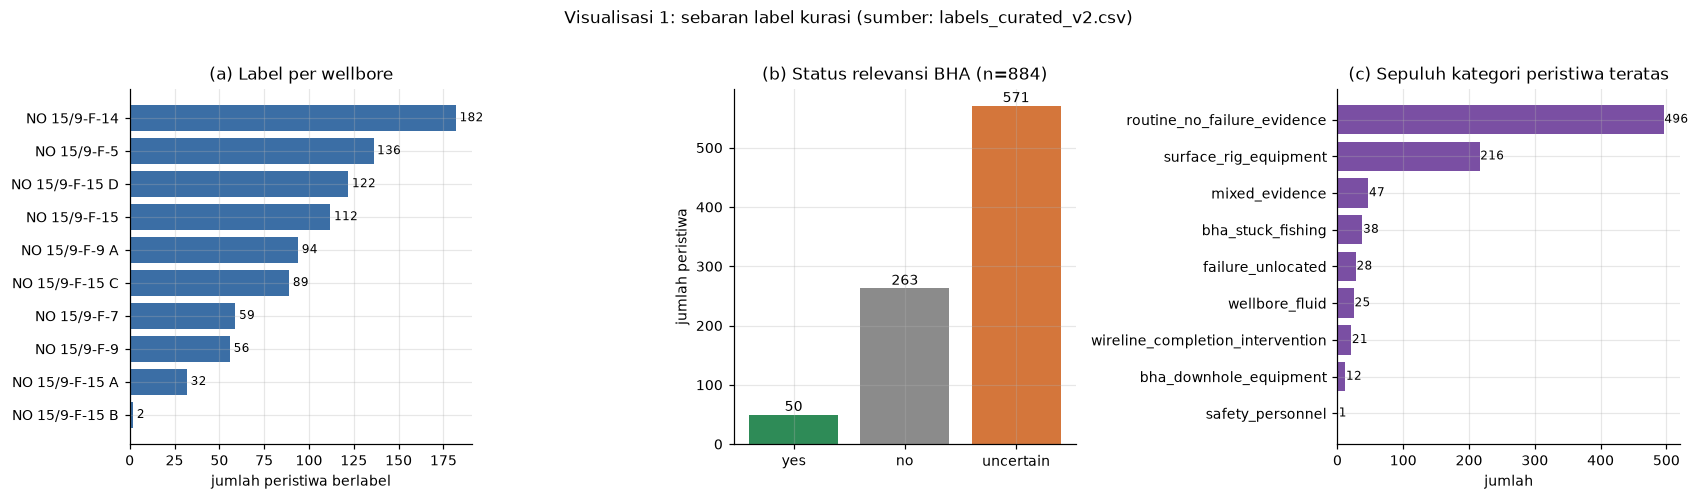

positif outcome terisi : 297 | komponen terisi: 254


In [2]:
# ============ VIS 1: DISTRIBUSI LABEL (DATA/LABELING) ============
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

# (a) label per wellbore
vc = LABELS['wellbore'].value_counts().sort_values()
axes[0].barh(vc.index, vc.values, color='#3b6ea5')
for i, v in enumerate(vc.values):
    axes[0].text(v + 2, i, str(v), va='center', fontsize=8)
axes[0].set_title('(a) Label per wellbore')
axes[0].set_xlabel('jumlah peristiwa berlabel')

# (b) status relevansi BHA (hasil kurasi)
bha = LABELS['bha_relevant'].value_counts()
order = [k for k in ['yes', 'no', 'uncertain'] if k in bha.index]
colmap = {'yes': '#2e8b57', 'no': '#8b8b8b', 'uncertain': '#d4763b'}
axes[1].bar(order, [bha[k] for k in order], color=[colmap[k] for k in order])
for i, k in enumerate(order):
    axes[1].text(i, bha[k] + 6, str(bha[k]), ha='center', fontsize=9)
axes[1].set_title('(b) Status relevansi BHA (n=884)')
axes[1].set_ylabel('jumlah peristiwa')

# (c) kategori peristiwa teratas
cat = LABELS['category'].value_counts().head(10)[::-1]
axes[2].barh(cat.index, cat.values, color='#7a4fa3')
for i, v in enumerate(cat.values):
    axes[2].text(v + 1, i, str(v), va='center', fontsize=8)
axes[2].set_title('(c) Sepuluh kategori peristiwa teratas')
axes[2].set_xlabel('jumlah')

fig.suptitle('Visualisasi 1: sebaran label kurasi (sumber: labels_curated_v2.csv)', y=1.02, fontsize=11)
plt.tight_layout()
plt.show()
print('positif outcome terisi :', LABELS["outcome"].notna().sum(),
      '| komponen terisi:', LABELS["component"].notna().sum())

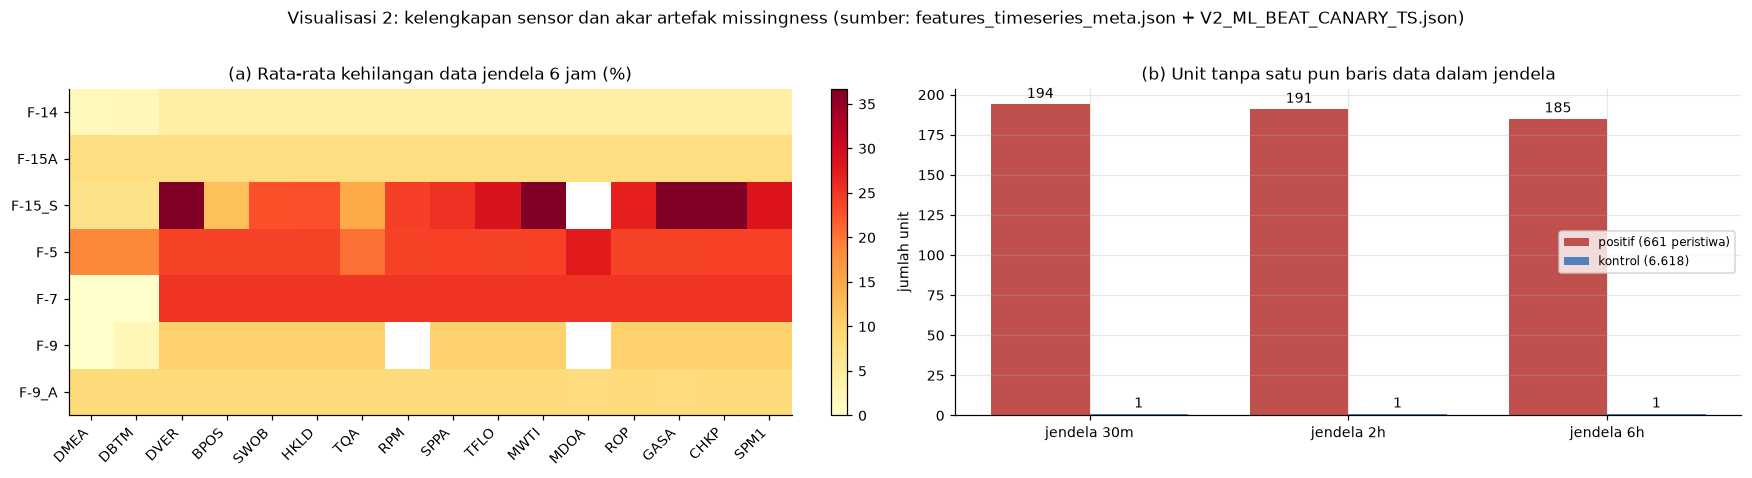

positif non-kosong ketiga jendela: 467 | total jendela-2h kosong: 192


In [3]:
# ============ VIS 2: KELENGKAPAN DATA DAN KEKOSONGAN JENDELA ============
fr = META['fill_rate_summary']
folds = [f for f in ['F-14', 'F-15A', 'F-15_S', 'F-5', 'F-7', 'F-9', 'F-9_A'] if f in fr]

def fr_val(d):
    """Ambil persentase kehilangan; tahan null/absen di JSON."""
    if not isinstance(d, dict):
        return np.nan
    v = d.get('mean_missing_rate_w6h')
    if v is None:
        return np.nan
    return float(v) * 100.0

M = np.array([[fr_val(fr[f].get(c)) for c in CHANNELS] for f in folds])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))

# (a) heatmap kelengkapan per sumur x kanal
im = axes[0].imshow(M, cmap='YlOrRd', aspect='auto', vmin=0)
axes[0].set_xticks(range(len(CHANNELS)), CHANNELS, rotation=45, ha='right')
axes[0].set_yticks(range(len(folds)), folds)
axes[0].set_title('(a) Rata-rata kehilangan data jendela 6 jam (%)')
axes[0].grid(False)
plt.colorbar(im, ax=axes[0], fraction=0.03)

# (b) unit dengan jendela kosong per kelas (kampanye T2-e primer)
kj = J_T2E['kekosongan_jendela']
wins = ['30m', '2h', '6h']
pos_kos = [kj['positif'][f'jendela_{w}_kosong'] for w in wins]
neg_kos = [kj['negatif_kontrol_kampanye_asli'][f'jendela_{w}_kosong'] for w in wins]
x = np.arange(len(wins)); w = 0.38
axes[1].bar(x - w/2, pos_kos, w, label='positif (661 peristiwa)', color='#c0504d')
axes[1].bar(x + w/2, neg_kos, w, label='kontrol (6.618)', color='#4f81bd')
for i, v in enumerate(pos_kos):
    axes[1].text(i - w/2, v + 4, str(v), ha='center', fontsize=9)
for i, v in enumerate(neg_kos):
    axes[1].text(i + w/2, v + 4, str(v), ha='center', fontsize=9)
axes[1].set_xticks(x, [f'jendela {w}' for w in wins])
axes[1].set_title('(b) Unit tanpa satu pun baris data dalam jendela')
axes[1].set_ylabel('jumlah unit')
axes[1].legend(fontsize=8)

fig.suptitle('Visualisasi 2: kelengkapan sensor dan akar artefak missingness '
             '(sumber: features_timeseries_meta.json + V2_ML_BEAT_CANARY_TS.json)', y=1.02, fontsize=11)
plt.tight_layout()
plt.show()
print('positif non-kosong ketiga jendela:', kj['positif']['non_kosong_semua'],
      '| total jendela-2h kosong:', kj['total_jendela_2h_kosong'])

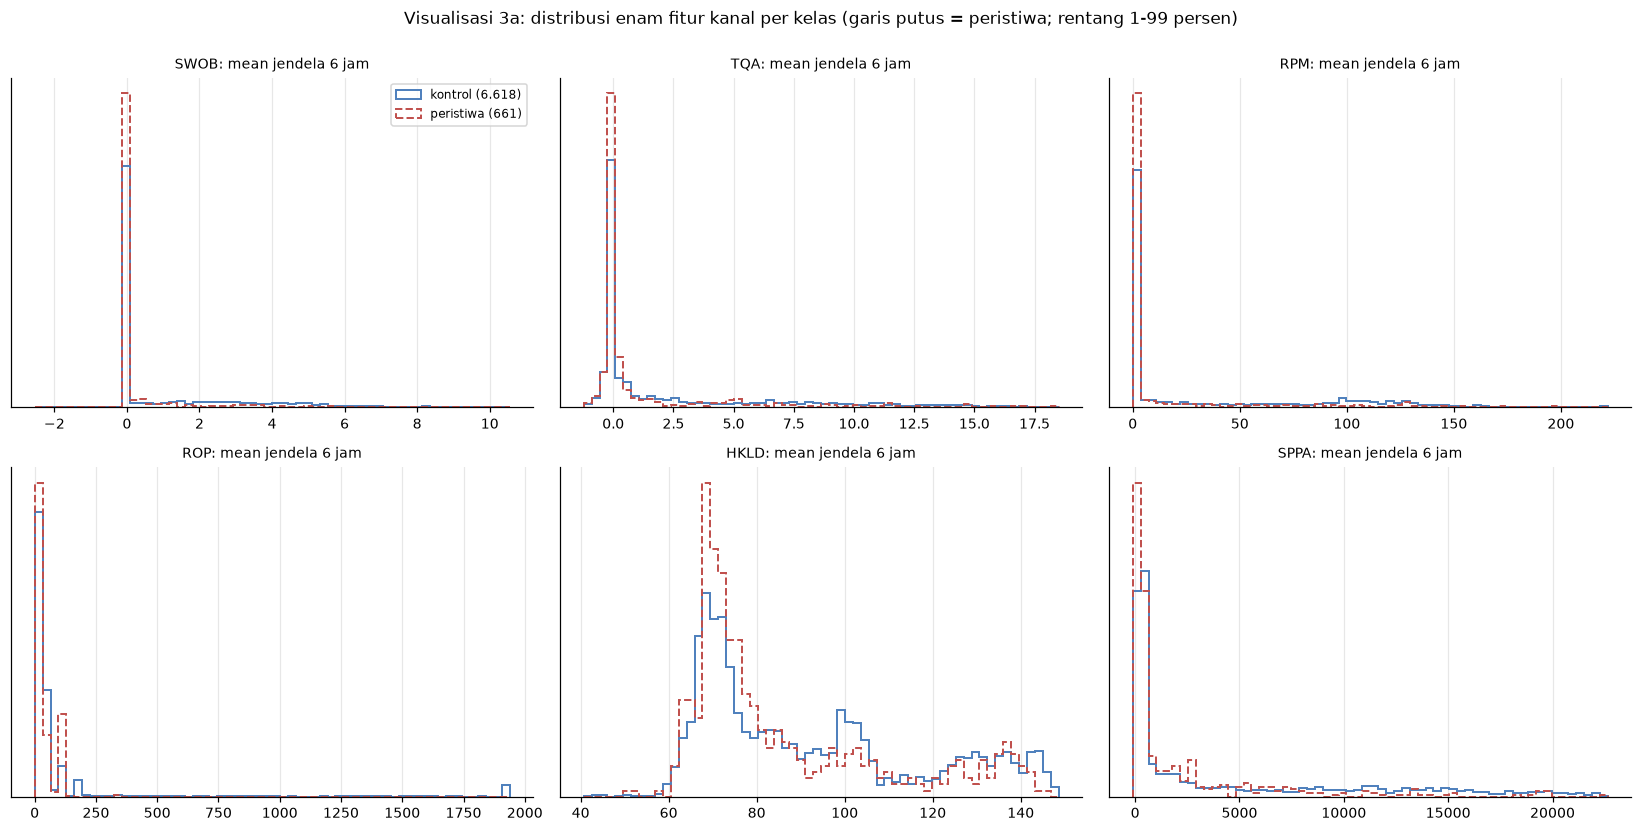

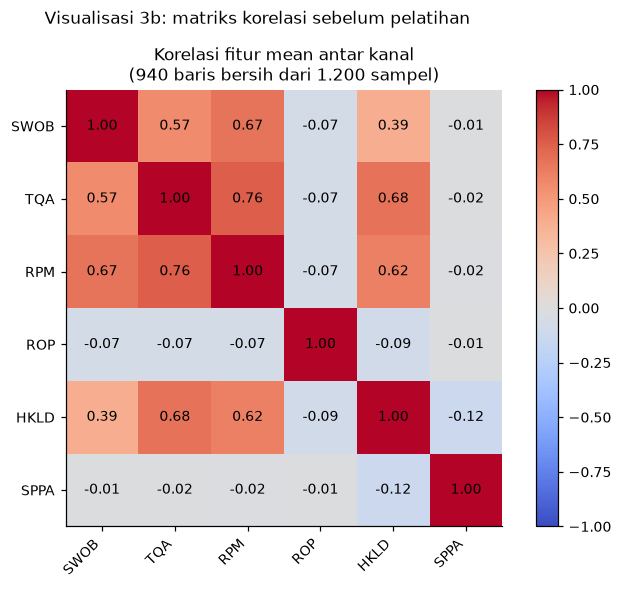

In [4]:
# ============ VIS 3: DISTRIBUSI FITUR DAN KORELASI ANTAR KANAL ============
chs = ['SWOB', 'TQA', 'RPM', 'ROP', 'HKLD', 'SPPA']

def col(X, ch):
    return X[:, FEATURE_NAMES.index(f'w6h__{ch}__mean')]

# (a) enam panel kecil: masing-masing kanal dengan skala sendiri
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, ch in zip(axes.ravel(), chs):
    vp, vn = col(ZPOS['X'], ch), col(ZNEG['X'], ch)
    v = np.concatenate([vp, vn]); v = v[~np.isnan(v)]
    lo, hi = np.percentile(v, [1, 99])      # pangkas outlier agar skala terbaca
    ax.hist(vn, bins=60, range=(lo, hi), density=True, histtype='step',
            lw=1.3, color='#4f81bd', label='kontrol (6.618)')
    ax.hist(vp, bins=60, range=(lo, hi), density=True, histtype='step',
            lw=1.3, ls='--', color='#c0504d', label='peristiwa (661)')
    ax.set_title(f'{ch}: mean jendela 6 jam', fontsize=9)
    ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
fig.suptitle('Visualisasi 3a: distribusi enam fitur kanal per kelas '
             '(garis putus = peristiwa; rentang 1-99 persen)', y=1.00, fontsize=11)
plt.tight_layout()
plt.show()

# (b) korelasi antar kanal pada baris bersih (NaN dibuang dulu)
rng = np.random.default_rng(42)
ip = rng.choice(len(ZPOS['X']), 600, replace=False)
in_ = rng.choice(len(ZNEG['X']), 600, replace=False)
samp = np.vstack([ZPOS['X'][ip], ZNEG['X'][in_]])
A = np.column_stack([col(samp, c) for c in chs])
clean = A[~np.isnan(A).any(axis=1)]
C = np.corrcoef(clean.T)

fig, ax = plt.subplots(figsize=(6.8, 5.4))
im = ax.imshow(C, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(chs)), chs, rotation=45, ha='right')
ax.set_yticks(range(len(chs)), chs)
for i in range(len(chs)):
    for j in range(len(chs)):
        ax.text(j, i, f'{C[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_title(f'Korelasi fitur mean antar kanal\n({len(clean)} baris bersih dari 1.200 sampel)')
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle('Visualisasi 3b: matriks korelasi sebelum pelatihan', y=0.98, fontsize=11)
plt.tight_layout()
plt.show()

unit: 7279 | prevalensi: 0.0908 | fold: [np.str_('F-14'), np.str_('F-15A'), np.str_('F-15_S'), np.str_('F-5'), np.str_('F-7'), np.str_('F-9'), np.str_('F-9_A')]


  fold F-14    : n_test= 1770  AUPRC=0.4661


  fold F-15A   : n_test=  476  AUPRC=0.0733


  fold F-15_S  : n_test= 1010  AUPRC=0.2226


  fold F-5     : n_test=  944  AUPRC=0.1768


  fold F-7     : n_test=  429  AUPRC=0.4651


  fold F-9     : n_test=  602  AUPRC=0.5990


  fold F-9_A   : n_test= 2048  AUPRC=0.8917
POOLED: AUPRC=0.3929 (baseline prevalensi=0.0908) | ROC-AUC=0.6487 | Brier=0.0647


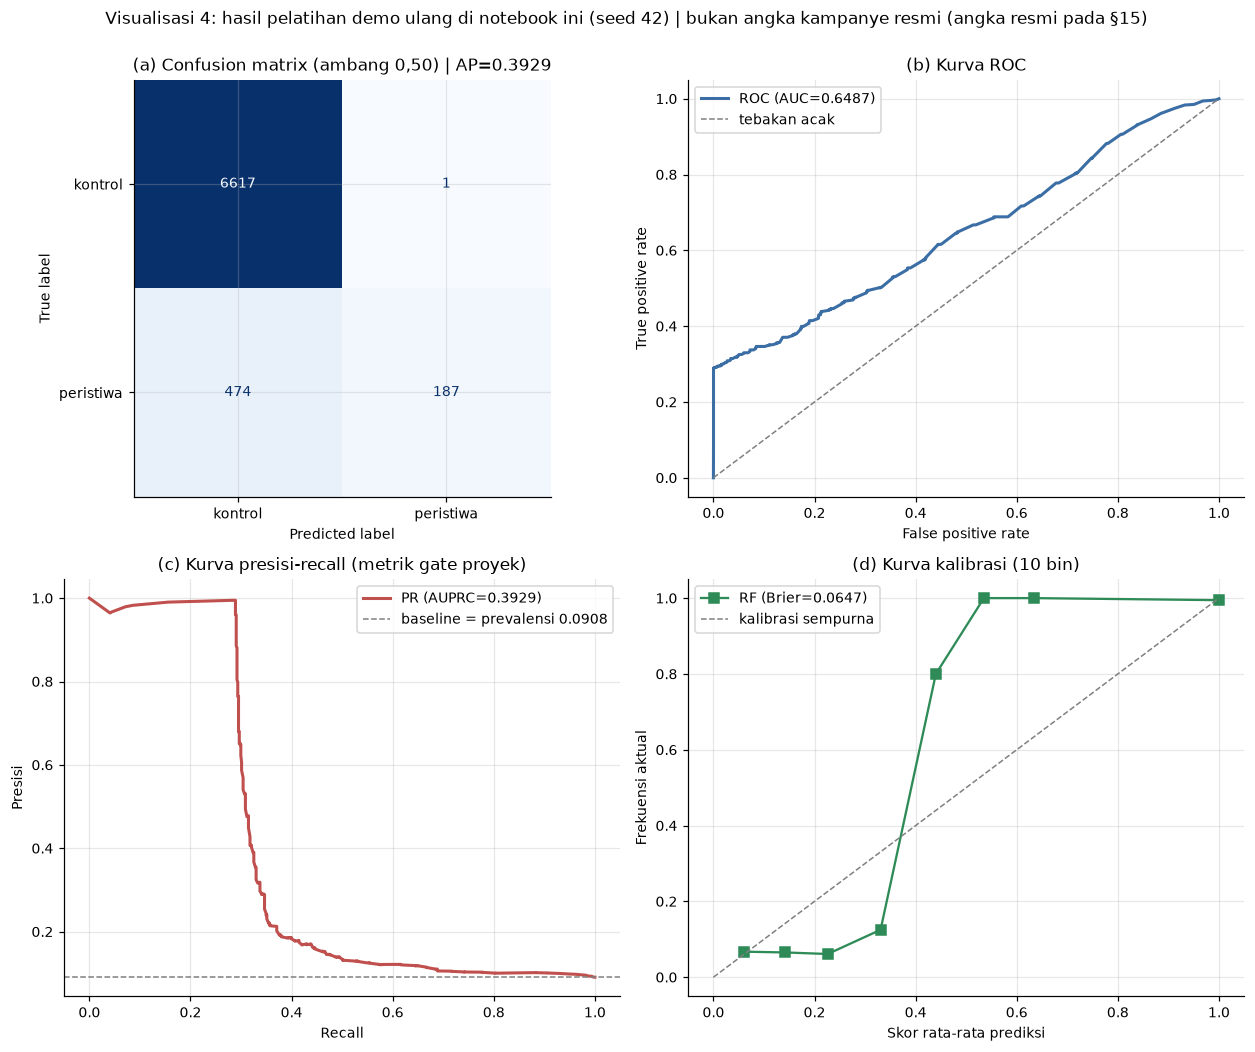

In [5]:
# ============ VIS 4: PELATIHAN LOWO + CONFUSION MATRIX / ROC / PR / KALIBRASI ============
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay,
                             brier_score_loss)

# unit demo = seluruh peristiwa (661) + seluruh kontrol (6.618)
X = np.vstack([ZPOS['X'], ZNEG['X']]).astype('float32')
y = np.concatenate([np.ones(len(ZPOS['X']), dtype=int),
                    np.zeros(len(ZNEG['X']), dtype=int)])
fold = np.concatenate([np.array([str(f) for f in ZPOS['fold']]),
                       np.array([str(f) for f in ZNEG['fold']])])
folds = sorted(set(fold))

imputer = SimpleImputer(strategy='median')
X_imp = imputer.fit_transform(X)          # dipakai ulang sel visualisasi berikutnya
oof = np.zeros(len(y))
print('unit:', len(y), '| prevalensi:', round(y.mean(), 4), '| fold:', folds)
for f in folds:
    tr, te = (fold != f), (fold == f)
    rf = RandomForestClassifier(n_estimators=200, random_state=42,
                                n_jobs=-1, class_weight='balanced_subsample')
    rf.fit(X_imp[tr], y[tr])
    oof[te] = rf.predict_proba(X_imp[te])[:, 1]
    print(f'  fold {f:8s}: n_test={int(te.sum()):5d}  AUPRC={average_precision_score(y[te], oof[te]):.4f}')

ap  = average_precision_score(y, oof)
auc = roc_auc_score(y, oof)
bri = brier_score_loss(y, oof)
print(f'POOLED: AUPRC={ap:.4f} (baseline prevalensi={y.mean():.4f}) | ROC-AUC={auc:.4f} | Brier={bri:.4f}')

fig, axes = plt.subplots(2, 2, figsize=(11.5, 9.5))

# (a) confusion matrix pada ambang 0,5
cm = confusion_matrix(y, (oof >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['kontrol', 'peristiwa']).plot(
    ax=axes[0, 0], cmap='Blues', colorbar=False, values_format='d')
axes[0, 0].set_title(f'(a) Confusion matrix (ambang 0,50) | AP={ap:.4f}')

# (b) kurva ROC
fpr, tpr, _ = roc_curve(y, oof)
axes[0, 1].plot(fpr, tpr, color='#3b6ea5', lw=2, label=f'ROC (AUC={auc:.4f})')
axes[0, 1].plot([0, 1], [0, 1], ls='--', c='gray', lw=1, label='tebakan acak')
axes[0, 1].set_xlabel('False positive rate'); axes[0, 1].set_ylabel('True positive rate')
axes[0, 1].set_title('(b) Kurva ROC'); axes[0, 1].legend(fontsize=9)

# (c) kurva presisi-recall (metrik utama proyek)
prec, rec, _ = precision_recall_curve(y, oof)
axes[1, 0].plot(rec, prec, color='#c0504d', lw=2, label=f'PR (AUPRC={ap:.4f})')
axes[1, 0].axhline(y.mean(), ls='--', c='gray', lw=1, label=f'baseline = prevalensi {y.mean():.4f}')
axes[1, 0].set_xlabel('Recall'); axes[1, 0].set_ylabel('Presisi')
axes[1, 0].set_title('(c) Kurva presisi-recall (metrik gate proyek)')
axes[1, 0].legend(fontsize=9)

# (d) kurva kalibrasi
frac_pos, mean_pred = calibration_curve(y, oof, n_bins=10)
axes[1, 1].plot(mean_pred, frac_pos, 's-', color='#2e8b57', label=f'RF (Brier={bri:.4f})')
axes[1, 1].plot([0, 1], [0, 1], ls='--', c='gray', lw=1, label='kalibrasi sempurna')
axes[1, 1].set_xlabel('Skor rata-rata prediksi'); axes[1, 1].set_ylabel('Frekuensi aktual')
axes[1, 1].set_title('(d) Kurva kalibrasi (10 bin)')
axes[1, 1].legend(fontsize=9)

fig.suptitle('Visualisasi 4: hasil pelatihan demo ulang di notebook ini (seed 42) | '
             'bukan angka kampanye resmi (angka resmi pada §15)', y=1.00, fontsize=11)
plt.tight_layout()
plt.show()

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

... (3 outputs left out)

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

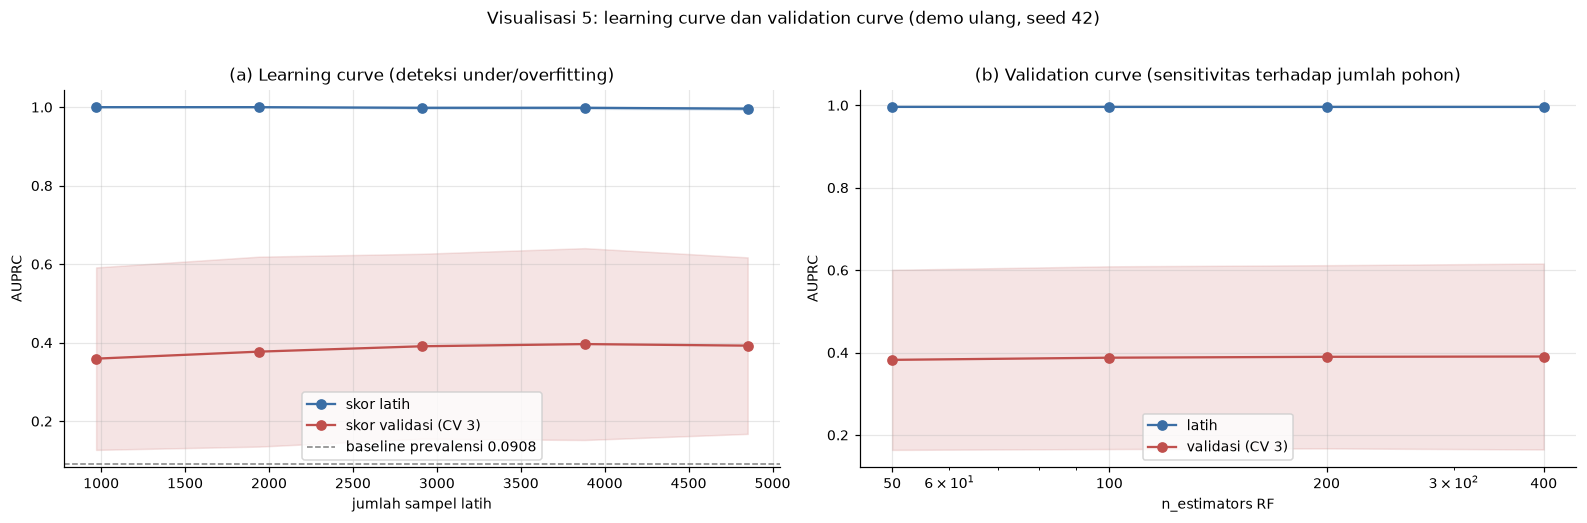

selisih latih-validasi pada data terbesar: 0.6037


In [6]:
# ============ VIS 5: LEARNING CURVE DAN VALIDATION CURVE ============
from sklearn.model_selection import learning_curve, validation_curve

train_sizes = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
sizes, trn, val = learning_curve(
    RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1,
                           class_weight='balanced_subsample'),
    X_imp, y, train_sizes=train_sizes, cv=3,
    scoring='average_precision', n_jobs=-1, random_state=42)

n_range = [50, 100, 200, 400]
trn2, val2 = validation_curve(
    RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced_subsample'),
    X_imp, y, param_name='n_estimators', param_range=n_range, cv=3,
    scoring='average_precision', n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))

# (a) learning curve: skor vs jumlah data latih
axes[0].plot(sizes, trn.mean(axis=1), 'o-', color='#3b6ea5', label='skor latih')
axes[0].fill_between(sizes, trn.mean(axis=1) - trn.std(axis=1),
                     trn.mean(axis=1) + trn.std(axis=1), alpha=0.15, color='#3b6ea5')
axes[0].plot(sizes, val.mean(axis=1), 'o-', color='#c0504d', label='skor validasi (CV 3)')
axes[0].fill_between(sizes, val.mean(axis=1) - val.std(axis=1),
                     val.mean(axis=1) + val.std(axis=1), alpha=0.15, color='#c0504d')
axes[0].axhline(y.mean(), ls='--', c='gray', lw=1, label=f'baseline prevalensi {y.mean():.4f}')
axes[0].set_xlabel('jumlah sampel latih'); axes[0].set_ylabel('AUPRC')
axes[0].set_title('(a) Learning curve (deteksi under/overfitting)')
axes[0].legend(fontsize=9)

# (b) validation curve: skor vs hyperparameter
axes[1].plot(n_range, trn2.mean(axis=1), 'o-', color='#3b6ea5', label='latih')
axes[1].plot(n_range, val2.mean(axis=1), 'o-', color='#c0504d', label='validasi (CV 3)')
axes[1].fill_between(n_range, val2.mean(axis=1) - val2.std(axis=1),
                     val2.mean(axis=1) + val2.std(axis=1), alpha=0.15, color='#c0504d')
axes[1].set_xscale('log'); axes[1].set_xticks(n_range, [str(n) for n in n_range])
axes[1].set_xlabel('n_estimators RF'); axes[1].set_ylabel('AUPRC')
axes[1].set_title('(b) Validation curve (sensitivitas terhadap jumlah pohon)')
axes[1].legend(fontsize=9)

fig.suptitle('Visualisasi 5: learning curve dan validation curve (demo ulang, seed 42)', y=1.02, fontsize=11)
plt.tight_layout()
plt.show()
print('selisih latih-validasi pada data terbesar:',
      round(float(trn.mean(axis=1)[-1] - val.mean(axis=1)[-1]), 4))

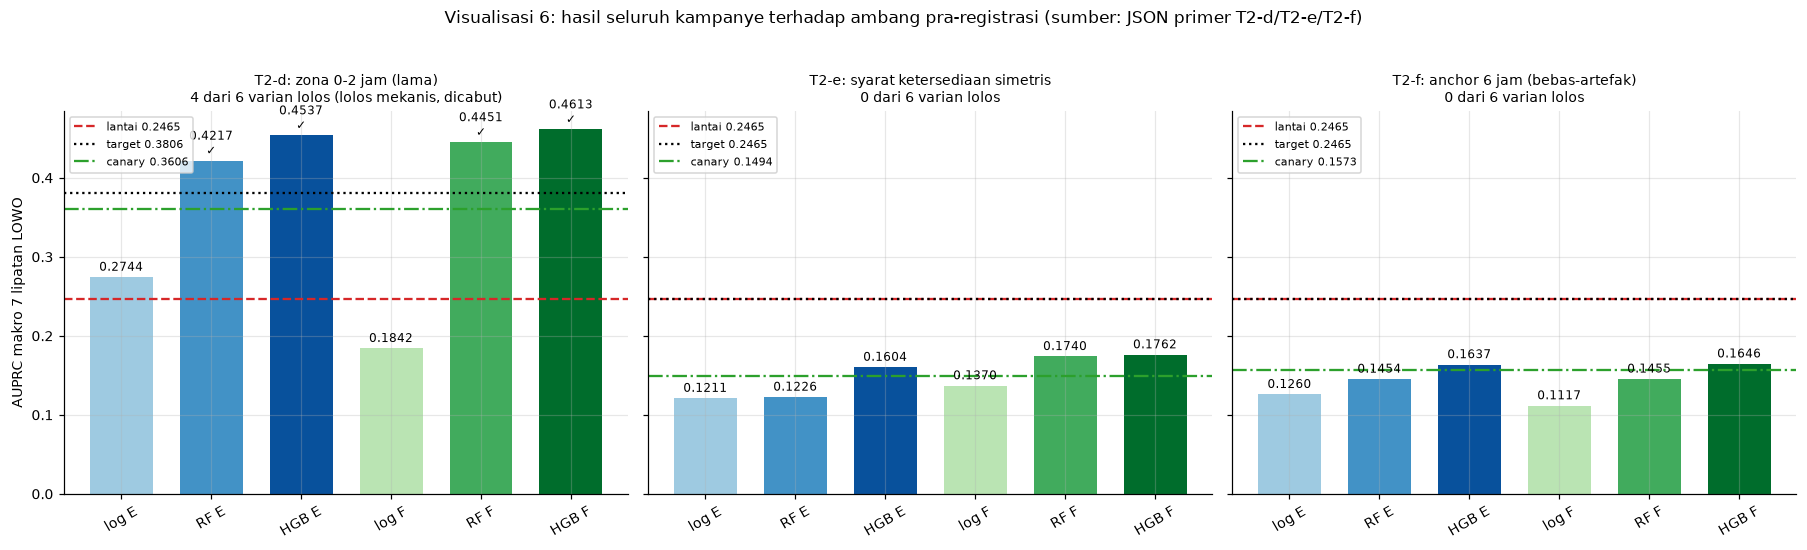

In [7]:
# ============ VIS 6: PERBANDINGAN ANTAR KAMPANYE VS AMBANG ============
def gate_of(j, p4=False):
    g = (j['p4_desain_baru'] if p4 else j)['gate']
    return g

gates = [
    ('T2-d: zona 0-2 jam (lama)', J_T2D['gate'], True),
    ('T2-e: syarat ketersediaan simetris', gate_of(J_T2E, p4=True), False),
    ('T2-f: anchor 6 jam (bebas-artefak)', J_T2F['gate'], False),
]
order_var = ['log_E', 'rf_E', 'hgb_E', 'log_F', 'rf_F', 'hgb_F']
label_var = ['log E', 'RF E', 'HGB E', 'log F', 'RF F', 'HGB F']
col_var   = ['#9ecae1', '#4292c6', '#08519c', '#bae4b3', '#41ab5d', '#006d2c']

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), sharey=True)
for ax, (title, g, mekanis) in zip(axes, gates):
    pv = g['per_variant']
    vals = [pv[v]['macro'] if v in pv else np.nan for v in order_var]
    bars = ax.bar(label_var, vals, color=col_var, width=0.7)
    for b, v, var in zip(bars, vals, order_var):
        lolos = pv[var].get('LOLOS', False)
        ax.text(b.get_x() + b.get_width()/2, v + 0.008, f'{v:.4f}' + ('\n✓' if lolos else ''),
                ha='center', fontsize=8)
    ax.axhline(g['floor'], ls='--', c='#d62728', lw=1.5, label=f"lantai {g['floor']}")
    ax.axhline(g['target_macro'], ls=':', c='black', lw=1.5, label=f"target {g['target_macro']}")
    ax.axhline(g['canary_macro'], ls='-.', c='#2ca02c', lw=1.5, label=f"canary {g['canary_macro']}")
    n_lolos = sum(1 for v in order_var if pv.get(v, {}).get('LOLOS', False))
    ax.set_title(f"{title}\n{n_lolos} dari 6 varian lolos"
                 + (' (lolos mekanis, dicabut)' if mekanis else ''), fontsize=9)
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=7.5, loc='upper left')
axes[0].set_ylabel('AUPRC makro 7 lipatan LOWO')

fig.suptitle('Visualisasi 6: hasil seluruh kampanye terhadap ambang pra-registrasi '
             '(sumber: JSON primer T2-d/T2-e/T2-f)', y=1.03, fontsize=11)
plt.tight_layout()
plt.show()

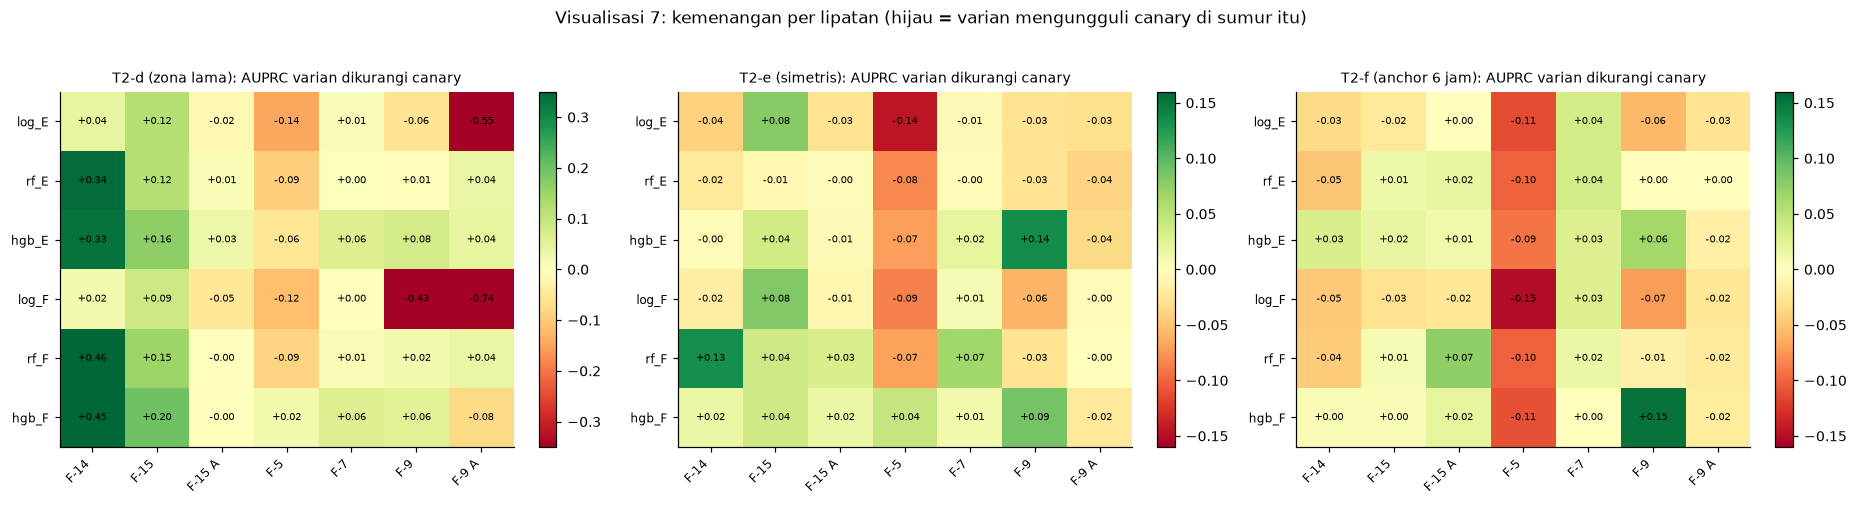

In [8]:
# ============ VIS 7: HEATMAP SELISIH PER LIPATAN (DELTA vs CANARY) ============
import pandas as pd

def delta_df(g):
    rows = {}
    for v, d in g['per_variant'].items():
        rows[v] = {k.replace('NO 15/9-', ''): val for k, val in d['delta_per_fold'].items()}
    return pd.DataFrame(rows).T

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
panels = [('T2-d (zona lama)', J_T2D['gate'], 0.35),
          ('T2-e (simetris)', gate_of(J_T2E, p4=True), 0.16),
          ('T2-f (anchor 6 jam)', J_T2F['gate'], 0.16)]
for ax, (title, g, vmax) in zip(axes, panels):
    D = delta_df(g)
    im = ax.imshow(D.values, cmap='RdYlGn', vmin=-vmax, vmax=vmax, aspect='auto')
    ax.set_xticks(range(D.shape[1]), D.columns, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(D.shape[0]), D.index, fontsize=8)
    for i in range(D.shape[0]):
        for j in range(D.shape[1]):
            ax.text(j, i, f'{D.values[i, j]:+.2f}', ha='center', va='center', fontsize=6.5)
    ax.set_title(f'{title}: AUPRC varian dikurangi canary', fontsize=9)
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle('Visualisasi 7: kemenangan per lipatan (hijau = varian mengungguli canary di sumur itu)',
             y=1.03, fontsize=11)
plt.tight_layout()
plt.show()

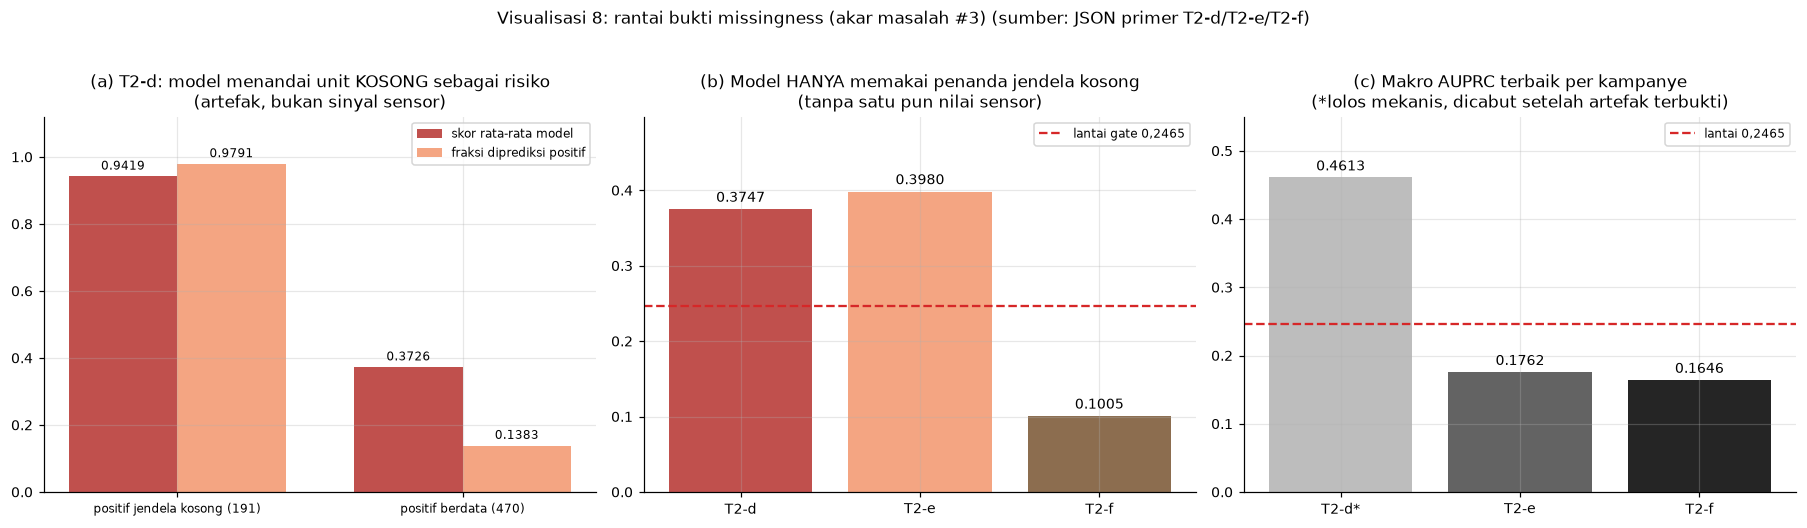

makro terbaik: {'T2-d': 0.4613, 'T2-e': 0.1762, 'T2-f': 0.1646}


In [9]:
# ============ VIS 8: BUKTI ARTEFAK MISSINGNESS DAN JATUHNYA MAKRO ============
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

# (a) T2-d: skor model pada positif window-kosong vs positif berdata
d = J_T2D['diagnostics']
labels_ab = ['positif jendela kosong (191)', 'positif berdata (470)']
score = [d['score_pos_empty_window'], d['score_pos_with_data']]
prate = [d['pred_rate_pos_empty_window'], d['pred_rate_pos_with_data']]
x = np.arange(2); w = 0.38
axes[0].bar(x - w/2, score, w, label='skor rata-rata model', color='#c0504d')
axes[0].bar(x + w/2, prate, w, label='fraksi diprediksi positif', color='#f4a582')
for i in range(2):
    axes[0].text(i - w/2, score[i] + 0.02, f'{score[i]:.4f}', ha='center', fontsize=8)
    axes[0].text(i + w/2, prate[i] + 0.02, f'{prate[i]:.4f}', ha='center', fontsize=8)
axes[0].set_xticks(x, labels_ab, fontsize=8)
axes[0].set_ylim(0, 1.12)
axes[0].set_title('(a) T2-d: model menandai unit KOSONG sebagai risiko\n(artefak, bukan sinyal sensor)')
axes[0].legend(fontsize=8)

# (b) baseline missingness-only per kampanye
mv = {}
try:
    mv['T2-d'] = J_T2D['sensitivity'].get('missingness_only_macro_pr_auc')
except Exception:
    pass
try:
    mv['T2-e'] = (J_T2E['p4_desain_baru']['sensitivity'] or {}).get('missingness_only_macro_pr_auc')
except Exception:
    pass
try:
    mv['T2-f'] = J_T2F['diagnostics']['missingness_only']['macro']
except Exception:
    pass
mv = {k: v for k, v in mv.items() if v is not None}
if mv:
    b = axes[1].bar(list(mv.keys()), list(mv.values()), color=['#c0504d', '#f4a582', '#8c6d4f'][:len(mv)])
    for r, v in zip(b, mv.values()):
        axes[1].text(r.get_x() + r.get_width()/2, v + 0.01, f'{v:.4f}', ha='center', fontsize=9)
    axes[1].axhline(0.2465, ls='--', c='#d62728', label='lantai gate 0,2465')
    axes[1].set_ylim(0, max(list(mv.values()) + [0.2465]) * 1.25)
    axes[1].legend(fontsize=8)
else:
    axes[1].text(0.5, 0.5, 'missingness-only\ntidak tercatat di JSON', ha='center', transform=axes[1].transAxes)
axes[1].set_title('(b) Model HANYA memakai penanda jendela kosong\n(tanpa satu pun nilai sensor)')

# (c) makro terbaik per kampanye vs lantai
best = [max(J_T2D['gate']['per_variant'][v]['macro'] for v in J_T2D['gate']['per_variant']),
        max(J_T2E['p4_desain_baru']['gate']['per_variant'][v]['macro']
            for v in J_T2E['p4_desain_baru']['gate']['per_variant']),
        max(J_T2F['gate']['per_variant'][v]['macro'] for v in J_T2F['gate']['per_variant'])]
b = axes[2].bar(['T2-d*', 'T2-e', 'T2-f'], best, color=['#bdbdbd', '#636363', '#252525'])
for r, v in zip(b, best):
    axes[2].text(r.get_x() + r.get_width()/2, v + 0.01, f'{v:.4f}', ha='center', fontsize=9)
axes[2].axhline(0.2465, ls='--', c='#d62728', label='lantai 0,2465')
axes[2].set_ylim(0, 0.55)
axes[2].set_title('(c) Makro AUPRC terbaik per kampanye\n(*lolos mekanis, dicabut setelah artefak terbukti)')
axes[2].legend(fontsize=8)

fig.suptitle('Visualisasi 8: rantai bukti missingness (akar masalah #3) '
             '(sumber: JSON primer T2-d/T2-e/T2-f)', y=1.03, fontsize=11)
plt.tight_layout()
plt.show()
print('makro terbaik:', {k: round(v, 4) for k, v in zip(['T2-d', 'T2-e', 'T2-f'], best)})

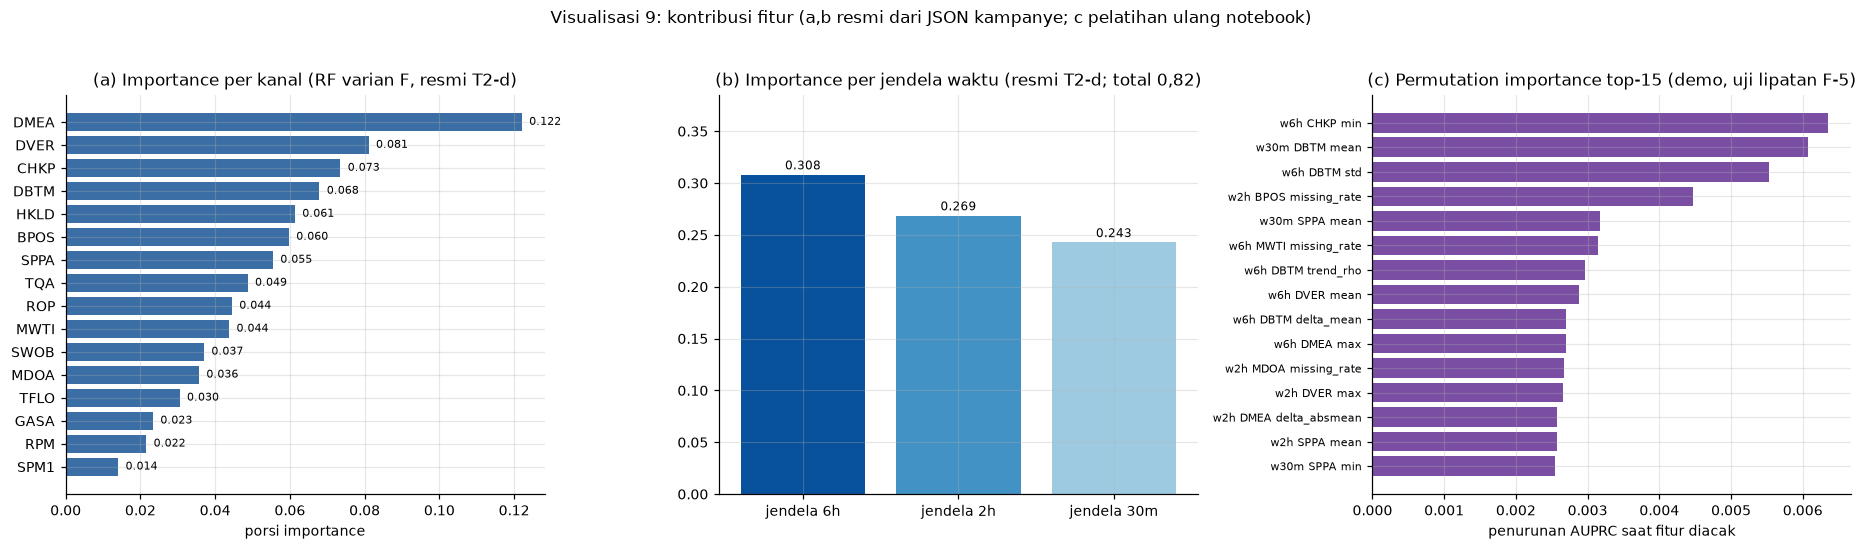

In [10]:
# ============ VIS 9: FEATURE IMPORTANCE (RESMI) DAN PERMUTATION IMPORTANCE ============
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) importance resmi T2-d varian rf_F per kanal (JSON primer, bukan hitung ulang)
imp = J_T2D['importances']['rf_F']['per_group']
ch_vals = sorted(((k[3:], v) for k, v in imp.items() if k.startswith('ch:')),
                 key=lambda t: t[1])
axes[0].barh([c for c, _ in ch_vals], [v for _, v in ch_vals], color='#3b6ea5')
for i, (_, v) in enumerate(ch_vals):
    axes[0].text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=7)
axes[0].set_title('(a) Importance per kanal (RF varian F, resmi T2-d)')
axes[0].set_xlabel('porsi importance')

# (b) importance per jendela waktu (resmi)
pw = J_T2D['importances']['rf_F']['per_window']
keys = sorted(pw, key=lambda k: -pw[k])
axes[1].bar([k.replace('w', 'jendela ') for k in keys], [pw[k] for k in keys],
            color=['#08519c', '#4292c6', '#9ecae1'][:len(keys)])
for i, k in enumerate(keys):
    axes[1].text(i, pw[k] + 0.005, f'{pw[k]:.3f}', ha='center', fontsize=8)
axes[1].set_ylim(0, max(pw.values()) * 1.25)
axes[1].set_title('(b) Importance per jendela waktu (resmi T2-d; total 0,82)')

# (c) permutation importance (demo ulang, lipatan F-5)
te = fold == 'F-5'
tr = ~te
rf_c = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1,
                              class_weight='balanced_subsample')
rf_c.fit(X_imp[tr], y[tr])
pi = permutation_importance(rf_c, X_imp[te], y[te], n_repeats=5,
                            random_state=42, scoring='average_precision', n_jobs=-1)
order = np.argsort(pi.importances_mean)[-15:][::-1]
axes[2].barh([FEATURE_NAMES[i].replace('__', ' ') for i in order][::-1],
             pi.importances_mean[order][::-1], color='#7a4fa3')
axes[2].set_title('(c) Permutation importance top-15 (demo, uji lipatan F-5)')
axes[2].set_xlabel('penurunan AUPRC saat fitur diacak')
axes[2].tick_params(axis='y', labelsize=7)

fig.suptitle('Visualisasi 9: kontribusi fitur (a,b resmi dari JSON kampanye; c pelatihan ulang notebook)',
             y=1.03, fontsize=11)
plt.tight_layout()
plt.show()

/home/neonti/.hermes/tools/python-3.14.7+20260901-linux-x64/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/neonti/.hermes/cache/scratch/ipykernel_363002/1847987931.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xs, feature_names=FEATURE_NAMES, max_display=20, show=False)


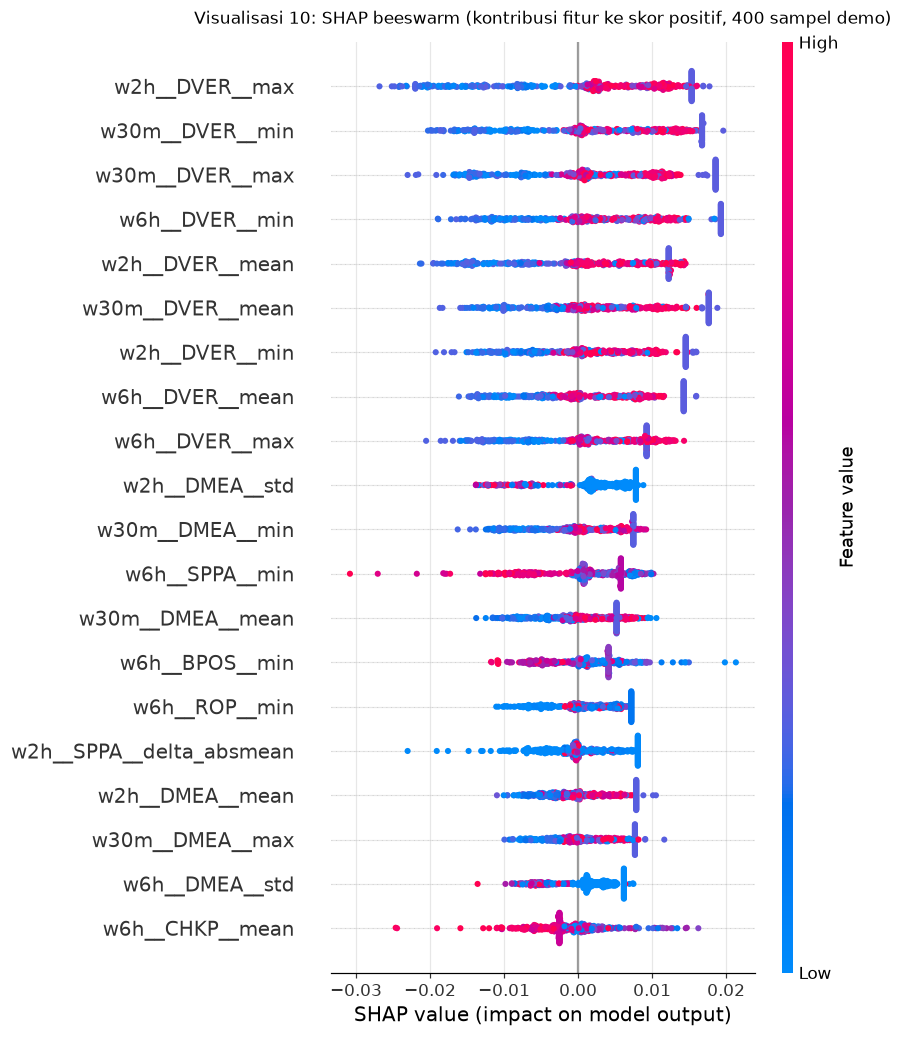

bentuk shap_values: (400, 480)


In [11]:
# ============ VIS 10: SHAP BEESWARM (INTERPRETASI KESELURUHAN MODEL) ============
import shap

rf_all = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1,
                                class_weight='balanced_subsample')
rf_all.fit(X_imp, y)

explainer = shap.TreeExplainer(rf_all)
rng = np.random.default_rng(7)
ip = rng.choice(np.where(y == 1)[0], 200, replace=False)
in_ = rng.choice(np.where(y == 0)[0], 200, replace=False)
idx = np.concatenate([ip, in_])
Xs = X_imp[idx]

sv = explainer.shap_values(Xs)
if isinstance(sv, list):          # API lama: list per kelas
    sv = sv[1]
sv = np.asarray(sv)
if sv.ndim == 3:                  # API baru: (n, fitur, kelas) -> ambil kelas positif
    sv = sv[:, :, 1]
plt.figure(figsize=(10, 6))
shap.summary_plot(sv, Xs, feature_names=FEATURE_NAMES, max_display=20, show=False)
plt.title('Visualisasi 10: SHAP beeswarm (kontribusi fitur ke skor positif, 400 sampel demo)',
          fontsize=11, pad=12)
plt.tight_layout()
plt.show()
print('bentuk shap_values:', np.shape(sv))

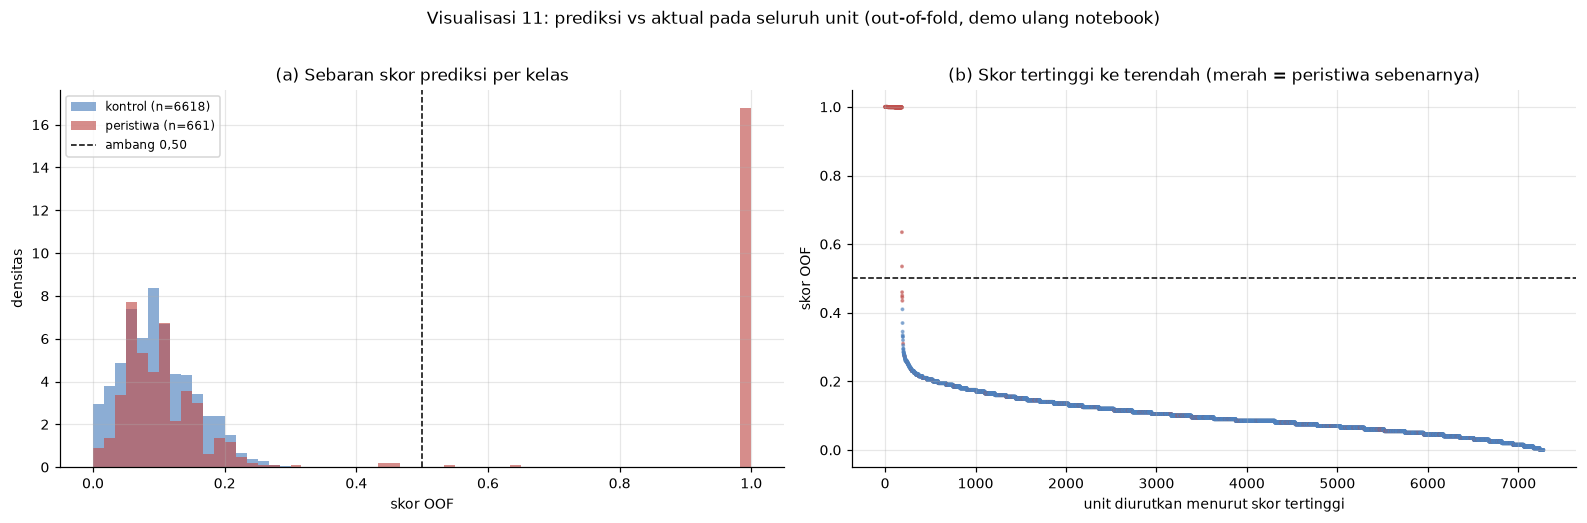

proporsi peristiwa di 661 skor tertinggi: 0.3298 (baseline = 0.0908)


In [12]:
# ============ VIS 11: PREDIKSI vs AKTUAL (SKOR OOF) ============
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))

# (a) distribusi skor OOF per kelas
axes[0].hist(oof[y == 0], bins=60, alpha=0.65, density=True,
             color='#4f81bd', label=f'kontrol (n={(y == 0).sum()})')
axes[0].hist(oof[y == 1], bins=60, alpha=0.65, density=True,
             color='#c0504d', label=f'peristiwa (n={(y == 1).sum()})')
axes[0].axvline(0.5, ls='--', c='black', lw=1, label='ambang 0,50')
axes[0].set_xlabel('skor OOF'); axes[0].set_ylabel('densitas')
axes[0].set_title('(a) Sebaran skor prediksi per kelas')
axes[0].legend(fontsize=8)

# (b) skor terurut menurun: merah = peristiwa nyata harus berada di kiri atas
order = np.argsort(-oof)
cols = np.where(y[order] == 1, '#c0504d', '#4f81bd')
axes[1].scatter(np.arange(len(oof)), oof[order], s=2.5, c=cols, alpha=0.55)
axes[1].axhline(0.5, ls='--', c='black', lw=1)
axes[1].set_xlabel('unit diurutkan menurut skor tertinggi')
axes[1].set_ylabel('skor OOF')
axes[1].set_title('(b) Skor tertinggi ke terendah (merah = peristiwa sebenarnya)')

fig.suptitle('Visualisasi 11: prediksi vs aktual pada seluruh unit (out-of-fold, demo ulang notebook)',
             y=1.02, fontsize=11)
plt.tight_layout()
plt.show()
top = oof[order][:661]
print(f'proporsi peristiwa di 661 skor tertinggi: {(y[order][:661] == 1).mean():.4f} '
      f'(baseline = {y.mean():.4f})')